# How busy will Interstate 94 be at a given hour?

**Machine Learning Assignment 1 (the ML process): regression problem.** Hourly westbound traffic on
Interstate 94 between Minneapolis and St Paul, predicted from the calendar and the weather.

<!--author-->

### How this notebook follows the assignment

| Assignment step | Section here |
|---|---|
| 1 Problem definition | 1 |
| 2 Data collection | 2 |
| 3 Data exploration and preparation: EDA, cleaning, feature engineering, splitting | 3.1 to 3.5 |
| 4 Algorithm selection | 4 |
| 5 Model development and training | 5 |
| 6 Model evaluation and hyperparameter tuning | 6.1 to 6.5 |
| Feature importance; univariate, bivariate and multivariate models (asked for by the instructor) | 6b |
| 8 Model testing and deployment | 8.1 to 8.3 |
| 10 Monitoring and maintenance | 10 |
| 11 Documentation and reporting | 11 |

The assignment sheet numbers its steps 1 to 6, 8, 10 and 11; the same numbers are used here.

**How to run it.** The notebook is self-contained: upload it alone to Google Colab or Jupyter and run all
cells. It installs what is missing, downloads the data and defines every function it uses. A full run takes
about 20 to 30 minutes on a laptop. Setting the environment variable `ML_FAST=1` gives a run of a few
minutes with tiny budgets, for checking that everything executes; its numbers mean nothing.

**Where the code comes from.** Cells that begin *"Copied from traffic_volume..."* are copied word for word
from the project's tested Python package, so this notebook and the command-line pipeline run the same
code and reach the same split and the same test results.

**Numbers in the text.** No result is typed by hand. Every sentence that contains a result is generated
from the value computed in the cell above it, so the text cannot disagree with the tables.

**A note on the test year.** The 2018 test year has been scored twice. After the first evaluation a review
found four defects, which were fixed using training and validation data only. Section 8.1 reports both
evaluations side by side.

## 0. Setup

Installs only what is missing; packages already present (for example on Colab) are left alone. The versions
actually used are printed, and the exact versions behind the saved results are pinned in the project's
`pyproject.toml`.

In [1]:
import importlib.util
import subprocess
import sys
import warnings

REQUIRED = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "matplotlib": "matplotlib",
            "sklearn": "scikit-learn", "joblib": "joblib", "seaborn": "seaborn", "yaml": "PyYAML",
            "lightgbm": "lightgbm", "optuna": "optuna", "shap": "shap", "statsmodels": "statsmodels",
            "onnx": "onnx", "onnxruntime": "onnxruntime", "skl2onnx": "skl2onnx", "onnxmltools": "onnxmltools"}
missing = [pkg for module, pkg in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed.")
warnings.filterwarnings("ignore", message=".*IProgress not found.*")

All required packages are already installed.


In [2]:
# Every third-party import used by the code in this notebook
import dataclasses
import gzip
import hashlib
import io
import json
import logging
import math
import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort
import optuna
import pandas as pd
import pickle
import platform
import seaborn as sns
import shap
import subprocess
import sys
import time
import urllib.request
import yaml
import zipfile
from contextlib import contextmanager
from dataclasses import dataclass
from datetime import UTC, datetime
from datetime import date, timedelta
from importlib import metadata
from lightgbm import LGBMRegressor
from pathlib import Path
from scipy.stats import ks_2samp
from scipy.stats import loguniform, randint, uniform
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import cross_validate
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, PolynomialFeatures, StandardScaler
from sklearn.preprocessing import OneHotEncoder, SplineTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from statsmodels.stats.outliers_influence import variance_inflation_factor
from typing import Any

In [3]:
import json
import os
import urllib.error
import urllib.request

from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)


def say(text: str) -> None:
    """Show a finding whose numbers come from computed results."""
    display(Markdown(text))


OUTPUT_DIR = Path(os.environ.get("OUTPUT_DIR", "outputs"))
FAST = os.environ.get("ML_FAST") == "1"

In [4]:
# Copied from traffic_volume.log
from __future__ import annotations

def get_logger(name: str = "traffic_volume") -> logging.Logger:
    """Return a logger that writes one timestamped line per message to stderr."""
    logger = logging.getLogger(name)
    if not logger.handlers:
        handler = logging.StreamHandler(sys.stderr)
        handler.setFormatter(
            logging.Formatter("%(asctime)s %(levelname)s %(name)s | %(message)s", "%H:%M:%S")
        )
        logger.addHandler(handler)
        logger.setLevel(logging.INFO)
        logger.propagate = False
    return logger


LOGGER = get_logger()

In [5]:
# The package logs to the error stream; in a notebook, plain output reads better.
LOGGER.handlers[0].setStream(sys.stdout)

In [6]:
# Copied from traffic_volume.config
from __future__ import annotations

@dataclass(frozen=True)
class DataConfig:
    name: str
    citation: str
    license: str
    sources: list[str]
    mirror_path: str
    download_deadline_seconds: int
    sha256: str
    expected_rows: int
    expected_columns: int


@dataclass(frozen=True)
class CleaningConfig:
    min_valid_temp_kelvin: float
    max_valid_rain_mm: float
    min_plausible_volume: int
    quiet_holidays: list[str]
    weather_severity: list[str]


@dataclass(frozen=True)
class SplitConfig:
    train_until_year: int
    validation_year: int
    test_year: int


@dataclass(frozen=True)
class FeatureConfig:
    min_category_frequency: int
    sources: list[str]


@dataclass(frozen=True)
class ModelsConfig:
    n_jobs: int


@dataclass(frozen=True)
class TuningConfig:
    cv_folds: int
    ridge_grid: dict[str, list[Any]]
    rf_random_iterations: int
    hgb_random_iterations: int
    lgbm_budget: int
    lgbm_grid: dict[str, list[Any]]


@dataclass(frozen=True)
class DiagnosticsConfig:
    learning_curve_sizes: list[float]
    complexity_curve: dict[str, dict[str, Any]]


@dataclass(frozen=True)
class EvaluationConfig:
    bootstrap_samples: int


@dataclass(frozen=True)
class ExplainConfig:
    permutation_repeats: int
    shap_rows: int


@dataclass(frozen=True)
class FeatureStudyConfig:
    univariate_families: list[str]
    contrast_variable: str


@dataclass(frozen=True)
class SuccessConfig:
    r2: float
    beat_baseline_rmse: bool


@dataclass(frozen=True)
class SelectionConfig:
    tie_tolerance_rmse: float


@dataclass(frozen=True)
class ServiceConfig:
    url: str


@dataclass(frozen=True)
class Config:
    project: str
    seed: int
    data: DataConfig
    target: str
    cleaning: CleaningConfig
    split: SplitConfig
    features: FeatureConfig
    models: ModelsConfig
    tuning: TuningConfig
    diagnostics: DiagnosticsConfig
    evaluation: EvaluationConfig
    explain: ExplainConfig
    feature_study: FeatureStudyConfig
    success: SuccessConfig
    selection: SelectionConfig
    test_pass_models: list[str]
    first_evaluation: dict[str, Any]
    service: ServiceConfig
    fast: dict[str, Any]
    is_fast: bool = False


SECTION_TYPES = {
    "data": DataConfig, "cleaning": CleaningConfig, "split": SplitConfig, "features": FeatureConfig,
    "models": ModelsConfig, "tuning": TuningConfig, "diagnostics": DiagnosticsConfig,
    "evaluation": EvaluationConfig, "explain": ExplainConfig, "feature_study": FeatureStudyConfig,
    "success": SuccessConfig, "selection": SelectionConfig, "service": ServiceConfig,
}


def build_section(cls: type, values: dict[str, Any], section: str) -> Any:
    """Instantiate one config dataclass, rejecting missing or unknown keys."""
    fields = dataclasses.fields(cls)
    allowed = {f.name for f in fields}
    required = {f.name for f in fields
                if f.default is dataclasses.MISSING and f.default_factory is dataclasses.MISSING}
    missing, unknown = required - set(values), set(values) - allowed
    if missing or unknown:
        raise ValueError(f"config section '{section}': missing={sorted(missing)} unknown={sorted(unknown)}")
    return cls(**values)


def config_from_dict(raw: dict[str, Any]) -> Config:
    """Convert the parsed YAML mapping into a validated :class:`Config`."""
    raw = dict(raw)
    sections = {name: build_section(cls, raw.pop(name), name) for name, cls in SECTION_TYPES.items()}
    cfg = build_section(Config, {**raw, **sections}, "top level")
    grid = cfg.tuning.lgbm_grid
    if len(grid["num_leaves"]) * len(grid["learning_rate"]) * len(grid["n_estimators"]) != cfg.tuning.lgbm_budget:
        raise ValueError("tuning.lgbm_grid must contain exactly lgbm_budget combinations")
    return cfg


def load_config_text(text: str) -> Config:
    """Parse configuration from a YAML string (used by the self-contained notebook)."""
    return config_from_dict(yaml.safe_load(text))


def load_config(path: str | Path) -> Config:
    return load_config_text(Path(path).read_text(encoding="utf-8"))


def apply_fast_mode(cfg: Config) -> Config:
    """Return a copy with tiny budgets for smoke tests. Never used for reported results."""
    f = cfg.fast
    return dataclasses.replace(
        cfg, is_fast=True,
        tuning=dataclasses.replace(cfg.tuning, cv_folds=f["cv_folds"], rf_random_iterations=f["rf_random_iterations"],
                                   hgb_random_iterations=f["hgb_random_iterations"], lgbm_budget=f["lgbm_budget"],
                                   lgbm_grid={"num_leaves": [15, 31], "learning_rate": [0.1], "n_estimators": [50, 100]}),
        diagnostics=dataclasses.replace(
            cfg.diagnostics, learning_curve_sizes=[0.3, 1.0],
            complexity_curve={k: {"param": v["param"], "values": v["values"][1::4]}
                              for k, v in cfg.diagnostics.complexity_curve.items()}),
        evaluation=dataclasses.replace(cfg.evaluation, bootstrap_samples=f["bootstrap_samples"]),
        explain=ExplainConfig(permutation_repeats=f["permutation_repeats"], shap_rows=f["shap_rows"]),
    )

In [7]:
# Copied from traffic_volume.artifacts
from __future__ import annotations

@dataclass
class RunContext:
    """Folder layout for one run.

    ``layout="pipeline"`` follows the repository layout (data/, artifacts/,
    reports/). ``layout="notebook"`` keeps everything under one output folder
    so a notebook works when it is the only file present.
    """

    root: Path
    layout: str = "pipeline"
    show: bool = False
    repo: Path | None = None  # where configs/ and data/mirror/ live, when the outputs go elsewhere

    def __post_init__(self) -> None:
        self.root = Path(self.root)
        self.repo = Path(self.repo) if self.repo is not None else self.root
        if self.layout not in {"pipeline", "notebook"}:
            raise ValueError("layout must be 'pipeline' or 'notebook'")

    @property
    def data_dir(self) -> Path:
        return self.root / "data"

    @property
    def artifacts_dir(self) -> Path:
        return self.root / "artifacts"

    @property
    def fig_dir(self) -> Path:
        return self.root / "reports" / "figures" if self.layout == "pipeline" else self.root / "figures"

    @property
    def metrics_dir(self) -> Path:
        return self.root / "reports" / "metrics" / "pipeline" if self.layout == "pipeline" else self.root

    def ensure(self) -> RunContext:
        for d in (self.data_dir / "raw", self.data_dir / "interim", self.data_dir / "processed",
                  self.artifacts_dir, self.fig_dir, self.metrics_dir):
            d.mkdir(parents=True, exist_ok=True)
        return self


def to_jsonable(obj: Any) -> Any:
    """Convert numpy scalars/arrays and paths so ``json.dump`` accepts them."""
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return [to_jsonable(v) for v in obj.tolist()]
    if isinstance(obj, np.bool_):
        return bool(obj)
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, float) and obj != obj:
        return None
    if isinstance(obj, Path):
        return str(obj)
    return obj


def save_json(obj: Any, path: str | Path) -> Path:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(to_jsonable(obj), indent=2, sort_keys=False) + "\n", encoding="utf-8")
    return path


def load_json(path: str | Path) -> Any:
    return json.loads(Path(path).read_text(encoding="utf-8"))


def file_sha256(path: str | Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def package_versions(names: list[str]) -> dict[str, str]:
    out = {}
    for name in names:
        try:
            out[name] = metadata.version(name)
        except metadata.PackageNotFoundError:
            out[name] = "not installed"
    return out


TRACKED_PACKAGES = ["numpy", "pandas", "scikit-learn", "lightgbm", "optuna", "shap", "statsmodels",
                    "matplotlib", "seaborn", "skl2onnx", "onnxmltools", "onnxruntime"]


def git_sha(root: Path) -> str:
    try:
        return subprocess.run(["git", "rev-parse", "HEAD"], cwd=root, capture_output=True,
                              text=True, check=True).stdout.strip()
    except (OSError, subprocess.CalledProcessError):
        return "unknown"


def write_manifest(ctx: RunContext, stage: str, config_dict: dict[str, Any], extra: dict[str, Any]) -> Path:
    """Record what produced an artifact: code version, config, environment, results."""
    stamp = datetime.now(UTC).strftime("%Y%m%dT%H%M%SZ")
    manifest = {
        "stage": stage,
        "created_utc": stamp,
        "git_sha": git_sha(ctx.repo),
        "python": platform.python_version(),
        "packages": package_versions(TRACKED_PACKAGES),
        "config": config_dict,
        **extra,
    }
    return save_json(manifest, ctx.artifacts_dir / "runs" / f"{stamp}_{stage}.json")

In [8]:
# configs/config.yaml, embedded so this notebook runs on its own
CONFIG_YAML = r"""
# Every tunable setting for the project lives here. Code reads it through
# traffic_volume.config.load_config(); nothing below is repeated in code.

project: traffic-volume-regression
seed: 42

data:
  name: Metro Interstate Traffic Volume
  citation: >-
    Hogue, J. (2019). Metro Interstate Traffic Volume [Dataset]. UCI Machine Learning Repository.
    https://doi.org/10.24432/C5X60B
  license: CC BY 4.0
  # Tried in order; every source must give the same bytes (the checksum below is verified each time).
  sources:
    - https://archive.ics.uci.edu/static/public/492/metro+interstate+traffic+volume.zip
    - https://cdn.jsdelivr.net/gh/ikoghoemmanuell/Finding-Heavy-Traffic-Indicators-on-I-94@4944f27bcb8c4da7e0e7fae997ab450b72a525e9/Metro_Interstate_Traffic_Volume.csv
    - https://raw.githubusercontent.com/ikoghoemmanuell/Finding-Heavy-Traffic-Indicators-on-I-94/4944f27bcb8c4da7e0e7fae997ab450b72a525e9/Metro_Interstate_Traffic_Volume.csv
  download_deadline_seconds: 90    # per source, for the whole download (a slow link cannot hang the run)
  mirror_path: data/mirror/traffic.csv.gz
  sha256: 749c90d720360a4215bb15345526073c079ba4cc95e3fa558796d083f85fce9e   # of the CSV
  expected_rows: 48204
  expected_columns: 9

target: traffic_volume

cleaning:
  min_valid_temp_kelvin: 200.0     # 0 K readings are sensor errors
  max_valid_rain_mm: 100.0         # one reading of 9,831 mm in an hour is a sensor error
  # Fewer vehicles than this in an hour means the road was closed or the counter was down: the quietest
  # regular hour of the week averages about 280 vehicles. Such hours occur only in 2015 and 2016.
  min_plausible_volume: 100
  # The source marks eleven named days. Only on these six does traffic fall well below a normal day
  # (47 to 68% of normal in the training years); the other five are ordinary commuting days (82 to 103%)
  # and are treated as such. The evidence table is produced from the training years in the notebook.
  quiet_holidays: [New Years Day, Memorial Day, Independence Day, Labor Day, Thanksgiving Day, Christmas Day]
  # When one hour has several weather rows, keep the most severe condition (first in this list).
  weather_severity: [Thunderstorm, Squall, Snow, Rain, Drizzle, Fog, Mist, Haze, Smoke, Clouds, Clear]

split:
  train_until_year: 2016           # train: up to 2016
  validation_year: 2017            # validation: 2017
  test_year: 2018                  # test: 2018 (January to September)

features:
  min_category_frequency: 20
  sources: [calendar, holiday, weather]
  # Which raw variables each feature uses is declared in rowlevel.py (FEATURE_INPUTS).

models:
  n_jobs: 4

tuning:
  cv_folds: 3                      # TimeSeriesSplit on the training years
  ridge_grid:
    alpha: [0.1, 1.0, 10.0, 100.0]
  rf_random_iterations: 10
  hgb_random_iterations: 16
  # Same budget for all three strategies on LightGBM, so they can be compared fairly.
  lgbm_budget: 16
  lgbm_grid:
    num_leaves: [31, 127]
    learning_rate: [0.03, 0.1]
    n_estimators: [200, 400, 700, 1000]

diagnostics:
  # Share of the training hours used, counted back from the end of 2016 (most recent first).
  learning_curve_sizes: [0.05, 0.1, 0.25, 0.5, 0.75, 1.0]
  # Capacity setting swept for the complexity curve, by champion family.
  complexity_curve:
    hgb: {param: max_leaf_nodes, values: [2, 3, 4, 6, 8, 16, 31, 64, 128]}
    rf: {param: max_depth, values: [2, 4, 6, 8, 10, 12, 16, 24]}
    lgbm: {param: num_leaves, values: [2, 4, 8, 16, 32, 64, 128, 256]}

evaluation:
  bootstrap_samples: 1000          # block bootstrap over whole days

explain:
  permutation_repeats: 5
  shap_rows: 2000

feature_study:
  univariate_families: [linear, spline, tree]
  contrast_variable: temp          # the main raw weather variable, for contrast with the engineered one

success:
  r2: 0.90
  beat_baseline_rmse: true

selection:
  tie_tolerance_rmse: 5.0          # vehicles per hour; smaller differences are treated as ties

# Models scored on the test set, fixed before the test pass.
#   baseline          mean of the same hour and weekday
#   baseline_holiday  the same lookup table with quiet holidays as an eighth day type
#   ridge             tuned linear model
#   univariate, bivariate   the champion's family on the top one and top two variables (Section 6b)
#   alternative_inputs  the champion's family and settings on the other input set: with the weather if
#                       the champion uses the calendar only, without it otherwise
#   champion          the selected model
test_pass_models: [baseline, baseline_holiday, ridge, univariate, bivariate, alternative_inputs, champion]

# The 2018 test year has been scored twice. The first evaluation (11 November 2026) is kept here for the
# record; the full file is reports/metrics/first_evaluation.json. A review then found four defects and
# fixed them using training and validation data only: the holiday flag (cleaning.quiet_holidays), three
# holidays the source never flagged, road-closure hours (cleaning.min_plausible_volume) and a model family
# missing from the tuned pool (tuning.hgb_random_iterations). The second evaluation is the reported one.
first_evaluation:
  date: "2026-11-11"
  champion: rf
  model_kb: 12304.3
  validation_rmse: 375.56
  test_r2: 0.9637
  test_rmse: 375.97
  test_mae: 223.15
  baseline_test_rmse: 468.24
  baseline_test_r2: 0.9438

service:
  # Base URL of the deployed API. The notebooks call it in Sections 8.3 and 10; the SERVICE_URL
  # environment variable overrides it. Empty means not deployed yet.
  url: ""

fast:   # ML_FAST=1 or --fast: tiny budgets for tests and CI; never used for reported results
  cv_folds: 2
  rf_random_iterations: 2
  hgb_random_iterations: 2
  lgbm_budget: 4
  bootstrap_samples: 50
  permutation_repeats: 2
  shap_rows: 200
"""

In [9]:
cfg = load_config_text(CONFIG_YAML)
if FAST:
    cfg = apply_fast_mode(cfg)
    print("FAST MODE: tiny budgets, results are not meaningful.")
ctx = RunContext(OUTPUT_DIR, layout="notebook", show=True).ensure()
print(f"Outputs (figures, exported model, results file) go to the folder '{OUTPUT_DIR.name}/' next to this notebook.")
print(f"Random seed: {cfg.seed}. Python {sys.version.split()[0]}.")
print(pd.Series(package_versions(TRACKED_PACKAGES), name="version").to_string())

Outputs (figures, exported model, results file) go to the folder 'outputs/' next to this notebook.
Random seed: 42. Python 3.12.12.


numpy            2.5.4
pandas           3.0.6
scikit-learn     1.9.1
lightgbm         4.7.0
optuna           5.0.0
shap            0.54.1
statsmodels     0.15.0
matplotlib      3.11.2
seaborn         0.13.2
skl2onnx        1.20.0
onnxmltools     1.16.0
onnxruntime     1.31.0


**Plotting helpers.** One house style; every figure is also saved to `outputs/figures/`.

In [10]:
# Copied from traffic_volume.plotting
from __future__ import annotations

PALETTE = {"ink": "#17252f", "green": "#0b6e4f", "blue": "#2b6cb0", "red": "#c0392b", "amber": "#d68910",
           "grey": "#8a96a3", "light": "#d9dee3"}


WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


TEST_MODEL_LABELS = {"baseline": "Hour-of-week\naverage", "baseline_holiday": "Average\n+ holidays", "ridge": "Ridge\n(linear)",
                     "univariate": "Hour only", "bivariate": "Hour +\nweekday", "alternative_inputs": "Other\ninput set",
                     "champion": "Champion"}


def set_plot_style() -> None:
    sns.set_theme(style="whitegrid", context="notebook")
    plt.rcParams.update({
        "figure.dpi": 100, "savefig.dpi": 200, "axes.titleweight": "bold", "axes.titlesize": 12,
        "axes.labelcolor": PALETTE["ink"], "axes.edgecolor": PALETTE["light"], "text.color": PALETTE["ink"],
        "axes.spines.top": False, "axes.spines.right": False, "font.family": "DejaVu Sans",
    })


def finish_figure(fig, name: str, ctx: RunContext) -> None:
    """Save the figure, then show it (notebook) or close it (pipeline). Returns nothing, so a notebook
    cell that ends with this call prints no file path."""
    path = ctx.fig_dir / f"{name}.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, bbox_inches="tight")
    if ctx.show:
        plt.show()
    else:
        plt.close(fig)


def recorded_hours_per_month(raw: pd.DataFrame) -> pd.Series:
    stamps = pd.to_datetime(raw["date_time"]).drop_duplicates()
    per_month = stamps.dt.to_period("M").value_counts().sort_index()
    full = pd.period_range(per_month.index.min(), per_month.index.max(), freq="M")
    return per_month.reindex(full, fill_value=0)


def plot_timeline(raw: pd.DataFrame):
    """Recorded hours per month: shows the gaps in the series."""
    per_month = recorded_hours_per_month(raw)
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.bar(per_month.index.to_timestamp(), per_month.values, width=25,
           color=[PALETTE["red"] if v == 0 else PALETTE["green"] for v in per_month.values])
    ax.set(ylabel="Recorded hours", title="Recorded hours per month (gaps: months with few or no hours)")
    return fig


def plot_cleaning_log(log: list[dict]):
    frame = pd.DataFrame(log)
    frame["affected"] = frame["rows_removed"] + frame["values_changed"].fillna(0)
    frame = frame[frame["affected"] > 0]
    colors = [PALETTE["red"] if r > 0 else PALETTE["amber"] for r in frame["rows_removed"]]
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.barh(frame["rule"].str.replace("_", " "), frame["affected"], color=colors)
    ax.set_xscale("log")
    for i, v in enumerate(frame["affected"]):
        ax.text(v * 1.1, i, f"{int(v):,}", va="center", fontsize=9)
    ax.invert_yaxis()
    ax.set(xlabel="Rows removed (red) or values changed (amber), log scale", title="Cleaning rules")
    return fig


def plot_precipitation_audit(amounts: list[dict]):
    """Share of rainy and snowy records that carry a recorded amount, by year."""
    a = pd.DataFrame(amounts)
    rain = a["of_which_rain_1h_recorded"] / a["rain_weather_rows"].clip(lower=1)
    snow = a["of_which_snow_1h_recorded"] / a["snow_weather_rows"].clip(lower=1)
    x = np.arange(len(a))
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar(x - 0.2, rain * 100, 0.4, color=PALETTE["blue"], label="rain_1h > 0 when the weather says rain")
    ax.bar(x + 0.2, snow * 100, 0.4, color=PALETTE["grey"], label="snow_1h > 0 when the weather says snow")
    ax.set_xticks(x, a["year"])
    ax.set(ylabel="% of such records", ylim=(0, 105),
           title="The rain and snow amounts are not recorded consistently from year to year")
    ax.legend(fontsize=8)
    return fig


def plot_low_volume(clean_before: pd.DataFrame, target: str, threshold: int):
    """Hourly volumes on a log scale: the closure hours sit far below anything a normal hour produces."""
    v = clean_before[target]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    axes[0].hist(np.log10(v.clip(lower=1)), bins=80, color=PALETTE["green"])
    axes[0].axvline(np.log10(threshold), color=PALETTE["red"], ls="--", label=f"{threshold} vehicles")
    axes[0].set(xlabel="Vehicles per hour (log10)", ylabel="Hours", title="A handful of hours far below the rest")
    axes[0].legend()
    low = clean_before[v < threshold]
    per_day = low.groupby(low["date_time"].dt.strftime("%Y-%m-%d")).size().sort_values(ascending=False).head(8)[::-1]
    axes[1].barh(per_day.index, per_day.values, color=PALETTE["red"])
    axes[1].set(xlabel=f"Hours below {threshold} vehicles", title="They cluster on a few days (road closures)")
    fig.tight_layout()
    return fig


def plot_holiday_evidence(evidence: pd.DataFrame, quiet: list[str]):
    e = evidence.sort_values("share_of_normal", ascending=False)
    fig, ax = plt.subplots(figsize=(8, 4))
    colors = [PALETTE["red"] if n in quiet else PALETTE["grey"] for n in e["holiday"]]
    ax.barh(e["holiday"], e["share_of_normal"] * 100, color=colors)
    ax.errorbar(e["share_of_normal"] * 100, np.arange(len(e)),
                xerr=[(e["share_of_normal"] - e["lowest"]) * 100, (e["highest"] - e["share_of_normal"]) * 100],
                fmt="none", color=PALETTE["ink"], capsize=3, lw=1)
    ax.axvline(100, color=PALETTE["ink"], ls=":", lw=1)
    ax.set(xlabel="Traffic on the named day, % of an ordinary day of the same weekday (training years; bars: lowest and highest year)",
           title="Six named days are quiet (red); the other five are ordinary days (grey)")
    ax.xaxis.label.set_size(8.5)
    return fig


def plot_target_distribution(y: pd.Series, hours: pd.Series):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    axes[0].hist(y, bins=60, color=PALETTE["green"])
    axes[0].set(xlabel="Vehicles per hour", ylabel="Hours", title="Traffic volume: two humps")
    night = hours.isin(range(0, 6))
    axes[1].hist(y[night], bins=40, alpha=0.6, color=PALETTE["blue"], label="00:00-05:59")
    axes[1].hist(y[~night], bins=40, alpha=0.6, color=PALETTE["amber"], label="06:00-23:59")
    axes[1].set(xlabel="Vehicles per hour", title="The humps are night and day")
    axes[1].legend()
    fig.tight_layout()
    return fig


def hour_profiles(clean: pd.DataFrame, target: str) -> pd.DataFrame:
    """Mean volume by hour for four kinds of day."""
    t = clean["date_time"]
    kind = np.where(clean["quiet_holiday"], "Quiet holiday",
                    np.where(clean["holiday"] != "None", "Other named day",
                             np.where(t.dt.weekday >= 5, "Weekend", "Weekday")))
    return clean.assign(hour=t.dt.hour, kind=kind).groupby(["kind", "hour"])[target].mean().unstack(0)


def plot_hour_profiles(clean: pd.DataFrame, target: str):
    prof = hour_profiles(clean, target)
    fig, ax = plt.subplots(figsize=(8.5, 4))
    for col, color, style in [("Weekday", PALETTE["green"], "-"), ("Other named day", PALETTE["amber"], "--"),
                              ("Weekend", PALETTE["blue"], "-"), ("Quiet holiday", PALETTE["red"], "-")]:
        if col in prof:
            ax.plot(prof.index, prof[col], marker="o", ms=3, color=color, ls=style, label=col)
    ax.set(xlabel="Hour of day", ylabel="Mean vehicles per hour", xticks=range(0, 24, 2),
           title="Daily profile by kind of day")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, frameon=False)
    return fig


def hour_weekday_table(hours, weekdays, values) -> pd.DataFrame:
    frame = pd.DataFrame({"hour": np.asarray(hours), "weekday": np.asarray(weekdays), "v": np.asarray(values, float)})
    return frame.groupby(["weekday", "hour"])["v"].mean().unstack("hour")


def plot_heatmap(table: pd.DataFrame, title: str, ax=None, vmax=None):
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(11, 3.6))
    sns.heatmap(table, cmap="YlGn", ax=ax, vmin=0, vmax=vmax, cbar_kws={"label": "vehicles per hour"},
                yticklabels=[WEEKDAYS[int(i)] for i in table.index], xticklabels=[int(c) for c in table.columns])
    ax.tick_params(axis="y", rotation=0)
    ax.set(xlabel="Hour of day", ylabel="", title=title)
    return ax.figure if own else ax


def plot_weather_effects(clean: pd.DataFrame, target: str):
    day = clean[clean["date_time"].dt.hour.between(7, 18) & (clean["date_time"].dt.weekday < 5)]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    order = day.groupby("weather_main")[target].median().sort_values().index
    sns.boxplot(data=day, x="weather_main", y=target, order=order, ax=axes[0], color=PALETTE["light"], fliersize=1)
    axes[0].tick_params(axis="x", rotation=40)
    axes[0].set(xlabel="", ylabel="Vehicles per hour", title="Weekday daytime volume by weather")
    temp_c = day["temp"] - 273.15
    axes[1].scatter(temp_c, day[target], s=3, alpha=0.15, color=PALETTE["green"])
    axes[1].set(xlabel="Temperature (°C)", title="Weekday daytime volume against temperature")
    fig.tight_layout()
    return fig


def plot_monthly_trend(clean: pd.DataFrame, target: str):
    m = clean.set_index("date_time")[target].resample("MS").mean()
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(m.index, m.values, marker="o", ms=3, color=PALETTE["green"])
    ax.set(ylabel="Mean vehicles per hour", title="Monthly mean volume (gaps where no data)")
    return fig


def plot_correlation(features: pd.DataFrame, y: pd.Series):
    corr = features.select_dtypes("number").assign(traffic_volume=y.to_numpy()).corr()
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.7})
    ax.tick_params(labelsize=8)
    ax.set_title("Correlation between numeric features and the target")
    return fig


def plot_candidates(table: pd.DataFrame):
    t = table.sort_values("val_rmse", ascending=False)
    names = {"baseline": "Hour-of-week average", "baseline_holiday": "Average + holidays", "linear": "Linear regression",
             "ridge": "Ridge", "lasso": "Lasso", "poly_ridge": "Polynomial ridge", "tree": "Decision tree",
             "rf": "Random forest", "hgb": "HistGradientBoosting", "lgbm": "LightGBM", "mlp": "Neural network"}
    fig, ax = plt.subplots(figsize=(8, 4.8))
    bars = ax.barh([names.get(m, m) for m in t["model"]], t["val_rmse"], color=PALETTE["green"],
                   label="Validation year (fit on all training years)")
    ax.bar_label(bars, fmt="%.0f", padding=-26, color="white", fontsize=8)
    ax.errorbar(t["cv_rmse_mean"], np.arange(len(t)), xerr=t["cv_rmse_std"], fmt="o", color=PALETTE["ink"], ms=4,
                label="Time-series CV, mean ± std")
    base = table.set_index("model").loc["baseline", "val_rmse"]
    ax.axvline(base, color=PALETTE["red"], ls="--", lw=1, label="Hour-of-week baseline")
    ax.set(xlabel="RMSE (vehicles per hour, lower is better)", title="Candidate models before tuning")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.14), ncol=3, frameon=False)
    return fig


def plot_search_comparison(tuning: dict):
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for key, color, name in [("lgbm_grid", PALETTE["grey"], "Grid"), ("lgbm_random", PALETTE["blue"], "Random"),
                             ("lgbm_bayesian", PALETTE["red"], "Bayesian (Optuna TPE)")]:
        r = tuning[key]
        x = np.arange(1, len(r["best_so_far"]) + 1)
        ax.plot(x, r["best_so_far"], color=color, lw=2, label=name)
        ax.scatter(x, r["history"], color=color, s=10, alpha=0.4)
    lo = min(min(tuning[k]["history"]) for k in ("lgbm_grid", "lgbm_random", "lgbm_bayesian"))
    ax.set(ylim=(lo * 0.98, lo * 1.25), xlabel="Configurations tried (same budget each)",
           ylabel="CV RMSE (lower is better)", title="LightGBM: best error found vs. search effort")
    ax.legend()
    return fig


def plot_finalists(comparison: list[dict], champion_label: str, tolerance: float):
    t = pd.DataFrame(comparison).sort_values("val_rmse", ascending=False)
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    colors = [PALETTE["green"] if m == champion_label else PALETTE["grey"] for m in t["model"]]
    bars = ax.barh(t["model"], t["val_rmse"], color=colors)
    ax.bar_label(bars, labels=[f"{v:.0f}   ({s / 1024:.1f} MB)" if s >= 1024 else f"{v:.0f}   ({s:.0f} KB)"
                               for v, s in zip(t["val_rmse"], t["size_kb"])], padding=3, fontsize=8)
    ax.tick_params(axis="y", labelsize=9)
    fig.set_size_inches(9, 5.6)
    best = t["val_rmse"].min()
    ax.axvspan(best, best + tolerance, color=PALETTE["amber"], alpha=0.25, label=f"tie zone ({tolerance:.0f} vehicles/h)")
    ax.set(xlim=(best * 0.8, t["val_rmse"].max() * 1.12), xlabel="Validation RMSE (model size in brackets)",
           title="Finalists on the validation year")
    ax.legend(fontsize=8, loc="lower right")
    return fig


def plot_learning_curve(lc: dict):
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    sizes = np.array(lc["train_sizes"])
    ax.plot(sizes, lc["train_rmse"], marker="o", color=PALETTE["blue"], label="Training hours used")
    ax.plot(sizes, lc["val_rmse"], marker="o", color=PALETTE["red"], label="Validation year")
    ax.set(xlabel="Most recent training hours used", ylabel="RMSE", ylim=(0, None),
           title="Learning curve: error against the amount of history")
    ax.legend()
    return fig


def plot_complexity_curve(cc: dict):
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    ax.plot(cc["values"], cc["train_rmse"], marker="o", color=PALETTE["blue"], label="Training years")
    ax.plot(cc["values"], cc["val_rmse"], marker="o", color=PALETTE["red"], label="Validation year")
    ax.axvline(cc["chosen"], color=PALETTE["ink"], ls=":", label=f"chosen: {cc['chosen']}")
    ax.set_xscale("log", base=2)
    ax.set(xlabel=f"{cc['param']} (model capacity)", ylabel="RMSE", ylim=(0, None),
           title="Complexity curve: underfitting on the left, overfitting on the right")
    ax.legend()
    return fig


def plot_residuals(report: dict):
    f = report["frame"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    axes[0].scatter(f["actual"], f["predicted"], s=3, alpha=0.2, color=PALETTE["green"])
    lim = max(f["actual"].max(), f["predicted"].max())
    axes[0].plot([0, lim], [0, lim], color=PALETTE["ink"], ls=":")
    axes[0].set(xlabel="Actual", ylabel="Predicted", title="Predicted vs actual (validation)")
    bh = pd.DataFrame(report["by_hour"])
    axes[1].bar(bh["hour"], bh["rmse"], color=PALETTE["amber"])
    axes[1].set(xlabel="Hour of day", ylabel="RMSE", title="Error by hour of day")
    axes[2].hist(f["residual"], bins=80, color=PALETTE["blue"])
    axes[2].set(xlabel="Actual minus predicted", title="Residuals")
    fig.tight_layout()
    return fig


def plot_slices(slices: dict, where: str):
    """Baseline against champion in each kind of hour, and month by month."""
    seg, mon = pd.DataFrame(slices["by_segment"]), pd.DataFrame(slices["by_month"])
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    x = np.arange(len(seg))
    axes[0].bar(x - 0.2, seg["baseline_rmse"], 0.4, color=PALETTE["red"], label="Hour-of-week average")
    bars = axes[0].bar(x + 0.2, seg["champion_rmse"], 0.4, color=PALETTE["green"], label="Champion")
    axes[0].bar_label(bars, labels=[f"{-r:+.0%}" for r in seg["reduction"]], fontsize=9, padding=2)
    axes[0].set_xticks(x, [g.replace(" ", "\n", 1) for g in seg["group"]], fontsize=9)
    axes[0].set(ylabel="RMSE (vehicles per hour)", title=f"{where}: error by kind of hour (label: change vs baseline)")
    axes[0].legend(fontsize=9)
    axes[1].plot(mon["group"], mon["baseline_rmse"], marker="o", color=PALETTE["red"], label="Hour-of-week average")
    axes[1].plot(mon["group"], mon["champion_rmse"], marker="o", color=PALETTE["green"], label="Champion")
    axes[1].set_xticks(mon["group"], [MONTHS[int(m) - 1] for m in mon["group"]])
    axes[1].set(ylabel="RMSE", ylim=(0, None), title=f"{where}: error month by month")
    axes[1].legend(fontsize=9)
    fig.tight_layout()
    return fig


def plot_importance(frame: pd.DataFrame, value: str, error: str | None, title: str, top: int = 15):
    t = frame.head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.barh(t["feature"], t[value], xerr=t[error] if error else None, color=PALETTE["green"])
    ax.set(title=title, xlabel=value.replace("_", " "))
    return fig


def plot_shap_summary(values):
    shap.plots.beeswarm(values, max_display=15, show=False)
    fig = plt.gcf()
    fig.set_size_inches(8, 5.5)
    plt.title("SHAP: how each feature moves the prediction (vehicles per hour)")
    return fig


def plot_variable_ranks(ranking: pd.DataFrame):
    ranks = ranking[[c for c in ranking.columns if c.endswith("_rank") and c != "mean_rank"]]
    ranks.columns = [c.replace("_rank", "").replace("_", " ") for c in ranks.columns]
    fig, ax = plt.subplots(figsize=(8, 4.2))
    sns.heatmap(ranks, annot=True, fmt=".0f", cmap="Greens_r", cbar=False, ax=ax)
    ax.set(xlabel="", ylabel="", title="Variable importance: rank by five methods (1 = most important)")
    return fig


def plot_univariate_fits(curves: dict, X: pd.DataFrame, y: pd.Series, variable: str, label: str):
    feats_col = {"temp": "temp_c"}.get(variable, variable)
    grid_raw = np.linspace(X[feats_col].min(), X[feats_col].max(), 200)
    fig, ax = plt.subplots(figsize=(8, 4))
    sample = X.sample(n=min(4000, len(X)), random_state=0).index
    ax.scatter(X.loc[sample, feats_col], y.loc[sample], s=3, alpha=0.15, color=PALETTE["grey"], label="Hours")
    colors = {"linear_raw": PALETTE["red"], "linear": PALETTE["amber"], "spline": PALETTE["blue"],
              "tree": PALETTE["green"]}
    for key, c in curves.items():
        lab, family = key.split("|")
        if lab != label:
            continue
        if variable == "hour":
            h = np.arange(24)
            grid = pd.DataFrame({"hour": h.astype(float), "hour_sin": np.sin(2 * np.pi * h / 24),
                                 "hour_cos": np.cos(2 * np.pi * h / 24)})
            xs = h
        else:
            grid = pd.DataFrame({feats_col: grid_raw})
            xs = grid_raw
        ax.plot(xs, c["model"].predict(grid[c["columns"]]), color=colors[family], lw=2.2, label=family.replace("_", " "))
    ax.set(xlabel=feats_col.replace("_", " "), ylabel="Vehicles per hour", title=f"Univariate models on {variable}")
    ax.legend(fontsize=8)
    return fig


def plot_bivariate_surface(actual: pd.DataFrame, predicted: pd.DataFrame):
    vmax = float(max(actual.max().max(), predicted.max().max()))
    fig, axes = plt.subplots(2, 1, figsize=(11, 8))
    plot_heatmap(actual, "Actual mean volume (validation year)", ax=axes[0], vmax=vmax)
    plot_heatmap(predicted, "Bivariate model (hour and weekday only)", ax=axes[1], vmax=vmax)
    fig.tight_layout()
    return fig


def plot_variable_models(table: pd.DataFrame):
    t = table[~table["model"].str.contains("raw weather")]
    order = ["univariate", "bivariate", "multivariate"]
    fams = ["linear_raw", "linear", "spline", "tree"]
    colors = {"linear_raw": PALETTE["red"], "linear": PALETTE["amber"], "spline": PALETTE["blue"],
              "tree": PALETTE["green"]}
    fig, ax = plt.subplots(figsize=(9, 3.8))
    width = 0.2
    for i, fam in enumerate(fams):
        vals = [t[(t["model"] == m) & (t["family"] == fam)]["r2"] for m in order]
        ys = [v.iloc[0] if len(v) else np.nan for v in vals]
        bars = ax.bar(np.arange(3) + (i - 1.5) * width, ys, width, color=colors[fam], label=fam.replace("_", " "))
        ax.bar_label(bars, labels=["" if np.isnan(v) else f"{v:.2f}" for v in ys], fontsize=7, padding=2)
    ax.set_xticks(np.arange(3), ["1 variable", "2 variables", "all variables"])
    ax.set(ylim=(0, 1.12), ylabel="Validation R²", title="Univariate, bivariate and multivariate models")
    ax.legend(ncol=4, fontsize=8, loc="upper left")
    return fig


def plot_incremental(inc: pd.DataFrame):
    fig, ax = plt.subplots(figsize=(8.5, 3.8))
    ax.plot(inc["variables"], inc["rmse"], marker="o", color=PALETTE["green"])
    for _, r in inc.iterrows():
        ax.annotate(f"+{r['added']}", (r["variables"], r["rmse"]), textcoords="offset points", xytext=(0, 8),
                    ha="center", fontsize=8)
    ax.set(xlabel="Variables used (added in order of importance)", ylabel="Validation RMSE", ylim=(0, None),
           title="Error as variables are added one at a time")
    return fig


def plot_group_ablation(table: pd.DataFrame):
    fig, ax = plt.subplots(figsize=(8, 3))
    bars = ax.barh(table["inputs"], table["rmse"], color=[PALETTE["grey"]] * (len(table) - 1) + [PALETTE["green"]])
    ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
    ax.invert_yaxis()
    ax.set(xlabel="Validation RMSE", xlim=(0, table["rmse"].max() * 1.12), title="What each group of inputs adds")
    return fig


def plot_lag_experiment(table: pd.DataFrame):
    fig, ax = plt.subplots(figsize=(8.5, 3))
    labels = [f"{f}\n({u})" for f, u in zip(table["features"], table["usable"])]
    bars = ax.barh(labels, table["rmse"], color=[PALETTE["green"]] + [PALETTE["grey"]] * (len(table) - 1))
    ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
    ax.invert_yaxis()
    ax.tick_params(axis="y", labelsize=8)
    ax.set(xlabel="Validation RMSE", xlim=(0, table["rmse"].max() * 1.12),
           title="Recent counts help only at short horizons")
    return fig


def plot_test_results(test: dict):
    names = list(test["models"])
    rmse = [test["models"][n]["metrics"]["rmse"] for n in names]
    fig, ax = plt.subplots(figsize=(9.5, 3.8))
    colors = [PALETTE["red"] if n == "baseline" else PALETTE["green"] if n == "champion" else PALETTE["grey"]
              for n in names]
    labels = dict(TEST_MODEL_LABELS)
    if "label" in test["models"].get("alternative_inputs", {}):
        labels["alternative_inputs"] = test["models"]["alternative_inputs"]["label"].replace(" (", "\n(")
    ax.bar([labels.get(n, n) for n in names], rmse, color=colors)
    ci = test["models"]["champion"]["ci"]["rmse"]
    j = names.index("champion")
    ax.errorbar([j], [rmse[j]], yerr=[[rmse[j] - ci["low"]], [ci["high"] - rmse[j]]], color=PALETTE["ink"],
                capsize=4, fmt="none")
    for i, v in enumerate(rmse):
        ax.text(i, v + 12, f"{v:.0f}", ha="center", fontsize=9)
    ax.tick_params(axis="x", labelsize=8)
    ax.set(ylabel="Test RMSE (vehicles per hour)", ylim=(0, max(rmse) * 1.12),
           title="Test year, every pre-declared model (bar: 95% block-bootstrap CI)")
    return fig


def test_week_frame(frame: pd.DataFrame, clean_test: pd.DataFrame) -> pd.DataFrame:
    """Seven days of the test year that contain a quiet holiday (the first one from May on), so the
    picture shows both ordinary days and the kind of day on which the baseline fails."""
    quiet = clean_test.loc[clean_test["quiet_holiday"] & (clean_test["date_time"].dt.month >= 5), "date_time"]
    stamps = pd.to_datetime(frame["date_time"])
    start = (quiet.min().normalize() - pd.Timedelta(days=3)) if len(quiet) else stamps.iloc[len(frame) // 3].normalize()
    return frame[(stamps >= start) & (stamps < start + pd.Timedelta(days=7))]


def plot_test_week(week: pd.DataFrame):
    fig, ax = plt.subplots(figsize=(12, 3.8))
    t = pd.to_datetime(week["date_time"])
    ax.plot(t, week["actual"], color=PALETTE["ink"], lw=1.8, label="Actual")
    ax.plot(t, week["champion"], color=PALETTE["green"], lw=1.5, label="Champion")
    ax.plot(t, week["baseline"], color=PALETTE["red"], lw=1.1, ls="--", label="Hour-of-week average")
    ax.set(ylabel="Vehicles per hour", title=f"One week of the test year, {t.min():%d %b} to {t.max():%d %b %Y}")
    ax.legend(ncol=3, fontsize=8)
    return fig


def plot_drift(report: pd.DataFrame, title: str, top: int = 15):
    t = report.head(top).iloc[::-1]
    colors = [PALETTE["red"] if v > 0.25 else PALETTE["amber"] if v > 0.1 else PALETTE["green"] for v in t["psi"]]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.barh(t["feature"], t["psi"], color=colors)
    ax.axvline(0.1, color=PALETTE["grey"], ls=":", label="0.1 moderate shift")
    ax.axvline(0.25, color=PALETTE["ink"], ls="--", label="0.25 large shift")
    ax.set(xlabel="Population stability index", title=title)
    ax.legend(fontsize=8, loc="lower right")
    return fig


def plot_latency(result: dict):
    lat = np.asarray(result["client_latencies_ms"])
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.hist(lat[1:] if len(lat) > 1 else lat, bins=40, color=PALETTE["blue"])
    ax.axvline(result["warm_p50_ms"], color=PALETTE["green"], ls="--", label=f"p50 {result['warm_p50_ms']:.0f} ms")
    ax.axvline(result["warm_p95_ms"], color=PALETTE["red"], ls="--", label=f"p95 {result['warm_p95_ms']:.0f} ms")
    ax.set(xlabel="Round-trip latency per request (ms)", ylabel="Requests",
           title=f"Latency of {result['requests']} requests (first request: {result['first_request_ms']:.0f} ms)")
    ax.legend()
    return fig

In [11]:
set_plot_style()

## 1. Problem definition

**The business problem.** A road authority schedules lane closures for roadworks, plans signage and staffs
incident response around the traffic it expects. If it knows in advance how many vehicles will pass in each
hour of a given day, it can put roadworks into quiet hours and prepare for busy ones. The question is asked
**days or weeks ahead**, when the roster and the works schedule are drawn up.

**The task.** Supervised **regression**. Target: `traffic_volume`, the number of westbound vehicles per hour
at Minnesota DOT counting station 301 on I-94, between Minneapolis and St Paul.

**What is known when the forecast is made.** A model may only use inputs that exist at that moment:

| Input | Known days or weeks ahead? |
|---|---|
| Hour, day of week, month | Yes, always: the calendar |
| Public holiday | Yes: holidays follow calendar rules |
| Weather in the hour being predicted | **Only as a forecast, and only a few days ahead.** The dataset holds the weather that was observed. Sections 6.2, 6b and 8.1 measure how much the weather adds when it is known exactly, and what is lost when it is not known at all; the truth for a forecast lies in between |
| Traffic counts from the hours just before | **No.** They are only known at short horizons. Section 5 measures what they would add for a next-hour or next-day forecast, as a separate experiment |

**Success criteria, fixed before modelling:**

In [12]:
say(f"""
- **Test R² of at least {cfg.success.r2}** on a year the model has never seen.
- **Lower RMSE than a strong naive forecast:** the average volume for the same hour of the same weekday in
  the training data (the "hour-of-week baseline"). Traffic is very regular, so this baseline is hard to beat.
  Because it already explains most of the variance, **the comparison with the baseline, not R², is the
  criterion that matters**: Section 8.1 shows that the baseline itself passes the R² target.
- **Metrics:** MSE, RMSE and R², the three the assignment names, plus MAE, which is easier to read (a typical
  miss in vehicles per hour). They are reported on the validation year and again, the same four, on the test
  year, with 95% confidence intervals from a block bootstrap over whole days.
""")


- **Test R² of at least 0.9** on a year the model has never seen.
- **Lower RMSE than a strong naive forecast:** the average volume for the same hour of the same weekday in
  the training data (the "hour-of-week baseline"). Traffic is very regular, so this baseline is hard to beat.
  Because it already explains most of the variance, **the comparison with the baseline, not R², is the
  criterion that matters**: Section 8.1 shows that the baseline itself passes the R² target.
- **Metrics:** MSE, RMSE and R², the three the assignment names, plus MAE, which is easier to read (a typical
  miss in vehicles per hour). They are reported on the validation year and again, the same four, on the test
  year, with 95% confidence intervals from a block bootstrap over whole days.


## 2. Data collection

**Source.** *Metro Interstate Traffic Volume* (Hogue, 2019), UCI Machine Learning Repository,
https://doi.org/10.24432/C5X60B, licence CC BY 4.0. Hourly counts from the Minnesota Department of
Transportation for October 2012 to September 2018, joined by the dataset's author with hourly weather from
OpenWeatherMap and with US public holidays.

**Does it represent the problem?** Yes, for this road and direction: the counts are the road authority's
own measurements at the station the forecast is for, over six years, with the calendar and weather
information a planner would have. It does not represent other roads, the eastbound direction, or traffic
after a change to the road itself; those limits are listed in Section 11.

**Collection.** A public dataset is appropriate here: it is the official record. The download tries the UCI
repository first, then a pinned public mirror through two hosts, then a compressed copy shipped in the
project. Whichever source answers, the file must match the same SHA-256 checksum, so every run uses
identical data.

In [13]:
# Copied from traffic_volume.data
from __future__ import annotations

def fetch_bytes(url: str, deadline_seconds: float = 90.0) -> bytes:
    """Download with a deadline for the whole transfer, so a slow connection moves on to the next source
    instead of hanging (a socket timeout alone only catches a connection that stops completely)."""
    start = time.monotonic()
    req = urllib.request.Request(url, headers={"User-Agent": "traffic-volume/1.0"})
    chunks = []
    with urllib.request.urlopen(req, timeout=20) as resp:
        while True:
            chunk = resp.read(1 << 16)
            if not chunk:
                return b"".join(chunks)
            chunks.append(chunk)
            if time.monotonic() - start > deadline_seconds:
                raise TimeoutError(f"download exceeded {deadline_seconds:.0f} seconds")


def csv_bytes_from(payload: bytes, name: str) -> bytes:
    """The original CSV bytes from a .csv, .csv.gz or a .zip that contains either."""
    if name.endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(payload)) as zf:
            member = next(m for m in zf.namelist() if m.endswith((".csv", ".csv.gz")))
            return csv_bytes_from(zf.read(member), member)
    if name.endswith(".gz"):
        return gzip.decompress(payload)
    return payload


def download_raw(cfg: Config, dest_dir: Path, repo_root: Path | None = None) -> dict:
    """Try each source in turn (UCI, a pinned public mirror through two hosts, the copy in the repository).

    Every source must produce exactly the same bytes: the SHA-256 checksum of
    the CSV is verified whichever source succeeds.
    """
    dest_dir = Path(dest_dir)
    dest_dir.mkdir(parents=True, exist_ok=True)
    target = dest_dir / "traffic.csv"
    attempts = [("url", u) for u in cfg.data.sources]
    if repo_root is not None:
        attempts.append(("repo_mirror", str(Path(repo_root) / cfg.data.mirror_path)))
    errors = []
    for kind, where in attempts:
        try:
            payload = (Path(where).read_bytes() if kind == "repo_mirror"
                       else fetch_bytes(where, cfg.data.download_deadline_seconds))
            target.write_bytes(csv_bytes_from(payload, where))
            digest = file_sha256(target)
            if digest != cfg.data.sha256:
                raise ValueError(f"checksum mismatch: {digest}")
            LOGGER.info("raw data from %s (%s)", kind, where)
            return {"path": str(target), "source_kind": kind, "source": where, "sha256": digest,
                    "sources_that_failed": len(errors)}
        except Exception as exc:  # noqa: BLE001 - try the next source, report all failures
            errors.append(f"{kind} {where}: {exc}")
            LOGGER.warning("data source failed: %s", errors[-1])
    raise RuntimeError("Could not obtain the dataset from any source:\n" + "\n".join(errors))


def load_raw(path: str | Path) -> pd.DataFrame:
    """Read the CSV. 'None' in the holiday column is a value meaning no holiday, not a missing value."""
    df = pd.read_csv(path, keep_default_na=False, na_values=[""])
    df.insert(0, "row_id", range(len(df)))
    return df

In [14]:
# Copied from traffic_volume.rowlevel
from __future__ import annotations

RAW_VARIABLES = ["hour", "weekday", "month", "is_holiday", "temp", "rain_1h", "snow_1h", "clouds_all",
                 "weather_main"]


CATEGORICAL_FEATURES = frozenset({"hour_slot", "weather_group"})


WEATHER_GROUPS = {
    "Clear": "Clear", "Clouds": "Clouds", "Rain": "Rain", "Drizzle": "Rain", "Snow": "Snow",
    "Thunderstorm": "Storm", "Squall": "Storm", "Fog": "Low visibility", "Mist": "Low visibility",
    "Haze": "Low visibility", "Smoke": "Low visibility",
}


RAINY = frozenset({"Rain", "Drizzle", "Thunderstorm", "Squall"})


FEATURE_INPUTS = {
    "hour": ["hour"], "hour_sin": ["hour"], "hour_cos": ["hour"],
    "weekday": ["weekday"], "is_weekend": ["weekday"],
    "rush_hour": ["hour", "weekday"], "hour_slot": ["hour", "weekday"],
    "month": ["month"], "month_sin": ["month"], "month_cos": ["month"],
    "is_holiday": ["is_holiday"],
    "temp_c": ["temp"],
    "rain_1h": ["rain_1h"], "is_raining": ["rain_1h", "weather_main"],
    "snow_1h": ["snow_1h"], "is_snowing": ["snow_1h", "weather_main"],
    "clouds_all": ["clouds_all"], "weather_group": ["weather_main"],
}


def nth_weekday(year: int, month: int, weekday: int, n: int) -> date:
    """The n-th given weekday of a month (Monday is 0)."""
    first = date(year, month, 1)
    return first + timedelta(days=(weekday - first.weekday()) % 7 + 7 * (n - 1))


def last_weekday(year: int, month: int, weekday: int) -> date:
    last = date(year + (month == 12), month % 12 + 1, 1) - timedelta(days=1)
    return last - timedelta(days=(last.weekday() - weekday) % 7)


def observed_day(day: date) -> date:
    """US federal rule for fixed-date holidays: a Saturday is observed on Friday, a Sunday on Monday."""
    return day + timedelta(days={5: -1, 6: 1}.get(day.weekday(), 0))


def named_days(year: int) -> dict:
    """The eleven days the source data names, for one year: ten US federal holidays on their observed
    dates and the opening day of the Minnesota State Fair (eleven days before Labor Day)."""
    labor = nth_weekday(year, 9, 0, 1)
    return {
        observed_day(date(year, 1, 1)): "New Years Day",
        nth_weekday(year, 1, 0, 3): "Martin Luther King Jr Day",
        nth_weekday(year, 2, 0, 3): "Washingtons Birthday",
        last_weekday(year, 5, 0): "Memorial Day",
        observed_day(date(year, 7, 4)): "Independence Day",
        labor - timedelta(days=11): "State Fair",
        labor: "Labor Day",
        nth_weekday(year, 10, 0, 2): "Columbus Day",
        observed_day(date(year, 11, 11)): "Veterans Day",
        nth_weekday(year, 11, 3, 4): "Thanksgiving Day",
        observed_day(date(year, 12, 25)): "Christmas Day",
    }


def holiday_name(year: int, month: int, day: int) -> str:
    """The named day on this date, in the source data's spelling; "None" otherwise."""
    wanted = date(year, month, day)
    for y in (year, year + 1):  # New Year's Day is observed on 31 December when 1 January is a Saturday
        name = named_days(y).get(wanted)
        if name:
            return name
    return "None"


def calendar_features(r: dict) -> dict:
    """Hour, weekday and month, as numbers, cycles and the hour-by-day-type profile."""
    hour, weekday, month = int(r["hour"]), int(r["weekday"]), int(r["month"])
    weekend = weekday >= 5
    h, m = 2 * math.pi * hour / 24, 2 * math.pi * (month - 1) / 12
    return {
        "hour": float(hour), "hour_sin": math.sin(h), "hour_cos": math.cos(h),
        "weekday": float(weekday), "is_weekend": 1.0 if weekend else 0.0,
        "rush_hour": 1.0 if not weekend and (6 <= hour <= 9 or 15 <= hour <= 18) else 0.0,
        "hour_slot": f"{'weekend' if weekend else 'weekday'}-{hour:02d}",
        "month": float(month), "month_sin": math.sin(m), "month_cos": math.cos(m),
    }


def holiday_features(r: dict) -> dict:
    """1 on a quiet holiday (the caller decides which days those are), else 0."""
    return {"is_holiday": float(r["is_holiday"])}


def weather_features(r: dict) -> dict:
    """Temperature in Celsius, precipitation amounts and flags, cloud cover and a weather group."""
    weather = str(r["weather_main"])
    rain, snow = float(r["rain_1h"]), float(r["snow_1h"])
    return {
        "temp_c": float(r["temp"]) - 273.15,
        "rain_1h": rain, "is_raining": 1.0 if rain > 0 or weather in RAINY else 0.0,
        "snow_1h": snow, "is_snowing": 1.0 if snow > 0 or weather == "Snow" else 0.0,
        "clouds_all": float(r["clouds_all"]),
        "weather_group": WEATHER_GROUPS.get(weather, "Other"),
    }


FEATURE_SOURCES = {"calendar": calendar_features, "holiday": holiday_features, "weather": weather_features}


def derive_features(r: dict, sources: list[str]) -> dict:
    """All features from the given groups, in a stable order."""
    out: dict = {}
    for source in sources:
        out.update(FEATURE_SOURCES[source](r))
    return out


def features_using_only(variables: list[str]) -> list[str]:
    """Features computed from these raw variables alone (no others leak in)."""
    allowed = set(variables)
    return [f for f, inputs in FEATURE_INPUTS.items() if set(inputs) <= allowed]

In [15]:
# Copied from traffic_volume.validation
from __future__ import annotations

RAW_NUMERIC = ["temp", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]


RAW_TEXT = ["holiday", "weather_main", "weather_description", "date_time"]


def validate_raw(df: pd.DataFrame, cfg: Config) -> dict:
    """Check shape, columns and types; return a structural audit (no target statistics by split)."""
    cols = [c for c in df.columns if c != "row_id"]
    problems = []
    if len(df) != cfg.data.expected_rows:
        problems.append(f"expected {cfg.data.expected_rows} rows, found {len(df)}")
    if len(cols) != cfg.data.expected_columns:
        problems.append(f"expected {cfg.data.expected_columns} columns, found {len(cols)}")
    missing = sorted(set(RAW_NUMERIC + RAW_TEXT) - set(cols))
    if missing:
        problems.append(f"missing columns: {missing}")
    for c in RAW_NUMERIC:
        if c in df and not pd.api.types.is_numeric_dtype(df[c]):
            problems.append(f"{c} should be numeric")
    if problems:
        raise ValueError("raw data failed validation: " + "; ".join(problems))
    stamps = pd.to_datetime(df["date_time"])
    year = stamps.dt.year
    hourly = df.assign(year=year, stamp=stamps).drop_duplicates("date_time")
    low = hourly["traffic_volume"] < cfg.cleaning.min_plausible_volume
    regular = hourly[~low]
    quietest = regular.groupby([regular["stamp"].dt.weekday, regular["stamp"].dt.hour])["traffic_volume"].mean().min()
    rainy, snowy = df["weather_main"].isin(RAINY), df["weather_main"] == "Snow"
    amounts = [{"year": int(y), "rain_weather_rows": int(rainy[year == y].sum()),
                "of_which_rain_1h_recorded": int((rainy & (df["rain_1h"] > 0))[year == y].sum()),
                "snow_weather_rows": int(snowy[year == y].sum()),
                "of_which_snow_1h_recorded": int((snowy & (df["snow_1h"] > 0))[year == y].sum())}
               for y in sorted(year.unique())]
    days = pd.DataFrame({"day": stamps.dt.normalize(), "flag": df["holiday"] != "None"}).groupby("day")["flag"].any()
    unmarked = [str(d.date()) for d, flagged in days.items()
                if not flagged and holiday_name(d.year, d.month, d.day) != "None"]
    counts = stamps.value_counts()
    full = pd.date_range(stamps.min(), stamps.max(), freq="h")
    hours = pd.Series(sorted(counts.index))
    gaps = hours.diff().dt.total_seconds() / 3600
    return {
        "rows": len(df), "columns": len(cols),
        "missing_values": {k: int(v) for k, v in df[cols].isna().sum().items() if v},
        "missing_cells_total": int(df[cols].isna().sum().sum()),
        "exact_duplicate_rows": int(df.duplicated(subset=cols).sum()),
        "hours_whose_rows_disagree_on_volume": int((df.groupby("date_time")["traffic_volume"].nunique() > 1).sum()),
        "low_volume_hours": int(low.sum()),
        "low_volume_hours_by_year": {int(k): int(v) for k, v in low.groupby(hourly["year"]).sum().items()},
        "quietest_regular_hour_mean": float(quietest),
        "precipitation_amounts_by_year": amounts,
        "named_days_never_marked": unmarked,
        "first_hour": str(stamps.min()), "last_hour": str(stamps.max()),
        "distinct_hours": len(counts), "hours_with_several_rows": int((counts > 1).sum()),
        "max_rows_per_hour": int(counts.max()), "hours_in_range": len(full),
        "missing_hours": int(len(full) - len(counts)), "gaps_over_24h": int((gaps > 24).sum()),
        "largest_gap_hours": float(gaps.max()), "largest_gap_ends": str(hours[gaps.idxmax()]),
        "zero_kelvin_temps": int((df["temp"] < cfg.cleaning.min_valid_temp_kelvin).sum()),
        "rain_over_limit": int((df["rain_1h"] > cfg.cleaning.max_valid_rain_mm).sum()),
        "zero_volume_rows": int((df["traffic_volume"] == 0).sum()),
        "holiday_rows": int((df["holiday"] != "None").sum()),
        "rows_per_year": {int(k): int(v) for k, v in stamps.dt.year.value_counts().sort_index().items()},
    }

In [16]:
def find_repo_root(start: Path) -> Path | None:
    for candidate in [start, *start.parents]:
        if (candidate / "configs" / "config.yaml").exists():
            return candidate
    return None


source = download_raw(cfg, ctx.data_dir / "raw", repo_root=find_repo_root(Path.cwd()))
raw = load_raw(source["path"])
audit = validate_raw(raw, cfg)
say(f"Loaded **{audit['rows']:,} rows** and **{audit['columns']} columns**, covering {audit['first_hour']} to "
    f"{audit['last_hour']}. Checksum verified: `{source['sha256'][:16]}...`")
raw.drop(columns="row_id").head()

02:50:42 INFO traffic_volume | raw data from url (https://archive.ics.uci.edu/static/public/492/metro+interstate+traffic+volume.zip)


Loaded **48,204 rows** and **9 columns**, covering 2012-10-02 09:00:00 to 2018-09-30 23:00:00. Checksum verified: `749c90d720360a42...`

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


| Column | Meaning |
|---|---|
| `holiday` | Name of a US public holiday or the Minnesota State Fair; the text "None" otherwise |
| `temp` | Average temperature in the hour, Kelvin |
| `rain_1h`, `snow_1h` | Rain and snow that fell in the hour, mm |
| `clouds_all` | Cloud cover, % |
| `weather_main`, `weather_description` | Short and long description of the weather |
| `date_time` | Hour of the count, local time (US Central) |
| `traffic_volume` | **Target**: westbound vehicles counted in the hour |

## 3. Data exploration and preparation

The assignment lists four activities for this step: exploratory data analysis, data cleaning, feature
engineering and data splitting. They are done in that order. The exploration comes in two parts, because the
first look at the raw file (3.1) is what tells us how to clean it (3.2), and the patterns in the traffic
(3.3) can only be read once each hour appears once.

### 3.1 Exploratory data analysis, part 1: structure and quality of the raw file

In [17]:
overview = pd.DataFrame({"type": raw.drop(columns="row_id").dtypes.astype(str),
                         "missing values": raw.drop(columns="row_id").isna().sum(),
                         "distinct values": raw.drop(columns="row_id").nunique()})
display(overview)
display(raw[["temp", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]].describe().T.round(2))

,type,missing values,distinct values
holiday,str,0,12
temp,float64,0,5843
rain_1h,float64,0,372
snow_1h,float64,0,12
clouds_all,int64,0,60
weather_main,str,0,11
weather_description,str,0,38
date_time,str,0,40575
traffic_volume,int64,0,6704


,count,mean,std,min,25%,50%,75%,max
temp,48204.0,281.21,13.34,0.0,272.16,282.45,291.81,310.07
rain_1h,48204.0,0.33,44.79,0.0,0.00,0.00,0.00,9831.30
snow_1h,48204.0,0.00,0.01,0.0,0.00,0.00,0.00,0.51
clouds_all,48204.0,49.36,39.02,0.0,1.00,64.00,90.00,100.00
traffic_volume,48204.0,3259.82,1986.86,0.0,1193.00,3380.00,4933.00,7280.00


In [18]:
say(f"""
**Missing values.** There are **{audit['missing_cells_total']} missing cells** in the file. The text "None" in
`holiday` is a value meaning "no holiday"; it is read as text, not as a missing value (a default CSV reader
would silently turn all {audit['rows'] - audit['holiday_rows']:,} of them into blanks). What *is* missing is
whole hours: **{audit['missing_hours']:,} of the {audit['hours_in_range']:,} hours** between the first and last
record have no row at all, in {audit['gaps_over_24h']} gaps longer than a day. The longest gap lasts
{audit['largest_gap_hours'] / 24:.0f} days and ends on {audit['largest_gap_ends'][:10]}.

**Duplicates.** Two kinds. **{audit['exact_duplicate_rows']} rows are exact copies** of another row. And
**{audit['hours_with_several_rows']:,} hours appear on several rows** (up to {audit['max_rows_per_hour']}): the
source writes one row per weather condition reported in the hour, repeating the same traffic count. In
{audit['hours_whose_rows_disagree_on_volume']} hours do those rows disagree about the count, so they are
repeats of one measurement, not separate measurements.

**Outliers and impossible values.** {audit['zero_kelvin_temps']} temperatures of 0 Kelvin (-273 °C);
{audit['rain_over_limit']} rainfall reading above {cfg.cleaning.max_valid_rain_mm:.0f} mm in one hour (the
maximum in the table above); and **{audit['low_volume_hours']} hours with fewer than
{cfg.cleaning.min_plausible_volume} vehicles**, {audit['zero_volume_rows']} of them recorded as zero. The
quietest ordinary hour of the week averages {audit['quietest_regular_hour_mean']:.0f} vehicles, so these hours
are not quiet traffic: the road was closed or the counter was down. They fall in
{', '.join(str(y) for y, n in audit['low_volume_hours_by_year'].items() if n)} only.

**Inconsistencies.** Holidays are marked on only {audit['holiday_rows']} rows, each one the midnight row of
the holiday, so the other 23 hours of every holiday read "None". Worse, {len(audit['named_days_never_marked'])}
holidays ({', '.join(audit['named_days_never_marked'])}) are **not marked at all**, because their midnight hour
is one of the missing hours. And the rain and snow amounts are not recorded consistently: see the last figure
below.
""")


**Missing values.** There are **0 missing cells** in the file. The text "None" in
`holiday` is a value meaning "no holiday"; it is read as text, not as a missing value (a default CSV reader
would silently turn all 48,143 of them into blanks). What *is* missing is
whole hours: **11,976 of the 52,551 hours** between the first and last
record have no row at all, in 12 gaps longer than a day. The longest gap lasts
308 days and ends on 2015-06-11.

**Duplicates.** Two kinds. **17 rows are exact copies** of another row. And
**5,445 hours appear on several rows** (up to 6): the
source writes one row per weather condition reported in the hour, repeating the same traffic count. In
0 hours do those rows disagree about the count, so they are
repeats of one measurement, not separate measurements.

**Outliers and impossible values.** 10 temperatures of 0 Kelvin (-273 °C);
1 rainfall reading above 100 mm in one hour (the
maximum in the table above); and **46 hours with fewer than
100 vehicles**, 2 of them recorded as zero. The
quietest ordinary hour of the week averages 277 vehicles, so these hours
are not quiet traffic: the road was closed or the counter was down. They fall in
2015, 2016 only.

**Inconsistencies.** Holidays are marked on only 61 rows, each one the midnight row of
the holiday, so the other 23 hours of every holiday read "None". Worse, 3
holidays (2013-01-21, 2014-07-04, 2016-01-18) are **not marked at all**, because their midnight hour
is one of the missing hours. And the rain and snow amounts are not recorded consistently: see the last figure
below.


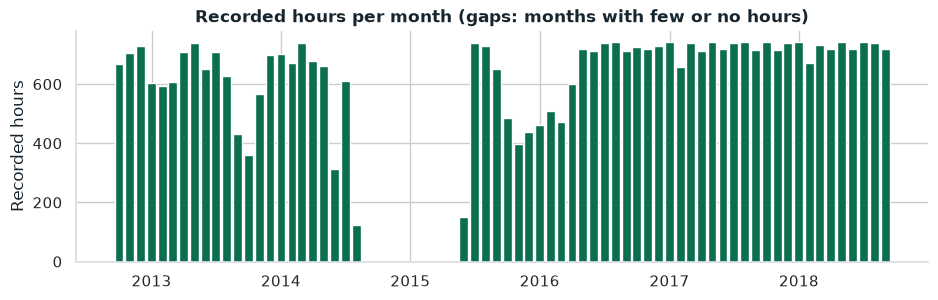

In [19]:
finish_figure(plot_timeline(raw), "eda_timeline", ctx)

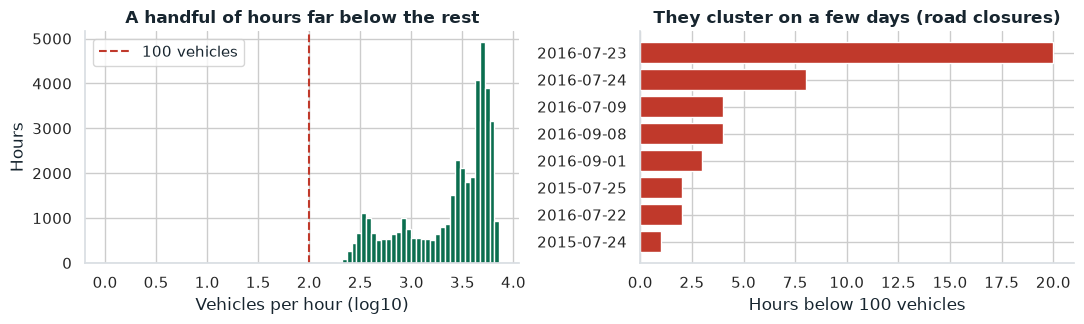

In [20]:
hourly_raw = raw.drop_duplicates("date_time").assign(date_time=lambda d: pd.to_datetime(d["date_time"]))
finish_figure(plot_low_volume(hourly_raw, cfg.target, cfg.cleaning.min_plausible_volume), "eda_low_volume", ctx)

,rain_weather_rows,of_which_rain_1h_recorded,snow_weather_rows,of_which_snow_1h_recorded
year,,,,
2012,253,0,197,0
2013,1236,442,674,0
2014,888,758,79,0
2015,919,448,134,21
2016,1680,487,692,10
2017,2017,0,579,0
2018,1538,524,521,0


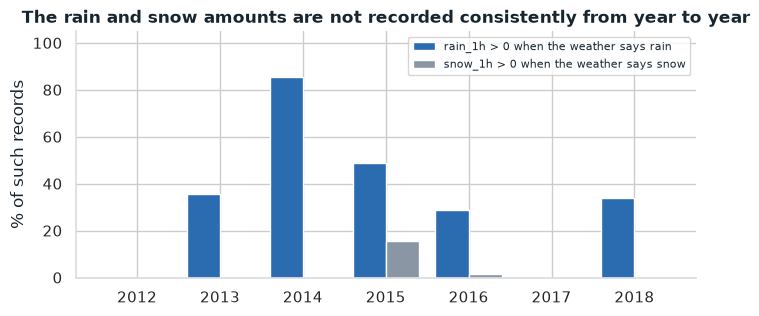

In **2012 and 2017** not a single rainy record carries a rain amount, and the snow amount is recorded in only 2 of 7 years. The columns `rain_1h` and `snow_1h` therefore cannot be trusted as measurements. The weather *label* (`weather_main`) is recorded throughout, so the features in 3.4 take the rain and snow flags from the label as well as from the amount.

In [21]:
amounts = pd.DataFrame(audit["precipitation_amounts_by_year"]).set_index("year")
display(amounts)
finish_figure(plot_precipitation_audit(audit["precipitation_amounts_by_year"]), "eda_precipitation_audit", ctx)
dead_rain = [str(y) for y, r in amounts.iterrows() if r["rain_weather_rows"] and not r["of_which_rain_1h_recorded"]]
say(f"In **{' and '.join(dead_rain)}** not a single rainy record carries a rain amount, and the snow amount is "
    f"recorded in only {int((amounts['of_which_snow_1h_recorded'] > 0).sum())} of {len(amounts)} years. The "
    "columns `rain_1h` and `snow_1h` therefore cannot be trusted as measurements. The weather *label* "
    "(`weather_main`) is recorded throughout, so the features in 3.4 take the rain and snow flags from the "
    "label as well as from the amount.")

### 3.2 Data cleaning

Every rule is fixed in the configuration and none is estimated from the data, so cleaning can safely run
before the data is split. Each rule, the reason for it and the alternative that was rejected:

| Problem | Rule | Why, and the alternative rejected |
|---|---|---|
| **Missing values** (whole hours) | Leave the gaps as gaps | The target must never be invented. Interpolating a ten-month gap would manufacture training data; the models here do not need a continuous series |
| **Duplicates** | Drop exact copies; then keep one row per hour | The count is the same on every row of an hour, so nothing is lost. When the weather rows differ, the most severe condition is kept (a thunderstorm matters more than the clouds around it), with the hour's highest rain, snow and cloud readings and its mean temperature. Keeping all rows would count some hours six times |
| **Impossible sensor values** | Drop rows with 0 K or more than 100 mm of rain in an hour | A handful of rows; imputing the weather would add a guess to hours that are otherwise ordinary |
| **Outliers in the target** | Drop hours with fewer than 100 vehicles | The road was closed or the counter was down. Left in, they teach the model that, say, a July weekend is quiet, because one July weekend the road was shut. None of these hours is in the validation or test year, so the rule does not touch the data the model is judged on. Other unusual hours (storms, incidents, slow days) are real traffic and are kept |
| **Inconsistent holiday marking** | Spread each holiday to all 24 hours of its day, and name the holidays the source failed to mark | The holiday is a property of the day, not of its midnight hour. The names come from the calendar rules for US federal holidays; the same rules reproduce every one of the days the source does mark (checked by a test) |
| **Holidays that are not quiet** | Treat only the six quiet holidays as holidays | See the evidence below |

In [22]:
# Copied from traffic_volume.cleaning
from __future__ import annotations

SOURCE_COLUMNS = ["holiday", "temp", "rain_1h", "snow_1h", "clouds_all", "weather_main", "weather_description",
                  "date_time", "traffic_volume"]


def collapse_hours(df: pd.DataFrame, severity: list[str]) -> pd.DataFrame:
    """One row per hour. Volume is identical across an hour's rows; weather keeps the worst case."""
    rank = {w: i for i, w in enumerate(severity)}
    work = df.assign(_rank=df["weather_main"].map(rank).fillna(len(rank)))
    worst = work.sort_values(["date_time", "_rank"]).groupby("date_time", as_index=False).first()
    agg = df.groupby("date_time").agg(temp=("temp", "mean"), rain_1h=("rain_1h", "max"), snow_1h=("snow_1h", "max"),
                                      clouds_all=("clouds_all", "max"), traffic_volume=("traffic_volume", "first"),
                                      row_id=("row_id", "min"), weather_rows=("row_id", "size"))
    keep = worst[["date_time", "weather_main", "weather_description", "holiday"]].set_index("date_time")
    return agg.join(keep).reset_index()


def calendar_holiday_names(stamps: pd.Series) -> pd.Series:
    """The named day for each timestamp, from the calendar rules (not from the data)."""
    days = stamps.dt.normalize()
    lookup = {d: holiday_name(d.year, d.month, d.day) for d in days.unique()}
    return days.map(lookup)


def clean_traffic(df: pd.DataFrame, cfg: Config) -> tuple[pd.DataFrame, list[dict]]:
    """Apply the cleaning rules in order and return one row per recorded hour, plus a log."""
    c = cfg.cleaning
    out = df.copy()
    log: list[dict] = []

    def record(rule: str, before: int, why: str, changed: int | None = None) -> None:
        log.append({"rule": rule, "rows_before": before, "rows_after": len(out),
                    "rows_removed": before - len(out), "values_changed": changed, "why": why})

    before = len(out)
    out = out[~out.duplicated(subset=SOURCE_COLUMNS)]
    record("drop_exact_duplicate_rows", before, "The same record stored twice.")

    before = len(out)
    out = out[out["temp"] >= c.min_valid_temp_kelvin]
    record("drop_zero_kelvin_temperature", before, "0 K is a sensor error, not weather.")

    before = len(out)
    out = out[out["rain_1h"] <= c.max_valid_rain_mm]
    record("drop_impossible_rainfall", before, f"More than {c.max_valid_rain_mm:.0f} mm in one hour is a sensor error.")

    before = len(out)
    out = out[out["traffic_volume"] >= c.min_plausible_volume]
    record("drop_closure_or_outage_hours", before,
           f"Fewer than {c.min_plausible_volume} vehicles in an hour: the road was closed or the counter was down.")

    stamp = pd.to_datetime(out["date_time"])
    day = stamp.dt.strftime("%Y-%m-%d")
    names = out.loc[out["holiday"] != "None"].assign(day=day).groupby("day")["holiday"].first()
    before_flags = int((out["holiday"] != "None").sum())
    out = out.assign(holiday=day.map(names).fillna("None").to_numpy())
    record("spread_holiday_to_whole_day", len(out),
           "The source marks a holiday only on its midnight row; every hour of that day is a holiday.",
           int((out["holiday"] != "None").sum()) - before_flags)

    by_calendar = calendar_holiday_names(stamp).to_numpy()
    current = out["holiday"].to_numpy()
    missed = (current == "None") & (by_calendar != "None")
    out = out.assign(holiday=[c_name if m else h for h, c_name, m in zip(current, by_calendar, missed)])
    record("name_holidays_with_no_midnight_row", len(out),
           "A holiday whose midnight hour is missing from the data was never marked; the calendar names it.",
           int(missed.sum()))

    before = len(out)
    out = collapse_hours(out, c.weather_severity)
    record("one_row_per_hour", before,
           "Hours with several weather rows repeat the same volume; keep one row, with the most severe weather.")

    out["date_time"] = pd.to_datetime(out["date_time"])
    out["quiet_holiday"] = out["holiday"].isin(c.quiet_holidays)
    named = int((out["holiday"] != "None").sum())
    record("treat_only_quiet_holidays_as_holidays", len(out),
           "Named days on which traffic stays near normal (Columbus Day, Veterans Day and others) are ordinary "
           "days for the model; only the quiet holidays listed in the configuration count.",
           named - int(out["quiet_holiday"].sum()))
    return out.sort_values("date_time").reset_index(drop=True), log


def parse_calendar(clean: pd.DataFrame) -> pd.DataFrame:
    """The raw variables the feature code and the API use: calendar parts plus the weather columns."""
    t = clean["date_time"]
    return pd.DataFrame({
        "hour": t.dt.hour, "weekday": t.dt.weekday, "month": t.dt.month,
        "is_holiday": clean["quiet_holiday"].astype(int),
        "temp": clean["temp"], "rain_1h": clean["rain_1h"], "snow_1h": clean["snow_1h"],
        "clouds_all": clean["clouds_all"], "weather_main": clean["weather_main"],
    }, index=clean.index)


def typical_weather(clean_rows: pd.DataFrame) -> dict:
    """The usual weather of each month in the given rows: median temperature and cloud cover, the most
    common weather label, no rain and no snow. It stands in for the weather when none is known, as when
    planning further ahead than any forecast reaches."""
    out = {}
    for month, part in clean_rows.groupby(clean_rows["date_time"].dt.month):
        out[int(month)] = {"temp": float(part["temp"].median()), "rain_1h": 0.0, "snow_1h": 0.0,
                           "clouds_all": float(part["clouds_all"].median()),
                           "weather_main": str(part["weather_main"].mode().iloc[0])}
    return out


def with_typical_weather(raw_vars: pd.DataFrame, typical: dict) -> pd.DataFrame:
    """The raw variables with every weather column replaced by the month's typical value."""
    out = raw_vars.copy()
    for column in ("temp", "rain_1h", "snow_1h", "clouds_all", "weather_main"):
        out[column] = [typical[int(m)][column] for m in out["month"]]
    return out


def holiday_evidence(clean_train: pd.DataFrame, target: str) -> pd.DataFrame:
    """For each named day: its traffic as a share of an ordinary day of the same weekday.

    Computed on the training years only. This is the evidence behind the fixed list of quiet
    holidays in the configuration; the list is not re-estimated when the pipeline runs.
    """
    t = clean_train.assign(wd=clean_train["date_time"].dt.weekday, h=clean_train["date_time"].dt.hour,
                           day=clean_train["date_time"].dt.normalize())
    normal = t[t["holiday"] == "None"].groupby(["wd", "h"])[target].mean().rename("normal")
    named = t[t["holiday"] != "None"].join(normal, on=["wd", "h"])
    per_day = named.groupby(["holiday", "day"]).agg(actual=(target, "sum"), normal=("normal", "sum"))
    per_day["share"] = per_day["actual"] / per_day["normal"]
    out = per_day.groupby("holiday")["share"].agg(days="size", share_of_normal="mean", lowest="min", highest="max")
    return out.sort_values("share_of_normal").reset_index()

,rule,rows_before,rows_after,rows_removed,values_changed,why
0,drop_exact_duplicate_rows,48204,48187,17,NaN,The same record stored twice.
1,drop_zero_kelvin_temperature,48187,48177,10,NaN,"0 K is a sensor error, not weather."
2,drop_impossible_rainfall,48177,48176,1,NaN,More than 100 mm in one hour is a sensor error.
3,drop_closure_or_outage_hours,48176,48116,60,NaN,Fewer than 100 vehicles in an hour: the road was closed or the counter was down.
4,spread_holiday_to_whole_day,48116,48116,0,1348.0,The source marks a holiday only on its midnight row; every hour of that day is a holiday.
5,name_holidays_with_no_midnight_row,48116,48116,0,55.0,A holiday whose midnight hour is missing from the data was never marked; the calendar ...
6,one_row_per_hour,48116,40518,7598,NaN,"Hours with several weather rows repeat the same volume; keep one row, with the most se..."
7,treat_only_quiet_holidays_as_holidays,40518,40518,0,550.0,"Named days on which traffic stays near normal (Columbus Day, Veterans Day and others) ..."


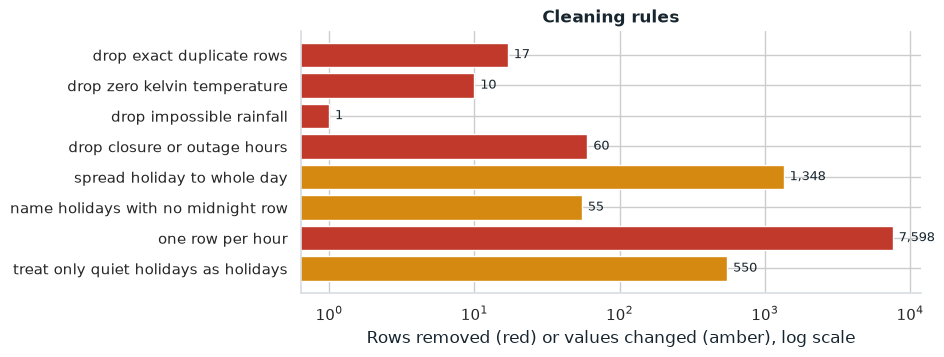

After cleaning: **40,518 hours**, each appearing once, with no missing value in any column (0 missing cells). The lowest count left in the validation year is 186 and in the test year 151: the closure rule removed nothing from either.

In [23]:
clean, cleaning_log = clean_traffic(raw, cfg)
hours_after_cleaning = len(clean)
display(pd.DataFrame(cleaning_log)[["rule", "rows_before", "rows_after", "rows_removed", "values_changed", "why"]])
finish_figure(plot_cleaning_log(cleaning_log), "eda_cleaning_rules", ctx)
low_by_year = clean.groupby(clean["date_time"].dt.year)[cfg.target].min()
say(f"After cleaning: **{hours_after_cleaning:,} hours**, each appearing once, with no missing value in any "
    f"column ({int(clean.isna().sum().sum())} missing cells). The lowest count left in the validation year is "
    f"{low_by_year[cfg.split.validation_year]:,.0f} and in the test year {low_by_year[cfg.split.test_year]:,.0f}: "
    "the closure rule removed nothing from either.")

**Which named days are really holidays for traffic?** The source names eleven days. For each, the table
compares its traffic with an ordinary day of the same weekday, using the **training years only**
(up to 2016), so that this decision borrows nothing from the validation or test year.

,holiday,days,share_of_normal,lowest,highest,treated_as_holiday
0,New Years Day,3,0.473,0.451,0.504,True
1,Christmas Day,4,0.492,0.409,0.631,True
2,Thanksgiving Day,4,0.546,0.532,0.565,True
3,Independence Day,4,0.612,0.568,0.728,True
4,Memorial Day,3,0.614,0.575,0.656,True
5,Labor Day,3,0.677,0.628,0.710,True
6,Martin Luther King Jr Day,3,0.799,0.778,0.815,False
7,Washingtons Birthday,3,0.856,0.722,0.935,False
8,Veterans Day,4,0.914,0.850,0.953,False
9,Columbus Day,4,0.992,0.962,1.037,False


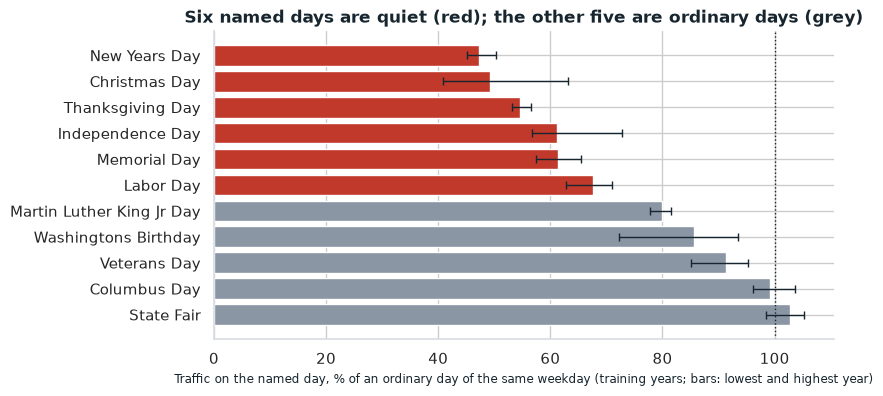

There are two clear groups. On **6 days** traffic falls to 47% to 68% of normal: these are the days most workplaces close. On the other **5** it stays at 80% to 103%: Columbus Day, Veterans Day and the opening day of the State Fair are ordinary commuting days. A single yes/no flag for all eleven tells the model that Veterans Day looks like Christmas, which is wrong in both directions. So only the 6 quiet holidays are treated as holidays; the list is fixed in the configuration.

In [24]:
train_years = clean[clean["date_time"].dt.year <= cfg.split.train_until_year]
evidence = holiday_evidence(train_years, cfg.target)
display(evidence.assign(treated_as_holiday=evidence["holiday"].isin(cfg.cleaning.quiet_holidays)).round(3))
finish_figure(plot_holiday_evidence(evidence, cfg.cleaning.quiet_holidays), "eda_holiday_evidence", ctx)
quiet_part = evidence[evidence["holiday"].isin(cfg.cleaning.quiet_holidays)]["share_of_normal"]
other_part = evidence[~evidence["holiday"].isin(cfg.cleaning.quiet_holidays)]["share_of_normal"]
say(f"There are two clear groups. On **{len(quiet_part)} days** traffic falls to {quiet_part.min():.0%} to "
    f"{quiet_part.max():.0%} of normal: these are the days most workplaces close. On the other "
    f"**{len(other_part)}** it stays at {other_part.min():.0%} to {other_part.max():.0%}: Columbus Day, Veterans "
    "Day and the opening day of the State Fair are ordinary commuting days. A single yes/no flag for all eleven "
    "tells the model that Veterans Day looks like Christmas, which is wrong in both directions. So only the "
    f"{len(quiet_part)} quiet holidays are treated as holidays; the list is fixed in the configuration.")

### 3.3 Exploratory data analysis, part 2: distributions, relationships and trends

From here on the exploration uses the years **before the test year** only. Nothing about 2018 is looked at
until the final evaluation in Section 8, so no modelling decision can be shaped by it.

**Distribution of the target.** Two humps, which turn out to be night and day:

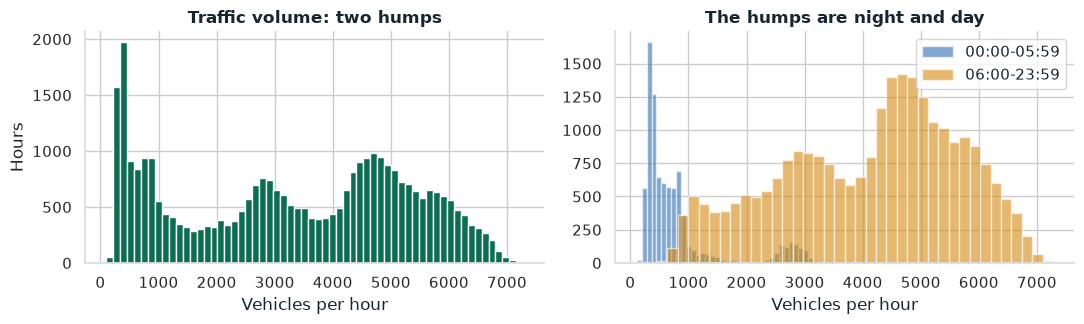

In [25]:
explore = clean[clean["date_time"].dt.year < cfg.split.test_year]
finish_figure(plot_target_distribution(explore[cfg.target], explore["date_time"].dt.hour), "eda_target_distribution", ctx)

**Relationship with the clock and the calendar.** The single most important picture of this dataset:

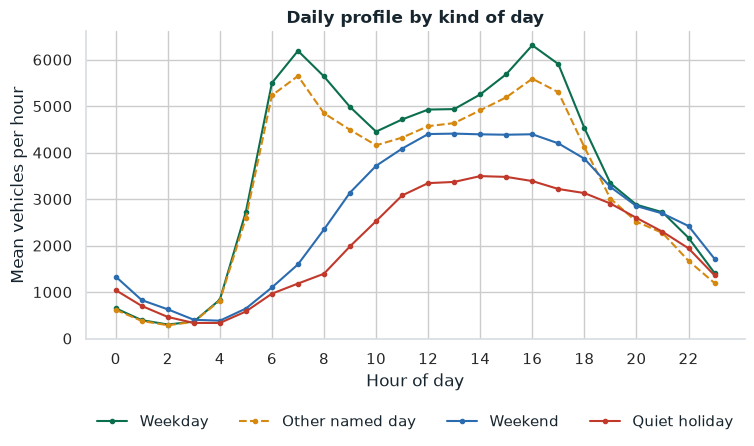

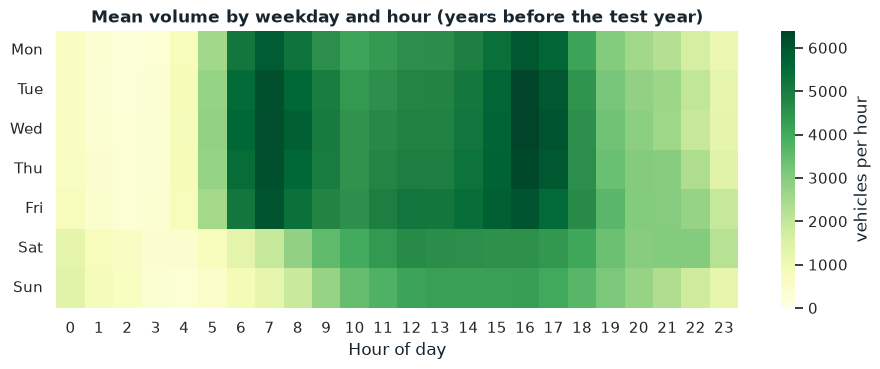

The busiest slot is **Wed at 16:00** with about 6,392 vehicles; the quietest hour is around 03:00 with about 374. Working days have a morning and an afternoon rush hour; weekends and quiet holidays have one broad midday hump. The dashed line (the five named days that are not quiet) follows the working-day shape, not the holiday shape: at 08:00 they carry 4,848 vehicles against 5,639 on a working day and 1,394 on a quiet holiday.

In [26]:
finish_figure(plot_hour_profiles(explore, cfg.target), "eda_hour_profiles", ctx)
heat = hour_weekday_table(explore["date_time"].dt.hour, explore["date_time"].dt.weekday, explore[cfg.target])
finish_figure(plot_heatmap(heat, "Mean volume by weekday and hour (years before the test year)"),
              "eda_hour_weekday_heatmap", ctx)
peak = heat.stack().idxmax()
profiles = hour_profiles(explore, cfg.target)
say(f"The busiest slot is **{WEEKDAYS[int(peak[0])]} at {int(peak[1]):02d}:00** with about "
    f"{heat.stack().max():,.0f} vehicles; the quietest hour is around {int(heat.mean().idxmin()):02d}:00 with about "
    f"{heat.mean().min():,.0f}. Working days have a morning and an afternoon rush hour; weekends and quiet "
    f"holidays have one broad midday hump. The dashed line (the five named days that are not quiet) follows the "
    f"working-day shape, not the holiday shape: at 08:00 they carry {profiles.loc[8, 'Other named day']:,.0f} "
    f"vehicles against {profiles.loc[8, 'Weekday']:,.0f} on a working day and {profiles.loc[8, 'Quiet holiday']:,.0f} "
    "on a quiet holiday.")

**Relationship with the weather.** Compared with the clock, the weather barely moves the volume:

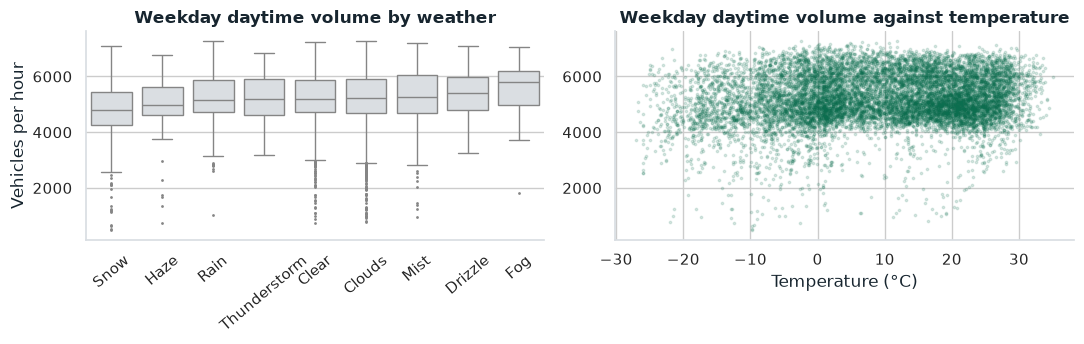

On working days between 07:00 and 18:00 the median volume ranges only from 4,796 (Snow) to 5,820 (Fog) across weather types, a spread of 18%, while the hour of the day moves it by a factor of ten or more. People drive to work whatever the weather.

In [27]:
finish_figure(plot_weather_effects(explore, cfg.target), "eda_weather_effects", ctx)
daytime = explore[explore["date_time"].dt.hour.between(7, 18) & (explore["date_time"].dt.weekday < 5)]
by_weather = daytime.groupby("weather_main")[cfg.target].median()
say(f"On working days between 07:00 and 18:00 the median volume ranges only from {by_weather.min():,.0f} "
    f"({by_weather.idxmin()}) to {by_weather.max():,.0f} ({by_weather.idxmax()}) across weather types, a spread of "
    f"{(by_weather.max() - by_weather.min()) / by_weather.max():.0%}, while the hour of the day moves it by a "
    "factor of ten or more. People drive to work whatever the weather.")

**Trend over time.** No steady growth or decline that a model would have to extrapolate, and visible gaps:

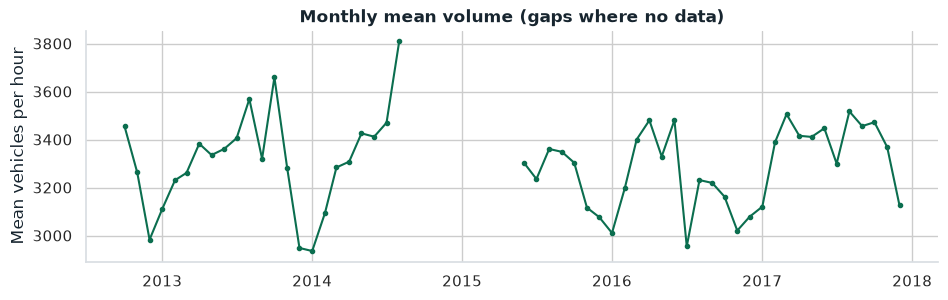

In [28]:
finish_figure(plot_monthly_trend(explore, cfg.target), "eda_monthly_trend", ctx)

### 3.4 Feature engineering

**New features from existing ones.** All per-hour feature logic lives in one small pure-Python module (shown
in Section 2) that the deployed API runs too, so training and serving cannot differ. It also records
**which raw variables each feature uses** (`FEATURE_INPUTS`); Section 6b relies on that to build models from
one, two or all variables without letting other variables leak in.

| Feature | From | Why |
|---|---|---|
| `hour`, `hour_sin`, `hour_cos` | hour | The daily cycle; sine and cosine make 23:00 a neighbour of 00:00 |
| `weekday`, `is_weekend` | weekday | The weekly cycle |
| `rush_hour`, `hour_slot` | hour and weekday | Working-day rush hours; a 48-value profile such as "weekday-08" |
| `month`, `month_sin`, `month_cos` | month | Seasons |
| `is_holiday` | holiday | 1 on the six quiet holidays (3.2) |
| `temp_c` | temperature | Kelvin to Celsius, for readability |
| `rain_1h`, `is_raining`, `snow_1h`, `is_snowing` | rain, snow, weather label | Amounts, and flags that also use the label because the amounts are unreliable (3.1) |
| `clouds_all`, `weather_group` | clouds, weather label | Eleven weather labels grouped into six |

**The year is not a feature.** Tree models cannot extrapolate to a year they have not seen, and 3.3 shows no
trend worth fitting.

In [29]:
# Copied from traffic_volume.features
from __future__ import annotations

def build_feature_frame(raw_vars: pd.DataFrame, sources: list[str]) -> pd.DataFrame:
    """Run ``derive_features`` on every hour; the index is kept so targets stay aligned."""
    rows = [derive_features(r, sources) for r in raw_vars.to_dict("records")]
    return pd.DataFrame(rows, index=raw_vars.index)


def split_feature_types(columns: list[str]) -> tuple[list[str], list[str]]:
    cats = [c for c in columns if c in CATEGORICAL_FEATURES]
    return cats, [c for c in columns if c not in CATEGORICAL_FEATURES]


def to_float32(X) -> np.ndarray:
    """Trees are trained on float32 so the ONNX copy, which runs in float32, matches them."""
    return np.asarray(X, dtype=np.float32)


def make_tree_preprocessor(cats: list[str], nums: list[str], min_frequency: int) -> list:
    columns = ColumnTransformer(
        [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                min_frequency=min_frequency), cats),
         ("num", "passthrough", nums)],
        verbose_feature_names_out=False)
    return [("prep", columns), ("float32", FunctionTransformer(to_float32))]


def make_linear_preprocessor(cats: list[str], nums: list[str], min_frequency: int, degree: int = 1) -> list:
    """One-hot categories and standardised numbers; ``degree=2`` adds squares and pairwise products."""
    num = StandardScaler() if degree == 1 else Pipeline([("scale", StandardScaler()),
                                                         ("poly", PolynomialFeatures(degree, include_bias=False))])
    columns = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                               sparse_output=False), cats),
         ("num", num, nums)],
        verbose_feature_names_out=False)
    return [("prep", columns)]

In [30]:
raw_vars = parse_calendar(clean)
X_all = build_feature_frame(raw_vars, cfg.features.sources)
example = pd.DataFrame({"raw variable": pd.Series(raw_vars.iloc[8].to_dict())}).T
display(example)
display(X_all.iloc[[8]].T.rename(columns=lambda c: "engineered features for the same hour"))
print(f"{X_all.shape[1]} features from {raw_vars.shape[1]} raw variables.")

,hour,weekday,month,is_holiday,temp,rain_1h,snow_1h,clouds_all,weather_main
raw variable,17,1,10,0,294.14,0.0,0.0,20,Clouds


,engineered features for the same hour
hour,17.0
hour_sin,-0.965926
hour_cos,-0.258819
weekday,1.0
is_weekend,0.0
rush_hour,1.0
hour_slot,weekday-17
month,10.0
month_sin,-1.0
month_cos,-0.0


18 features from 9 raw variables.


**Encoding categorical variables and scaling numerical ones.** Both are *learned* from data (which categories
exist, what the mean and spread of each number is), so they are fitted **inside the model pipeline, on the
training rows only**, and refitted inside every cross-validation fold. They are never fitted on the whole
dataset, which would leak the validation and test years into training.

- **Linear models and the neural network** need comparable scales and cannot read text: categories are
  **one-hot encoded** and numbers are **standardised** (mean 0, standard deviation 1).
- **Tree models** split on thresholds, so scaling changes nothing for them: categories become **integer
  codes** and numbers pass through unchanged.

The cell below fits the linear preprocessing on the training years and shows what it learned.

In [31]:
cats_all, nums_all = split_feature_types(list(X_all.columns))
train_mask = (clean["date_time"].dt.year <= cfg.split.train_until_year).to_numpy()
linear_prep = Pipeline(make_linear_preprocessor(cats_all, nums_all, cfg.features.min_category_frequency)).fit(X_all[train_mask])
scaler = linear_prep.named_steps["prep"].named_transformers_["num"]
encoder = linear_prep.named_steps["prep"].named_transformers_["cat"]
scaled = pd.DataFrame(scaler.transform(X_all.loc[train_mask, nums_all]), columns=nums_all)
display(pd.DataFrame({"mean before": scaler.mean_, "std before": scaler.scale_, "mean after": scaled.mean().to_numpy(),
                      "std after": scaled.std(ddof=0).to_numpy()}, index=nums_all).round(3).loc[["hour", "temp_c", "clouds_all", "rain_1h"]])
say(f"Scaling: fitted on the {int(train_mask.sum()):,} training hours; after it every numeric column has mean 0 and "
    f"standard deviation 1 on those hours. Encoding: `hour_slot` has {len(encoder.categories_[0])} categories and "
    f"`weather_group` {len(encoder.categories_[1])}, giving {linear_prep.transform(X_all.iloc[:1]).shape[1]} "
    f"columns for the linear models from the original {X_all.shape[1]}. The tree models receive "
    f"{X_all.shape[1]} columns, with the two categorical ones as integer codes.")

,mean before,std before,mean after,std after
hour,11.517,6.964,0.0,1.0
temp_c,7.770,13.149,0.0,1.0
clouds_all,45.484,38.488,-0.0,1.0
rain_1h,0.104,0.941,-0.0,1.0


Scaling: fitted on the 25,272 training hours; after it every numeric column has mean 0 and standard deviation 1 on those hours. Encoding: `hour_slot` has 48 categories and `weather_group` 6, giving 70 columns for the linear models from the original 18. The tree models receive 18 columns, with the two categorical ones as integer codes.

**Correlations between the features.** The cyclical encodings and their raw versions are related by
construction; Section 6b checks multicollinearity formally with variance inflation factors.

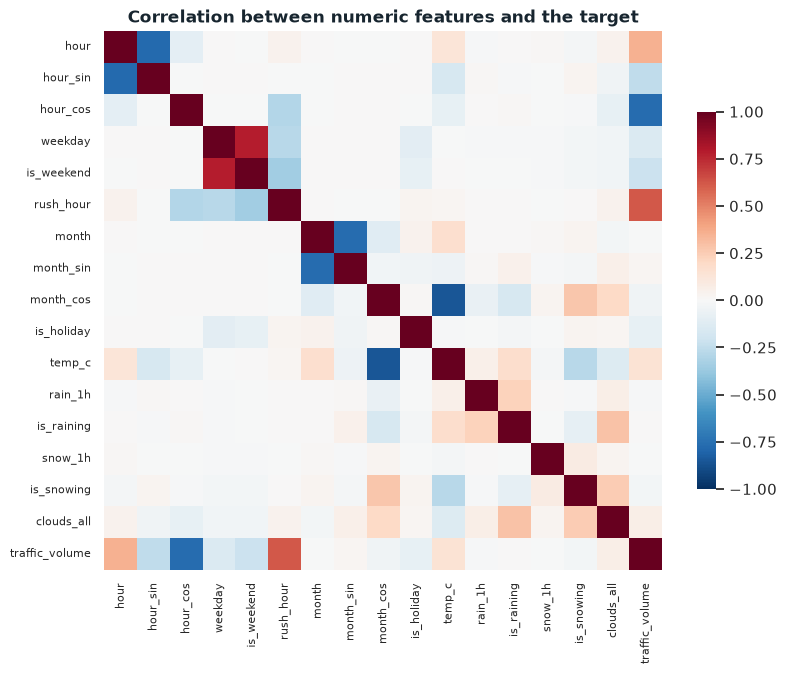

In [32]:
finish_figure(plot_correlation(X_all[(clean["date_time"].dt.year < cfg.split.test_year).to_numpy()], explore[cfg.target]),
              "eda_correlation", ctx)

### 3.5 Data splitting: training, validation and test sets, by time

A planner trains on the past and predicts the future, so the split follows the calendar and is never
shuffled: **training up to 2016, validation 2017, test 2018** (January to September, where the data ends).
A random split was rejected: it would put hours from the same day in training and test, and neighbouring
hours are almost identical, so the score would be flattered by near-copies.

- The **training years** fit the models.
- The **validation year** compares models, chooses settings and feature sets, and is used for every
  diagnostic. Hyperparameter searches use cross-validation *inside* the training years.
- The **test year** is used once more at the very end, for the models declared in advance (Section 8).

In [33]:
# Copied from traffic_volume.split
from __future__ import annotations

def chronological_split(clean: pd.DataFrame, cfg: Config) -> dict[str, np.ndarray]:
    """Positions of each split. No shuffling: the future never trains the past."""
    year = clean["date_time"].dt.year.to_numpy()
    s = cfg.split
    return {"train": np.flatnonzero(year <= s.train_until_year),
            "validation": np.flatnonzero(year == s.validation_year),
            "test": np.flatnonzero(year == s.test_year)}


def rows_hash(values) -> str:
    """Fingerprint of a set of hours, used to prove two runs used the same split."""
    joined = ",".join(sorted(str(v) for v in values))
    return hashlib.sha256(joined.encode()).hexdigest()


def split_summary(clean: pd.DataFrame, splits: dict[str, np.ndarray], target: str) -> dict:
    out = {}
    for name, pos in splits.items():
        part = clean.iloc[pos]
        out[name] = {"rows": len(part), "first_hour": str(part["date_time"].min()),
                     "last_hour": str(part["date_time"].max()), "mean_volume": float(part[target].mean())}
    out["test_rows_sha256"] = rows_hash(clean.iloc[splits["test"]]["date_time"].astype(str))
    return out


def time_series_cv(cfg: Config) -> TimeSeriesSplit:
    """Expanding-window cross-validation on the (time-ordered) training rows."""
    return TimeSeriesSplit(n_splits=cfg.tuning.cv_folds)


def fast_sample(clean: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    """In fast mode only: every fourth hour, keeping the time order (for smoke runs)."""
    return clean.iloc[::4].reset_index(drop=True) if cfg.is_fast else clean

In [34]:
clean = fast_sample(clean, cfg)  # does nothing unless ML_FAST=1
splits = chronological_split(clean, cfg)
split_info = split_summary(clean, splits, cfg.target)
table = pd.DataFrame({k: v for k, v in split_info.items() if k != "test_rows_sha256"}).T
table["share of hours"] = (table["rows"] / table["rows"].sum()).map("{:.0%}".format)
display(table)
print("Fingerprint of the test hours (the pipeline must produce the same one):", split_info["test_rows_sha256"][:16], "...")
coverage = clean.groupby(clean["date_time"].dt.year).size()
say(f"The validation year is almost complete ({coverage[cfg.split.validation_year]:,} of 8,760 hours) and the test "
    f"year has {coverage[cfg.split.test_year]:,} of the 6,552 hours from January to September. The training years are "
    f"thinner: 2014 has {coverage.get(2014, 0):,} hours and 2015 {coverage.get(2015, 0):,}, because of the gaps.")

,rows,first_hour,last_hour,mean_volume,share of hours
train,25272,2012-10-02 09:00:00,2016-12-31 23:00:00,3259.086538,62%
validation,8713,2017-01-01 00:00:00,2017-12-31 23:00:00,3376.58912,22%
test,6533,2018-01-01 00:00:00,2018-09-30 23:00:00,3323.90127,16%


Fingerprint of the test hours (the pipeline must produce the same one): dd03084bd756e206 ...


The validation year is almost complete (8,713 of 8,760 hours) and the test year has 6,533 of the 6,552 hours from January to September. The training years are thinner: 2014 has 4,491 hours and 2015 3,590, because of the gaps.

**Cross-validation that respects time.** Inside the training years the searches use an expanding window:
each fold trains on everything before a date and is scored on the block after it, so the model is never
scored on hours older than its training data.

In [35]:
train_times = clean["date_time"].iloc[splits["train"]].reset_index(drop=True)
folds = [{"fold": i + 1, "trains on": f"{train_times[tr[0]]:%Y-%m-%d} to {train_times[tr[-1]]:%Y-%m-%d}",
          "training hours": len(tr), "scored on": f"{train_times[te[0]]:%Y-%m-%d} to {train_times[te[-1]]:%Y-%m-%d}",
          "scored hours": len(te)} for i, (tr, te) in enumerate(time_series_cv(cfg).split(train_times))]
display(pd.DataFrame(folds))

,fold,trains on,training hours,scored on,scored hours
0,1,2012-10-02 to 2013-07-14,6318,2013-07-14 to 2014-05-23,6318
1,2,2012-10-02 to 2014-05-23,12636,2014-05-23 to 2016-04-03,6318
2,3,2012-10-02 to 2016-04-03,18954,2016-04-03 to 2016-12-31,6318


## 4. Algorithm selection

**Type of model.** Supervised regression: there is a numeric target for every hour. Unsupervised methods
(clustering, PCA) have no target to predict, and reinforcement learning fits sequential decisions with
feedback, not a forecast. The candidates run from the simplest possible to the most flexible, so that every
gain in accuracy can be weighed against what it costs:

| Model | Complexity | Interpretability | Computational cost | Why it is here |
|---|---|---|---|---|
| Hour-of-week average (baseline) | Lookup table, 168 numbers | Total | None | The bar to beat |
| The same table with quiet holidays as an eighth day type | Lookup table, 192 numbers | Total | None | Shows how much of any model's gain is just knowing the holidays |
| Linear, Ridge, Lasso | Low | High: one coefficient per feature | Very low | Honest linear baselines; shrinkage handles correlated features |
| Polynomial Ridge | Medium | Medium | Low | Curved effects and interactions, still linear in its parameters |
| Decision tree | Medium | High if shallow | Low | Readable, but unstable |
| Random forest | High | Medium (importances, SHAP) | Medium to train; large files | Robust non-linear model |
| HistGradientBoosting, LightGBM | High | Medium (SHAP) | Low | Usually the strongest on tabular data, in small files |
| Small neural network | High | Low | Medium | Covers the neural-network family |

**Deployment constraint.** The API runs on a free serverless platform with a size limit and a cold start, so
among models of equal accuracy the smallest and simplest is preferred (the rule is applied in 6.2). The
measured accuracy, training time, prediction time and file size of every candidate follow in Section 5.

In [36]:
# Copied from traffic_volume.models
from __future__ import annotations

class HourOfWeekBaseline(BaseEstimator, RegressorMixin):
    """Predicts the training mean volume for the same hour of the same weekday.

    A strong naive forecast for traffic: it already captures the daily and
    weekly rhythm, so a model must beat it to be worth deploying.
    """

    def fit(self, X: pd.DataFrame, y):
        frame = pd.DataFrame({"weekday": X["weekday"].to_numpy(), "hour": X["hour"].to_numpy(),
                              "y": np.asarray(y, dtype=float)})
        self.table_ = frame.groupby(["weekday", "hour"])["y"].mean().to_dict()
        self.fallback_ = float(frame["y"].mean())
        return self

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        keys = zip(X["weekday"].to_numpy(), X["hour"].to_numpy())
        return np.array([self.table_.get(k, self.fallback_) for k in keys])


class HolidayAwareBaseline(BaseEstimator, RegressorMixin):
    """The same lookup table with one more rule: a quiet holiday is its own, eighth day type.

    Still a table of averages (8 day types x 24 hours). It shows how much of a model's advantage over
    the plain baseline is simply knowing which days are holidays.
    """

    def fit(self, X: pd.DataFrame, y):
        frame = pd.DataFrame({"day": np.where(X["is_holiday"].to_numpy() == 1, 7, X["weekday"].to_numpy()),
                              "weekday": X["weekday"].to_numpy(), "hour": X["hour"].to_numpy(),
                              "y": np.asarray(y, dtype=float)})
        self.table_ = frame.groupby(["day", "hour"])["y"].mean().to_dict()
        self.by_weekday_ = frame.groupby(["weekday", "hour"])["y"].mean().to_dict()
        self.fallback_ = float(frame["y"].mean())
        return self

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        day = np.where(X["is_holiday"].to_numpy() == 1, 7, X["weekday"].to_numpy())
        keys = zip(day, X["weekday"].to_numpy(), X["hour"].to_numpy())
        return np.array([self.table_.get((d, h), self.by_weekday_.get((w, h), self.fallback_)) for d, w, h in keys])


LINEAR_KINDS = {"linear", "ridge", "lasso", "poly_ridge", "mlp"}


MODEL_NOTES = {
    "baseline": "Mean of the same hour and weekday in training. The bar to beat.",
    "baseline_holiday": "The same lookup table with quiet holidays as an eighth day type.",
    "linear": "Ordinary least squares; each coefficient is directly readable.",
    "ridge": "Linear with L2 shrinkage; stable when features are correlated.",
    "lasso": "Linear with L1 shrinkage; drops weak features.",
    "poly_ridge": "Ridge on squares and pairwise products of the numbers: curved effects and interactions.",
    "tree": "One readable regression tree; unstable and prone to overfitting.",
    "rf": "Averages many trees; robust but large and slower to score.",
    "hgb": "Gradient boosting in scikit-learn; strong and fast.",
    "lgbm": "Gradient boosting in LightGBM; usually strongest on tabular data. Explained with SHAP.",
    "mlp": "Small neural network on scaled inputs and a scaled target; hardest to interpret.",
}


def base_regressor(kind: str, cfg: Config, **params):
    seed, jobs = cfg.seed, cfg.models.n_jobs
    if kind == "linear":
        return LinearRegression()
    if kind in ("ridge", "poly_ridge"):
        return Ridge(**{"alpha": 1.0, **params})
    if kind == "lasso":
        return Lasso(**{"alpha": 1.0, "max_iter": 20000, **params})
    if kind == "tree":
        return DecisionTreeRegressor(random_state=seed, **{"min_samples_leaf": 20, **params})
    if kind == "rf":
        return RandomForestRegressor(random_state=seed, n_jobs=jobs,
                                     **{"n_estimators": 200, "min_samples_leaf": 5, "max_features": 0.5, **params})
    if kind == "hgb":
        # No early stopping: it would hold out a random tenth of the training hours, which sit next to
        # hours the model trains on. The number of boosting rounds is tuned by time-ordered CV instead.
        return HistGradientBoostingRegressor(random_state=seed, early_stopping=False, **params)
    if kind == "lgbm":
        return LGBMRegressor(objective="regression", random_state=seed, n_jobs=jobs, deterministic=True,
                             force_row_wise=True, verbose=-1,
                             **{"n_estimators": 500, "learning_rate": 0.05, "num_leaves": 63, **params})
    if kind == "mlp":
        net = MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=300,
                           random_state=seed, **params)
        return TransformedTargetRegressor(regressor=net, transformer=StandardScaler())
    raise ValueError(f"unknown model kind: {kind}")


def make_regressor(kind: str, cats: list[str], nums: list[str], cfg: Config, **params) -> Pipeline:
    """Preprocessing plus estimator. Linear models get one-hot and scaling; trees get integer codes."""
    if kind == "baseline":
        return Pipeline([("model", HourOfWeekBaseline())])
    if kind == "baseline_holiday":
        return Pipeline([("model", HolidayAwareBaseline())])
    minf = cfg.features.min_category_frequency
    if kind in LINEAR_KINDS:
        prep = make_linear_preprocessor(cats, nums, minf, degree=2 if kind == "poly_ridge" else 1)
    else:
        prep = make_tree_preprocessor(cats, nums, minf)
    return Pipeline(prep + [("model", base_regressor(kind, cfg, **params))])


TREE_KINDS = {"lgbm", "rf", "hgb", "tree"}


MODEL_LABELS = {"baseline": "Hour-of-week average", "baseline_holiday": "Hour-of-week average + holidays",
                "linear": "Linear regression", "ridge": "Ridge", "lasso": "Lasso", "poly_ridge": "Polynomial ridge",
                "tree": "Decision tree", "rf": "Random forest", "hgb": "HistGradientBoosting", "lgbm": "LightGBM",
                "mlp": "Neural network"}

## 5. Model development and training

Each candidate is a scikit-learn pipeline: preprocessing (3.4) followed by the estimator, fitted as one
object. Each is scored in two ways: by **time-series cross-validation inside the training years** (mean and
spread over the folds), and by **a fit on all training years scored on the validation year**. The second is
the number used to compare them. All candidates here use sensible default settings; tuning follows in
Section 6.

In [37]:
# Copied from traffic_volume.tuning
from __future__ import annotations

def search_summary(name: str, model: str, rmses: list[float], params: list[dict], seconds: float,
                   folds: int) -> dict:
    best = int(np.argmin(rmses))
    return {"strategy": name, "model": model, "configs_tried": len(rmses), "fits": len(rmses) * folds,
            "seconds": round(seconds, 1), "best_rmse": float(rmses[best]), "best_params": params[best],
            "history": [float(v) for v in rmses], "best_so_far": [float(v) for v in np.minimum.accumulate(rmses)]}


def unprefix(params: dict) -> dict:
    return {k.split("__", 1)[1]: (v.item() if hasattr(v, "item") else v) for k, v in params.items()}


def grid_search_rmse(kind: str, grid: dict, X, y, cats, nums, cfg: Config) -> dict:
    start = time.time()
    search = GridSearchCV(make_regressor(kind, cats, nums, cfg), {f"model__{k}": v for k, v in grid.items()},
                          scoring="neg_root_mean_squared_error", cv=time_series_cv(cfg), n_jobs=1, refit=False)
    search.fit(X, y)
    r = search.cv_results_
    return search_summary("grid", kind, list(-r["mean_test_score"]), [unprefix(p) for p in r["params"]],
                          time.time() - start, cfg.tuning.cv_folds)


def random_search_rmse(kind: str, space: dict, n_iter: int, X, y, cats, nums, cfg: Config) -> dict:
    start = time.time()
    search = RandomizedSearchCV(make_regressor(kind, cats, nums, cfg), {f"model__{k}": v for k, v in space.items()},
                                n_iter=n_iter, scoring="neg_root_mean_squared_error", cv=time_series_cv(cfg),
                                n_jobs=1, refit=False, random_state=cfg.seed)
    search.fit(X, y)
    r = search.cv_results_
    return search_summary("random", kind, list(-r["mean_test_score"]), [unprefix(p) for p in r["params"]],
                          time.time() - start, cfg.tuning.cv_folds)


def lgbm_space() -> dict:
    """Random-search space for LightGBM; the Optuna space covers the same ranges."""
    return {"num_leaves": randint(15, 256), "learning_rate": loguniform(0.01, 0.2), "n_estimators": randint(100, 1200),
            "min_child_samples": randint(5, 100), "subsample": uniform(0.5, 0.5), "subsample_freq": [1],
            "colsample_bytree": uniform(0.5, 0.5), "reg_lambda": loguniform(1e-3, 10.0)}


def lgbm_trial(trial: optuna.Trial) -> dict:
    return {"num_leaves": trial.suggest_int("num_leaves", 15, 255),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            "n_estimators": trial.suggest_int("n_estimators", 100, 1199),
            "min_child_samples": trial.suggest_int("min_child_samples", 5, 99),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0), "subsample_freq": 1,
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True)}


def bayesian_search_rmse(n_trials: int, X, y, cats, nums, cfg: Config) -> dict:
    """Optuna TPE with a seeded sampler and one worker (reproducible)."""
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    start = time.time()
    cv = time_series_cv(cfg)

    def objective(trial: optuna.Trial) -> float:
        model = make_regressor("lgbm", cats, nums, cfg, **lgbm_trial(trial))
        return float(-np.mean(cross_val_score(model, X, y, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1)))

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=cfg.seed))
    study.optimize(objective, n_trials=n_trials, n_jobs=1)
    return search_summary("bayesian", "lgbm", [t.value for t in study.trials],
                          [{**t.params, "subsample_freq": 1} for t in study.trials], time.time() - start,
                          cfg.tuning.cv_folds)


def rf_space() -> dict:
    """Kept moderate (fewer, shallower trees) so the search fits a single-core budget; the forest is a
    comparison here, and deep forests are too large to deploy anyway."""
    return {"n_estimators": randint(100, 201), "max_depth": [12, 16, 20], "min_samples_leaf": randint(3, 11),
            "max_features": [0.3, 0.5]}


def hgb_space() -> dict:
    """Random-search space for HistGradientBoosting (rounds, learning rate, tree size, regularisation)."""
    return {"max_iter": randint(50, 401), "learning_rate": loguniform(0.02, 0.3), "max_leaf_nodes": randint(8, 65),
            "min_samples_leaf": randint(10, 101), "l2_regularization": loguniform(1e-3, 10.0)}


def run_all_searches(X, y, cats, nums, cfg: Config, cache_dir: Path | None = None) -> dict:
    """Grid search on ridge, random search on the random forest and on HistGradientBoosting, and all
    three strategies on LightGBM with the same budget.

    With ``cache_dir``, each finished search is saved immediately and skipped on a re-run, so an
    interrupted tuning stage resumes where it stopped. The file names carry a fingerprint of the
    training data and the search settings, so a result from different data or budgets is never reused.
    """
    t = cfg.tuning
    fingerprint = hashlib.sha256(repr((len(X), round(float(np.sum(y)), 3), list(X.columns), t, cfg.seed,
                                       cfg.features.min_category_frequency)).encode()).hexdigest()[:10]
    jobs = {
        "ridge_grid": lambda: grid_search_rmse("ridge", t.ridge_grid, X, y, cats, nums, cfg),
        "rf_random": lambda: random_search_rmse("rf", rf_space(), t.rf_random_iterations, X, y, cats, nums, cfg),
        "hgb_random": lambda: random_search_rmse("hgb", hgb_space(), t.hgb_random_iterations, X, y, cats, nums, cfg),
        "lgbm_grid": lambda: grid_search_rmse("lgbm", t.lgbm_grid, X, y, cats, nums, cfg),
        "lgbm_random": lambda: random_search_rmse("lgbm", lgbm_space(), t.lgbm_budget, X, y, cats, nums, cfg),
        "lgbm_bayesian": lambda: bayesian_search_rmse(t.lgbm_budget, X, y, cats, nums, cfg),
    }
    results = {}
    for name, run in jobs.items():
        cached = Path(cache_dir) / f"{name}-{fingerprint}.json" if cache_dir else None
        if cached is not None and cached.exists():
            results[name] = json.loads(cached.read_text())
            continue
        results[name] = run()
        if cached is not None:
            cached.parent.mkdir(parents=True, exist_ok=True)
            cached.write_text(json.dumps(results[name], default=float))
    return results


def best_lgbm(tuning: dict) -> dict:
    return min((tuning[k] for k in ("lgbm_grid", "lgbm_random", "lgbm_bayesian")), key=lambda r: r["best_rmse"])

In [38]:
# Copied from traffic_volume.evaluation
from __future__ import annotations

def regression_metrics(y, pred) -> dict:
    y, pred = np.asarray(y, float), np.asarray(pred, float)
    mse = mean_squared_error(y, pred)
    return {"mse": float(mse), "rmse": float(np.sqrt(mse)), "mae": float(mean_absolute_error(y, pred)),
            "r2": float(r2_score(y, pred))}


def rmse_of(y, pred) -> float:
    return float(np.sqrt(np.mean((np.asarray(y, float) - np.asarray(pred, float)) ** 2)))


def day_blocks(days) -> tuple[np.ndarray, dict]:
    days = np.asarray(days)
    unique = np.unique(days)
    return unique, {d: np.flatnonzero(days == d) for d in unique}


def block_bootstrap_ci(y, pred, days, n_samples: int, seed: int) -> dict:
    """95% intervals from resampling whole days with replacement.

    Neighbouring hours are strongly correlated, so resampling single hours would
    pretend there is more independent evidence than there is and give intervals
    that are too narrow.
    """
    y, pred = np.asarray(y, float), np.asarray(pred, float)
    unique, index = day_blocks(days)
    rng = np.random.default_rng(seed)
    draws: dict[str, list[float]] = {}
    for _ in range(n_samples):
        pick = np.concatenate([index[d] for d in rng.choice(unique, size=len(unique), replace=True)])
        for k, v in regression_metrics(y[pick], pred[pick]).items():
            draws.setdefault(k, []).append(v)
    return {k: {"low": float(np.percentile(v, 2.5)), "high": float(np.percentile(v, 97.5))} for k, v in draws.items()}


def paired_block_bootstrap(y, pred, reference, days, n_samples: int, seed: int) -> dict:
    """95% interval for how much lower the model's RMSE is than a reference model's.

    Both models are scored on the same resampled days, so the interval describes the difference
    itself. Comparing one model's interval with the other's point estimate would not.
    """
    y, pred, reference = np.asarray(y, float), np.asarray(pred, float), np.asarray(reference, float)
    unique, index = day_blocks(days)
    rng = np.random.default_rng(seed)
    cuts, gaps = [], []
    for _ in range(n_samples):
        pick = np.concatenate([index[d] for d in rng.choice(unique, size=len(unique), replace=True)])
        model, ref = rmse_of(y[pick], pred[pick]), rmse_of(y[pick], reference[pick])
        cuts.append(1 - model / ref)
        gaps.append(ref - model)
    point_model, point_ref = rmse_of(y, pred), rmse_of(y, reference)
    return {"rmse_reduction": {"point": 1 - point_model / point_ref, "low": float(np.percentile(cuts, 2.5)),
                               "high": float(np.percentile(cuts, 97.5))},
            "rmse_difference": {"point": point_ref - point_model, "low": float(np.percentile(gaps, 2.5)),
                                "high": float(np.percentile(gaps, 97.5))},
            "share_of_resamples_model_better": float(np.mean(np.array(gaps) > 0))}


def evaluate_regressors(X_train, y_train, X_val, y_val, cats, nums, cfg: Config) -> pd.DataFrame:
    """Time-series CV on the training years, then a full-train fit scored on the validation year."""
    rows = []
    for kind in MODEL_NOTES:
        model = make_regressor(kind, cats, nums, cfg)
        cv = cross_validate(model, X_train, y_train, cv=time_series_cv(cfg), scoring="neg_root_mean_squared_error")
        start = time.time()
        model.fit(X_train, y_train)
        fit_s = time.time() - start
        start = time.time()
        pred = model.predict(X_val)
        per_1k_ms = (time.time() - start) / len(X_val) * 1e6
        val = regression_metrics(y_val, pred)
        rows.append({"model": kind, "cv_rmse_mean": float(-np.mean(cv["test_score"])),
                     "cv_rmse_std": float(np.std(cv["test_score"])), "val_mse": val["mse"], "val_rmse": val["rmse"],
                     "val_mae": val["mae"], "val_r2": val["r2"], "fit_seconds": round(fit_s, 2),
                     "predict_ms_per_1k_rows": round(per_1k_ms, 2),
                     "size_kb": round(len(pickle.dumps(model)) / 1024, 1), "notes": MODEL_NOTES[kind]})
    return pd.DataFrame(rows).sort_values("val_rmse").reset_index(drop=True)


def history_curve(model, X_train, y_train, X_val, y_val, cfg: Config) -> dict:
    """Learning curve for a time series: how much history does the model need?

    The model is refitted on the most recent n training hours (counting back from the end of the
    training years) and scored on those hours and on the whole validation year. Every point is
    scored on the same validation year, so the points are comparable.
    """
    sizes, train, val = [], [], []
    for share in cfg.diagnostics.learning_curve_sizes:
        n = max(int(round(share * len(X_train))), 200)
        Xs, ys = X_train.iloc[-n:], y_train.iloc[-n:]
        fitted = clone(model).fit(Xs, ys)
        sizes.append(n)
        train.append(rmse_of(ys, fitted.predict(Xs)))
        val.append(rmse_of(y_val, fitted.predict(X_val)))
    return {"train_sizes": sizes, "train_rmse": train, "val_rmse": val}


def complexity_curve(kind: str, params: dict, X_train, y_train, X_val, y_val, cats, nums, cfg: Config) -> dict | None:
    """Training and validation error as the model's capacity grows (everything else fixed)."""
    spec = cfg.diagnostics.complexity_curve.get(kind)
    if spec is None:
        return None
    train, val = [], []
    for value in spec["values"]:
        fitted = make_regressor(kind, cats, nums, cfg, **{**params, spec["param"]: value}).fit(X_train, y_train)
        train.append(rmse_of(y_train, fitted.predict(X_train)))
        val.append(rmse_of(y_val, fitted.predict(X_val)))
    chosen = make_regressor(kind, cats, nums, cfg, **params).named_steps["model"].get_params()[spec["param"]]
    return {"param": spec["param"], "values": list(spec["values"]), "train_rmse": train, "val_rmse": val,
            "chosen": chosen}


def fit_verdict(train_rmse: float, val_rmse: float, curve: dict | None) -> dict:
    """Put the under/overfitting evidence into words, from the numbers (nothing is asserted by hand)."""
    gap = val_rmse / train_rmse - 1
    if gap > 0.25:
        over = (f"Validation error is {gap:.0%} above training error: the model overfits, fitting the training "
                "years noticeably better than it predicts a new year.")
    elif gap > 0.05:
        over = (f"Validation error is {gap:.0%} above training error: mild overfitting, the expected price of a "
                "flexible model.")
    elif gap >= -0.05:
        over = (f"Training and validation error differ by only {abs(gap):.1%}: no sign of overfitting.")
    else:
        over = (f"Validation error is {abs(gap):.0%} below training error: no overfitting. If anything the "
                "training years are the harder ones to fit; the table of training error by year shows which.")
    under, best_value = "", None
    if curve:
        best = int(np.argmin(curve["val_rmse"]))
        best_value = curve["values"][best]
        if val_rmse <= curve["val_rmse"][best] * 1.02:
            under = (f" On the complexity curve the validation error is lowest at {curve['param']} = {best_value} "
                     f"({curve['val_rmse'][best]:.0f}) and the chosen setting ({curve['chosen']}) is within 2% of "
                     "it: more capacity would not help, so the model is not underfitting either.")
        else:
            under = (f" On the complexity curve the validation error is lowest at {curve['param']} = {best_value} "
                     f"({curve['val_rmse'][best]:.0f}), better than the chosen setting ({curve['chosen']}): capacity "
                     "is not at its best value.")
    return {"gap": float(gap), "text": over + under, "best_capacity": best_value}


def day_segments(clean_rows: pd.DataFrame) -> np.ndarray:
    """Each hour's kind of time: quiet holiday, weekend, or one of four parts of a working day."""
    t = clean_rows["date_time"]
    hour, weekend = t.dt.hour, t.dt.weekday >= 5
    return np.select(
        [clean_rows["quiet_holiday"].to_numpy(), weekend.to_numpy(), hour.isin([6, 7, 8, 9, 15, 16, 17, 18]).to_numpy(),
         hour.between(10, 14).to_numpy(), hour.between(19, 22).to_numpy()],
        ["Quiet holiday", "Weekend", "Weekday rush hours", "Weekday midday", "Weekday evening"], "Weekday night")


def weather_kinds(clean_rows: pd.DataFrame) -> np.ndarray:
    w = clean_rows["weather_main"]
    return np.select([w.isin(RAINY).to_numpy(), (w == "Snow").to_numpy(), w.isin(["Fog", "Mist", "Haze", "Smoke"]).to_numpy()],
                     ["Rain or storm", "Snow", "Low visibility"], "Clear or cloudy")


SEGMENT_ORDER = ["Weekday rush hours", "Weekday midday", "Weekday evening", "Weekday night", "Weekend", "Quiet holiday"]


WEATHER_ORDER = ["Clear or cloudy", "Low visibility", "Rain or storm", "Snow"]


def slice_report(clean_rows: pd.DataFrame, y, preds: dict, reference: str = "baseline", model: str = "champion") -> dict:
    """Error of each model in each kind of hour, each month and each kind of weather.

    ``reduction`` is how much lower the model's RMSE is than the reference's in that slice;
    ``share_of_sq_error`` is the slice's share of the model's total squared error.
    """
    frame = pd.DataFrame({k: np.asarray(v, float) for k, v in preds.items()})
    frame["y"] = np.asarray(y, float)
    t = clean_rows["date_time"]
    groups = {"by_segment": (day_segments(clean_rows), SEGMENT_ORDER),
              "by_month": (t.dt.month.to_numpy(), sorted(t.dt.month.unique())),
              "by_weather": (weather_kinds(clean_rows), WEATHER_ORDER),
              "by_period": (np.where(t.dt.month.to_numpy() <= 9, "January to September", "October to December"),
                            ["January to September", "October to December"])}
    total_sq = float(((frame["y"] - frame[model]) ** 2).sum())
    out = {}
    for name, (labels, order) in groups.items():
        rows = []
        for value in order:
            part = frame[labels == value]
            if part.empty:
                continue
            row = {"group": int(value) if name == "by_month" else value, "hours": len(part),
                   "mean_volume": float(part["y"].mean())}
            for k in preds:
                row[f"{k}_rmse"] = rmse_of(part["y"], part[k])
            row["reduction"] = float(1 - row[f"{model}_rmse"] / row[f"{reference}_rmse"])
            row["share_of_hours"] = len(part) / len(frame)
            row["share_of_sq_error"] = float(((part["y"] - part[model]) ** 2).sum() / total_sq)
            rows.append(row)
        out[name] = rows
    return out


def residual_report(clean_rows: pd.DataFrame, y, pred, target: str, top: int = 10) -> dict:
    """Residuals by hour and by day type, by named day, plus the worst-predicted hours (validation data)."""
    frame = pd.DataFrame({"date_time": clean_rows["date_time"].to_numpy(), "holiday": clean_rows["holiday"].to_numpy(),
                          "actual": np.asarray(y, float), "predicted": np.asarray(pred, float)})
    frame["residual"] = frame["actual"] - frame["predicted"]
    frame["hour"] = frame["date_time"].dt.hour
    frame["day_type"] = np.where(clean_rows["quiet_holiday"].to_numpy(), "quiet holiday",
                                 np.where(frame["holiday"] != "None", "other named day",
                                          np.where(frame["date_time"].dt.weekday >= 5, "weekend", "weekday")))
    by_hour = frame.groupby("hour")["residual"].agg(mean="mean", rmse=lambda r: float(np.sqrt(np.mean(r ** 2))))
    by_type = frame.groupby("day_type")["residual"].agg(rows="size", mean="mean",
                                                        rmse=lambda r: float(np.sqrt(np.mean(r ** 2))))
    named = frame[frame["holiday"] != "None"].groupby("holiday")["residual"].agg(
        hours="size", mean="mean", rmse=lambda r: float(np.sqrt(np.mean(r ** 2))))
    worst = frame.reindex(frame["residual"].abs().sort_values(ascending=False).index).head(top)
    worst = worst.assign(date_time=worst["date_time"].astype(str))
    days = frame.assign(day=frame["date_time"].dt.strftime("%Y-%m-%d"), sq=frame["residual"] ** 2)
    worst_days = days.groupby("day").agg(hours=("sq", "size"), rmse=("sq", lambda s: float(np.sqrt(s.mean()))),
                                         mean_residual=("residual", "mean"), holiday=("holiday", "first"))
    worst_days = worst_days.sort_values("rmse", ascending=False).head(top)
    return {"by_hour": by_hour.reset_index().to_dict("records"), "by_day_type": by_type.reset_index().to_dict("records"),
            "by_named_day": named.reset_index().to_dict("records"),
            "worst": worst[["date_time", "holiday", "actual", "predicted", "residual"]].to_dict("records"),
            "worst_days": worst_days.reset_index().to_dict("records"),
            "over_prediction_share_of_large_errors": float((frame.loc[frame["residual"].abs() > 1000, "residual"] < 0).mean())
            if (frame["residual"].abs() > 1000).any() else None,
            "frame": frame}

In [39]:
# Copied from traffic_volume.feature_study
from __future__ import annotations

DISCRETE_VARIABLES = {"hour", "weekday", "month", "is_holiday", "weather_main"}


CALENDAR_VARIABLES = ["hour", "weekday", "month", "is_holiday"]


INPUT_GROUPS = [("Hour and weekday", ["hour", "weekday"]),
                ("+ month", ["hour", "weekday", "month"]),
                ("+ holiday (all calendar inputs)", CALENDAR_VARIABLES),
                ("+ weather (all inputs)", list(RAW_VARIABLES))]


RAW_FEATURE_OF = {"hour": "hour", "weekday": "weekday", "month": "month", "is_holiday": "is_holiday",
                  "temp": "temp_c", "rain_1h": "rain_1h", "snow_1h": "snow_1h", "clouds_all": "clouds_all",
                  "weather_main": "weather_group"}


def correlation_ratio(categories, values) -> float:
    """Eta: the share of the target's spread explained by group means (0 to 1)."""
    frame = pd.DataFrame({"c": np.asarray(categories), "v": np.asarray(values, float)})
    means = frame.groupby("c")["v"].transform("mean")
    total = ((frame["v"] - frame["v"].mean()) ** 2).sum()
    return float(np.sqrt(((means - frame["v"].mean()) ** 2).sum() / total)) if total else 0.0


def association(raw_train: pd.DataFrame, y_train) -> dict[str, float]:
    """Correlation ratio for discrete variables, absolute Pearson correlation for continuous ones."""
    out = {}
    for var in RAW_VARIABLES:
        col = raw_train[var]
        out[var] = (correlation_ratio(col, y_train) if var in DISCRETE_VARIABLES
                    else float(abs(np.corrcoef(col.astype(float), np.asarray(y_train, float))[0, 1])))
    return out


def mutual_information(raw_train: pd.DataFrame, y_train, seed: int) -> dict[str, float]:
    X = raw_train[RAW_VARIABLES].copy()
    X["weather_main"] = X["weather_main"].astype("category").cat.codes
    mi = mutual_info_regression(X.astype(float), np.asarray(y_train, float),
                                discrete_features=[v in DISCRETE_VARIABLES for v in RAW_VARIABLES], random_state=seed)
    return dict(zip(RAW_VARIABLES, map(float, mi)))


def grouped_permutation(model, raw_val: pd.DataFrame, y_val, cfg: Config) -> dict[str, float]:
    """Increase in validation RMSE when one raw variable is shuffled and every feature is recomputed."""
    rng = np.random.default_rng(cfg.seed)
    sources = cfg.features.sources
    base = regression_metrics(y_val, model.predict(build_feature_frame(raw_val, sources)))["rmse"]
    out = {}
    for var in RAW_VARIABLES:
        scores = []
        for _ in range(cfg.explain.permutation_repeats):
            shuffled = raw_val.copy()
            shuffled[var] = rng.permutation(shuffled[var].to_numpy())
            scores.append(regression_metrics(y_val, model.predict(build_feature_frame(shuffled, sources)))["rmse"])
        out[var] = float(np.mean(scores) - base)
    return out


def share_by_variable(per_feature: dict[str, float]) -> dict[str, float]:
    """Split each feature's value equally among the variables it uses."""
    out = dict.fromkeys(RAW_VARIABLES, 0.0)
    for feat, value in per_feature.items():
        inputs = FEATURE_INPUTS[feat]
        for var in inputs:
            out[var] += float(value) / len(inputs)
    return out


def split_gain(est) -> np.ndarray:
    """Total error reduction of the splits on each input column.

    LightGBM reports it directly and scikit-learn's forests and single trees expose the equivalent
    ``feature_importances_``. HistGradientBoosting has no such attribute, so the gains are summed
    from the split nodes of its trees.
    """
    if hasattr(est, "booster_"):
        return est.booster_.feature_importance(importance_type="gain")
    if hasattr(est, "feature_importances_"):
        return est.feature_importances_
    gain = np.zeros(est.n_features_in_)
    for stage in est._predictors:
        for tree in stage:
            nodes = tree.nodes
            split = nodes["is_leaf"] == 0
            np.add.at(gain, nodes["feature_idx"][split], nodes["gain"][split])
    return gain


def tree_gain(model) -> dict[str, float]:
    """The model's own split-gain importance, shared out among the raw variables."""
    names = list(model.named_steps["prep"].get_feature_names_out())
    return share_by_variable(dict(zip(names, split_gain(model.named_steps["model"]))))


def grouped_shap(values) -> dict[str, float]:
    """Mean absolute SHAP per variable; a shared feature's SHAP is split among its variables."""
    out = dict.fromkeys(RAW_VARIABLES, 0.0)
    per_row = {var: np.zeros(values.values.shape[0]) for var in RAW_VARIABLES}
    for j, feat in enumerate(values.feature_names):
        inputs = FEATURE_INPUTS[feat]
        for var in inputs:
            per_row[var] += values.values[:, j] / len(inputs)
    for var in RAW_VARIABLES:
        out[var] = float(np.abs(per_row[var]).mean())
    return out


def rank_variables(raw_train, y_train, raw_val, y_val, model, shap_values, cfg: Config) -> pd.DataFrame:
    """Five rankings (association, mutual information, permutation, tree importance, SHAP) and their mean rank."""
    table = pd.DataFrame({
        "association": association(raw_train, y_train),
        "mutual_information": mutual_information(raw_train, y_train, cfg.seed),
        "permutation_rmse_increase": grouped_permutation(model, raw_val, y_val, cfg),
        "tree_gain": tree_gain(model),
        "shap": grouped_shap(shap_values),
    })
    ranks = table.rank(ascending=False, method="min").add_suffix("_rank")
    out = table.join(ranks)
    out["mean_rank"] = ranks.mean(axis=1)
    return out.sort_values(["mean_rank", "permutation_rmse_increase"], ascending=[True, False]).rename_axis("variable")


def vif_table(X_train: pd.DataFrame) -> pd.DataFrame:
    """Variance inflation factors of the numeric features (multicollinearity)."""
    num = X_train[split_feature_types(list(X_train.columns))[1]].astype(float)
    num = num.loc[:, num.std() > 0]
    arr = np.column_stack([np.ones(len(num)), num.to_numpy()])
    vif = [variance_inflation_factor(arr, i + 1) for i in range(num.shape[1])]
    return pd.DataFrame({"feature": num.columns, "vif": vif}).sort_values("vif", ascending=False).reset_index(drop=True)


def family_model(family: str, variables: list[str], params: dict, cfg: Config, tree_kind: str = "lgbm") -> Pipeline:
    """A model restricted to the features of ``variables``.

    linear_raw: ordinary least squares on the untransformed columns only.
    linear: ordinary least squares on all of the variables' features. spline: periodic
    splines of the hour (one variable, several columns) plus the other features
    linearly. tree: the champion's tree model (``tree_kind``) with its settings.
    """
    feats = model_features(family, variables)
    cats, nums = split_feature_types(feats)
    if family == "linear_raw":
        return make_regressor("linear", cats, nums, cfg)
    if family == "tree":
        return make_regressor(tree_kind, cats, nums, cfg, **params)
    if family == "linear":
        return make_regressor("linear", cats, nums, cfg)
    if family == "spline":
        # Periodic splines for the hour (it wraps around midnight), ordinary splines for other
        # continuous inputs, flags and one-hot categories unchanged: one variable can span many columns.
        binary = {"is_weekend", "rush_hour", "is_holiday", "is_raining", "is_snowing"}
        parts = []
        if "hour" in nums:
            parts.append(("hour", SplineTransformer(n_knots=13, degree=3, extrapolation="periodic"), ["hour"]))
        smooth = [n for n in nums if n not in binary and n not in ("hour", "hour_sin", "hour_cos")]
        if smooth:
            parts.append(("smooth", SplineTransformer(n_knots=8, degree=3), smooth))
        flags = [n for n in nums if n in binary]
        if flags:
            parts.append(("flags", "passthrough", flags))
        if cats:
            parts.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats))
        return Pipeline([("prep", ColumnTransformer(parts)), ("model", Ridge(alpha=1e-3))])
    raise ValueError(family)


def model_features(family: str, variables: list[str]) -> list[str]:
    """``linear_raw`` sees only each variable's untransformed column; other families see all its features."""
    return [RAW_FEATURE_OF[v] for v in variables] if family == "linear_raw" else features_using_only(variables)


def variable_models(X: pd.DataFrame, y: pd.Series, splits: dict, ranking: pd.DataFrame, params: dict,
                    cfg: Config, tree_kind: str = "lgbm") -> dict:
    """Univariate, bivariate and multivariate models, fitted on training years and scored on validation."""
    order = list(ranking.index)
    top1, top2 = order[:1], order[:2]
    tr, va = splits["train"], splits["validation"]
    rows, curves = [], {}
    sets = [("univariate", top1), ("bivariate", top2), ("multivariate", list(RAW_VARIABLES)),
            ("univariate (raw weather)", [cfg.feature_study.contrast_variable])]
    for label, variables in sets:
        families = ["linear_raw", "linear", "spline", "tree"] if label.startswith("univariate") else ["linear", "tree"]
        for family in families:
            model = family_model(family, variables, params, cfg, tree_kind)
            Xs = X[model_features(family, variables)]
            model.fit(Xs.iloc[tr], y.iloc[tr])
            pred = model.predict(Xs.iloc[va])
            rows.append({"model": label, "variables": ", ".join(variables), "family": family,
                         "features_used": len(Xs.columns), **regression_metrics(y.iloc[va], pred)})
            if label.startswith("univariate"):
                curves[f"{label}|{family}"] = {"variable": variables[0], "model": model, "columns": list(Xs.columns)}
    incremental = []
    for k in range(1, len(order) + 1):
        variables = order[:k]
        model = family_model("tree", variables, params, cfg, tree_kind)
        Xs = X[model_features("tree", variables)]
        model.fit(Xs.iloc[tr], y.iloc[tr])
        incremental.append({"variables": k, "added": order[k - 1],
                            **regression_metrics(y.iloc[va], model.predict(Xs.iloc[va]))})
    return {"top1": top1, "top2": top2, "table": pd.DataFrame(rows), "incremental": pd.DataFrame(incremental),
            "curves": curves}


def univariate_curves(curves: dict, X_val: pd.DataFrame, y_val: pd.Series, variable: str) -> dict:
    """What each univariate family predicts for every hour of the day, next to the validation year's
    mean and its 10th and 90th percentiles (the data behind the univariate figure)."""
    if variable != "hour":
        return {}
    h = np.arange(24)
    grid = pd.DataFrame({"hour": h.astype(float), "hour_sin": np.sin(2 * np.pi * h / 24),
                         "hour_cos": np.cos(2 * np.pi * h / 24)})
    by_hour = y_val.groupby(X_val["hour"].astype(int).to_numpy())
    out = {"hour": h.tolist(), "actual_mean": by_hour.mean().reindex(h).tolist(),
           "actual_p10": by_hour.quantile(0.1).reindex(h).tolist(), "actual_p90": by_hour.quantile(0.9).reindex(h).tolist()}
    for key, c in curves.items():
        label, family = key.split("|")
        if label == "univariate":
            out[family] = [float(v) for v in c["model"].predict(grid[c["columns"]])]
    return out


def group_ablation(X: pd.DataFrame, y: pd.Series, splits: dict, clean: pd.DataFrame, params: dict, cfg: Config,
                   tree_kind: str) -> pd.DataFrame:
    """Does each group of inputs earn its place? The champion's family and settings on growing sets of
    variables, scored on the validation year: overall, and on the hours with rain, storm or snow, where
    weather inputs ought to matter most."""
    tr, va = splits["train"], splits["validation"]
    kinds = weather_kinds(clean.iloc[va])
    wet = np.isin(kinds, ["Rain or storm", "Snow"])
    rows = []
    for label, variables in INPUT_GROUPS:
        cols = model_features("tree", variables)
        model = family_model("tree", variables, params, cfg, tree_kind).fit(X.iloc[tr][cols], y.iloc[tr])
        pred = model.predict(X.iloc[va][cols])
        actual = y.iloc[va].to_numpy()
        rows.append({"inputs": label, "variables": len(variables), "features_used": len(cols),
                     **regression_metrics(actual, pred), "rmse_rain_storm_snow": rmse_of(actual[wet], pred[wet]),
                     "rmse_dry": rmse_of(actual[~wet], pred[~wet])})
    out = pd.DataFrame(rows)
    out.attrs["wet_hours"] = int(wet.sum())
    return out


def bivariate_surface(X: pd.DataFrame, y: pd.Series, splits: dict, top2: list[str], params: dict,
                      cfg: Config, tree_kind: str = "lgbm") -> tuple[pd.DataFrame, pd.DataFrame]:
    """Mean actual and predicted volume by weekday and hour on the validation year (bivariate tree)."""
    cols = model_features("tree", top2)
    model = family_model("tree", top2, params, cfg, tree_kind).fit(X.iloc[splits["train"]][cols], y.iloc[splits["train"]])
    Xv = X.iloc[splits["validation"]]
    frame = pd.DataFrame({"weekday": Xv["weekday"].to_numpy(), "hour": Xv["hour"].to_numpy(),
                          "actual": y.iloc[splits["validation"]].to_numpy(), "predicted": model.predict(Xv[cols])})
    table = frame.groupby(["weekday", "hour"])[["actual", "predicted"]].mean()
    return table["actual"].unstack("hour"), table["predicted"].unstack("hour")

In [40]:
# Copied from traffic_volume.workflow
from __future__ import annotations

INPUT_SETS = {"all": ("all inputs", list(RAW_VARIABLES)), "calendar": ("calendar only", CALENDAR_VARIABLES)}


def build_frames(clean: pd.DataFrame, splits: dict, cfg: Config) -> dict:
    """Raw variables, features and targets for every split, plus the cleaned rows."""
    raw = parse_calendar(clean)
    X = build_feature_frame(raw, cfg.features.sources)
    y = clean[cfg.target].astype(float)
    cats, nums = split_feature_types(list(X.columns))
    out = {"sources": cfg.features.sources, "cats": cats, "nums": nums, "X": X, "y": y, "raw": raw, "splits": splits}
    for name, pos in splits.items():
        out[f"X_{name}"], out[f"y_{name}"] = X.iloc[pos], y.iloc[pos]
        out[f"raw_{name}"], out[f"clean_{name}"] = raw.iloc[pos], clean.iloc[pos]
    trval = np.concatenate([splits["train"], splits["validation"]])
    out["X_trval"], out["y_trval"], out["clean_trval"] = X.iloc[trval], y.iloc[trval], clean.iloc[trval]
    return out


def finalist_label(kind: str, tuned: bool, inputs: str) -> str:
    return f"{kind}, {'tuned' if tuned else 'default settings'}, {INPUT_SETS[inputs][0]}"


def finalists(tuning: dict) -> list[dict]:
    """The models that compete on the validation year.

    Each tree family appears four times: with the settings its search chose and with its default
    settings, and each of those on all inputs and on the calendar inputs alone (no weather).
    Cross-validation nominates settings; the validation year decides.
    """
    searches = {"rf": tuning["rf_random"], "hgb": tuning["hgb_random"], "lgbm": best_lgbm(tuning)}
    out = [{"label": "ridge, tuned, all inputs", "kind": "ridge", "search": tuning["ridge_grid"], "inputs": "all",
            "tuned": True}]
    for inputs in INPUT_SETS:
        for kind, search in searches.items():
            for tuned in (True, False):
                out.append({"label": finalist_label(kind, tuned, inputs), "kind": kind,
                            "search": search if tuned else None, "inputs": inputs, "tuned": tuned})
    return out


def input_columns(inputs: str, f: dict) -> tuple[list[str], list[str]]:
    """The categorical and numeric feature columns of an input set. A pipeline built on them ignores
    every other column of the feature frame."""
    allowed = set(features_using_only(INPUT_SETS[inputs][1]))
    return [c for c in f["cats"] if c in allowed], [c for c in f["nums"] if c in allowed]


def fit_tuned(tuning: dict, f: dict, cfg: Config) -> dict:
    """Fit every finalist on the training years and score it on the validation year."""
    out = {}
    for item in finalists(tuning):
        search = item["search"]
        params = search["best_params"] if search else {}
        cats, nums = input_columns(item["inputs"], f)
        model = make_regressor(item["kind"], cats, nums, cfg, **params).fit(f["X_train"], f["y_train"])
        out[item["label"]] = {
            "model": model, "kind": item["kind"], "tuned": item["tuned"], "inputs": item["inputs"],
            "variables": len(INPUT_SETS[item["inputs"]][1]), "params": params,
            "strategy": f"{search['strategy']} search" if search else "default settings",
            "cv_rmse": search["best_rmse"] if search else None,
            **{f"val_{k}": v for k, v in regression_metrics(f["y_validation"], model.predict(f["X_validation"])).items()},
            "size_kb": round(len(pickle.dumps(model)) / 1024, 1)}
    return out


def choose_champion(fitted: dict, cfg: Config) -> dict:
    """Lowest validation RMSE among the tree models (the ones the service can serve). Models within the
    tie tolerance count as equal, and the simplest of them wins: fewest input variables, then smallest file."""
    trees = {k: v for k, v in fitted.items() if v["kind"] in TREE_KINDS}
    best = min(v["val_rmse"] for v in trees.values())
    tied = {k: v for k, v in trees.items() if v["val_rmse"] - best <= cfg.selection.tie_tolerance_rmse}
    label = min(tied, key=lambda k: (tied[k]["variables"], tied[k]["size_kb"]))
    win = fitted[label]
    other = "calendar" if win["inputs"] == "all" else "all"
    return {"name": win["kind"], "label": label, "params": win["params"], "strategy": win["strategy"],
            "inputs": win["inputs"], "variables": INPUT_SETS[win["inputs"]][1],
            "counterpart_label": finalist_label(win["kind"], win["tuned"], other), "counterpart_inputs": other,
            "all_inputs_label": finalist_label(win["kind"], win["tuned"], "all"),
            "val_mse": win["val_mse"], "val_rmse": win["val_rmse"], "val_mae": win["val_mae"], "val_r2": win["val_r2"],
            "size_kb": win["size_kb"], "best_val_rmse": best, "best_label": min(trees, key=lambda k: trees[k]["val_rmse"]),
            "tied_models": sorted(tied),
            "rule": f"lowest validation RMSE; models within {cfg.selection.tie_tolerance_rmse} vehicles/hour count as "
                    "equal and the simplest of them wins (fewest input variables, then smallest file)",
            "comparison": [{"model": k, **{kk: vv for kk, vv in v.items() if kk != "model"}}
                           for k, v in fitted.items()]}


def score_without_weather(model, fitted_on: pd.DataFrame, raw_vars: pd.DataFrame, y, cfg: Config) -> dict:
    """The model's error when the weather is not known and each month's typical weather is assumed in its
    place. The typical values come from the rows the model was fitted on."""
    typical = typical_weather(fitted_on)
    X = build_feature_frame(with_typical_weather(raw_vars, typical), cfg.features.sources)
    return regression_metrics(y, model.predict(X))


def diagnose(model, champion: dict, f: dict, cfg: Config) -> dict:
    """Under/overfitting evidence and error analysis for the champion, all on training and validation data."""
    pred = model.predict(f["X_validation"])
    train = regression_metrics(f["y_train"], model.predict(f["X_train"]))
    validation = regression_metrics(f["y_validation"], pred)
    cats, nums = input_columns(champion["inputs"], f)
    curve = complexity_curve(champion["name"], champion["params"], f["X_train"], f["y_train"], f["X_validation"],
                             f["y_validation"], cats, nums, cfg)
    references = {kind: make_regressor(kind, f["cats"], f["nums"], cfg).fit(f["X_train"], f["y_train"])
                  .predict(f["X_validation"]) for kind in ("baseline", "baseline_holiday")}
    years = f["clean_train"]["date_time"].dt.year.to_numpy()
    fitted_values = model.predict(f["X_train"])
    by_year = [{"year": int(y), "hours": int((years == y).sum()),
                **regression_metrics(f["y_train"].to_numpy()[years == y], fitted_values[years == y])}
               for y in sorted(set(years))]
    return {"train": train, "validation": validation, "val_pred": pred, "train_by_year": by_year,
            "validation_typical_weather": score_without_weather(model, f["clean_train"], f["raw_validation"],
                                                                f["y_validation"], cfg),
            "verdict": fit_verdict(train["rmse"], validation["rmse"], curve),
            "learning_curve": history_curve(model, f["X_train"], f["y_train"], f["X_validation"], f["y_validation"], cfg),
            "complexity_curve": curve,
            "residuals": residual_report(f["clean_validation"], f["y_validation"], pred, cfg.target),
            "slices": slice_report(f["clean_validation"], f["y_validation"], {**references, "champion": pred})}


def test_pass_models(champion: dict, tuning: dict, study: dict, f: dict, cfg: Config) -> dict:
    """The pre-declared test models as unfitted pipelines with the columns each one uses."""
    params, kind = champion["params"], champion["name"]
    every = list(f["X"].columns)
    specs = {
        "baseline": (make_regressor("baseline", f["cats"], f["nums"], cfg), every),
        "baseline_holiday": (make_regressor("baseline_holiday", f["cats"], f["nums"], cfg), every),
        "ridge": (make_regressor("ridge", f["cats"], f["nums"], cfg, **tuning["ridge_grid"]["best_params"]), every),
        "univariate": (family_model("tree", study["top1"], params, cfg, kind), model_features("tree", study["top1"])),
        "bivariate": (family_model("tree", study["top2"], params, cfg, kind), model_features("tree", study["top2"])),
        # the champion's family and settings on the other input set (with weather if the champion has none)
        "alternative_inputs": (make_regressor(kind, *input_columns(champion["counterpart_inputs"], f), cfg, **params), every),
        "champion": (make_regressor(kind, *input_columns(champion["inputs"], f), cfg, **params), every),
    }
    if list(specs) != list(cfg.test_pass_models):
        raise ValueError(f"test pass must score exactly {cfg.test_pass_models}")
    return specs


def columns_used(model, fallback: int) -> int:
    """How many feature columns a fitted pipeline actually reads (its column selector may take a subset)."""
    prep = model.named_steps.get("prep")
    if prep is not None:
        return sum(len(cols) for _, _, cols in prep.transformers)
    return {"HourOfWeekBaseline": 2, "HolidayAwareBaseline": 3}.get(type(model.named_steps["model"]).__name__, fallback)


def final_test(specs: dict, f: dict, cfg: Config) -> dict:
    """The only function that reads the test year. Each pre-declared model is refitted on the
    training and validation years (the most recent data matters for a time series) and scored once."""
    results, fitted = {}, {}
    for name, (pipe, cols) in specs.items():
        model = clone(pipe).fit(f["X_trval"][cols], f["y_trval"])
        pred = model.predict(f["X_test"][cols])
        results[name] = {"metrics": regression_metrics(f["y_test"], pred), "pred": pred,
                         "features": columns_used(model, len(cols))}
        fitted[name] = model
    days = f["clean_test"]["date_time"].dt.date.astype(str).to_numpy()
    champ, base, table = results["champion"], results["baseline"], results["baseline_holiday"]
    results["alternative_inputs"]["label"] = "all inputs (with weather)" if "weather_group" not in \
        fitted["champion"].named_steps["prep"].get_feature_names_out() else "calendar only (no weather)"
    n, seed = cfg.evaluation.bootstrap_samples, cfg.seed
    champ["ci"] = block_bootstrap_ci(f["y_test"], champ["pred"], days, n, seed)
    champ["typical_weather_metrics"] = score_without_weather(fitted["champion"], f["clean_trval"], f["raw_test"],
                                                             f["y_test"], cfg)
    base["ci"] = block_bootstrap_ci(f["y_test"], base["pred"], days, n, seed)
    paired = {ref: paired_block_bootstrap(f["y_test"], champ["pred"], results[ref]["pred"], days, n, seed)
              for ref in ("baseline", "baseline_holiday", "alternative_inputs")}
    preds = {k: results[k]["pred"] for k in ("baseline", "baseline_holiday", "alternative_inputs", "champion")}
    frame = pd.DataFrame({"date_time": f["clean_test"]["date_time"].to_numpy(), "actual": f["y_test"].to_numpy(), **preds})
    b, c = base["metrics"], champ["metrics"]
    months = sorted(f["clean_test"]["date_time"].dt.month.unique().tolist())
    return {"models": results, "fitted": fitted, "frame": frame, "paired": paired,
            "slices": slice_report(f["clean_test"], f["y_test"], preds),
            "test_months": months,
            "success": {
                "criterion": f"test R2 >= {cfg.success.r2} and RMSE below the hour-of-week baseline",
                "r2_target_met": bool(c["r2"] >= cfg.success.r2),
                "baseline_r2": b["r2"], "baseline_also_meets_r2_target": bool(b["r2"] >= cfg.success.r2),
                "beats_baseline": bool(c["rmse"] < b["rmse"]),
                "rmse_reduction_vs_baseline": float(1 - c["rmse"] / b["rmse"]),
                "mse_reduction_vs_baseline": float(1 - c["mse"] / b["mse"]),
                "rmse_reduction_vs_holiday_table": float(1 - c["rmse"] / table["metrics"]["rmse"]),
                "reduction_ci_excludes_zero": bool(paired["baseline"]["rmse_reduction"]["low"] > 0)}}


def drop_unserialisable(obj):
    """Drop fitted models, prediction arrays and residual frames before writing JSON."""
    skip = {"pred", "val_pred", "frame", "fitted", "curves"}
    if isinstance(obj, dict):
        return {k: drop_unserialisable(v) for k, v in obj.items() if k not in skip and not hasattr(v, "fit")}
    if isinstance(obj, pd.DataFrame):
        return obj.reset_index().to_dict("records") if obj.index.name else obj.to_dict("records")
    if isinstance(obj, list):
        return [drop_unserialisable(v) for v in obj]
    return obj


def results_report(parts: dict, cfg: Config) -> dict:
    """The single results file. Docs and slides read their numbers from here."""
    return drop_unserialisable({
        "project": cfg.project, "fast_mode": cfg.is_fast, "seed": cfg.seed,
        "data": {"audit": parts["audit"], "cleaning": parts["cleaning_log"], "hours_after_cleaning": parts["hours"],
                 "split": parts["split_summary"], "holiday_evidence": parts["holiday_evidence"]},
        "features": {"sources": cfg.features.sources, "categorical": parts["cats"], "numeric": parts["nums"]},
        "candidates": parts["candidates"], "lag_experiment": parts["lags"],
        "tuning": {k: {kk: vv for kk, vv in v.items() if kk != "history"} for k, v in parts["tuning"].items()},
        "champion": parts["champion"], "diagnostics": parts["diagnostics"],
        "explain": {"permutation_top10": parts["permutation"].head(10), "shap_top10": parts["shap"].head(10)},
        "feature_study": parts["study"], "test": parts["test"], "first_evaluation": cfg.first_evaluation,
        "deployment": parts.get("deployment"),
    })

,model,cv_rmse_mean,cv_rmse_std,validation MSE,validation RMSE,validation MAE,validation R²,fit_seconds,predict_ms_per_1k_rows,size_kb
0,hgb,438.7,34.9,119920.0,346.3,224.1,0.9695,2.09,4.68,357.0
1,rf,426.8,30.9,121488.0,348.6,225.9,0.9691,4.16,24.97,68609.0
2,lgbm,455.4,35.4,127907.0,357.6,230.2,0.9675,2.00,29.24,2623.8
3,mlp,462.0,31.6,137487.0,370.8,247.2,0.9650,14.89,4.51,167.7
4,tree,447.8,31.6,140859.0,375.3,245.0,0.9642,0.20,0.23,139.5
5,baseline_holiday,432.6,30.0,141367.0,376.0,243.9,0.9640,0.01,0.35,10.4
6,poly_ridge,462.5,18.7,149993.0,387.3,266.8,0.9618,0.46,3.61,5.2
7,linear,503.4,14.9,209698.0,457.9,307.7,0.9466,0.22,2.66,4.4
8,ridge,503.3,14.8,209740.0,458.0,307.8,0.9466,0.16,2.72,3.8
9,baseline,514.3,20.4,210685.0,459.0,276.9,0.9464,0.01,1.06,5.0


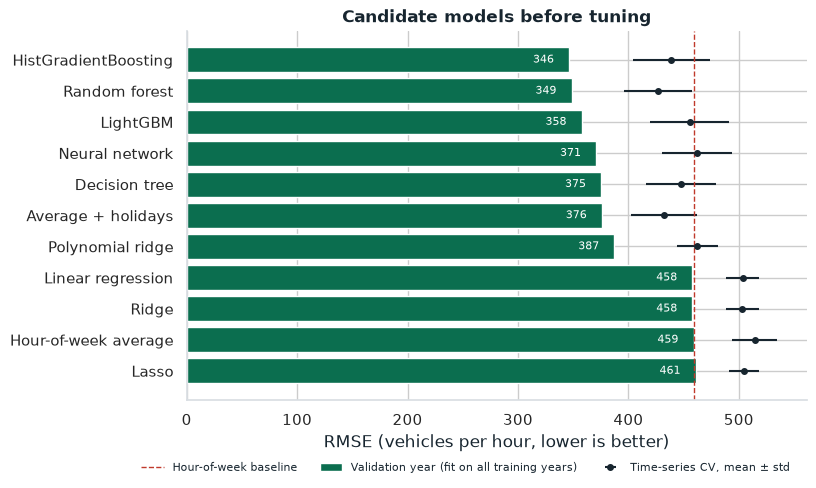

In [41]:
f = build_frames(clean, splits, cfg)
candidates = evaluate_regressors(f["X_train"], f["y_train"], f["X_validation"], f["y_validation"], f["cats"],
                                 f["nums"], cfg)
shown = candidates.drop(columns="notes").rename(columns={"val_mse": "validation MSE", "val_rmse": "validation RMSE",
                                                         "val_mae": "validation MAE", "val_r2": "validation R²"})
display(shown.round({"cv_rmse_mean": 1, "cv_rmse_std": 1, "validation MSE": 0, "validation RMSE": 1, "validation MAE": 1,
                     "validation R²": 4}))
finish_figure(plot_candidates(candidates), "models_candidates", ctx)

In [42]:
c = candidates.set_index("model")
best = candidates.iloc[0]
say(f"""
- **The baseline is already strong:** the hour-of-week average reaches validation R² **{c.loc['baseline', 'val_r2']:.3f}**
  (RMSE {c.loc['baseline', 'val_rmse']:.0f}). Most of the variance in traffic is the daily and weekly cycle, and
  any sensible model captures it. R² near 0.95 is therefore the starting point here, not an achievement.
- **Knowing the holidays is worth a great deal:** the same lookup table with quiet holidays as an eighth day
  type scores RMSE **{c.loc['baseline_holiday', 'val_rmse']:.0f}**, a cut of
  {1 - c.loc['baseline_holiday', 'val_rmse'] / c.loc['baseline', 'val_rmse']:.0%} from one rule and 24 more numbers.
- **The best candidate, {MODEL_LABELS[best['model']]}**, scores RMSE **{best['val_rmse']:.0f}** (MSE {best['val_mse']:,.0f}, MAE
  {best['val_mae']:.0f}, R² {best['val_r2']:.3f}): {1 - best['val_rmse'] / c.loc['baseline', 'val_rmse']:.0%} below
  the baseline but only {1 - best['val_rmse'] / c.loc['baseline_holiday', 'val_rmse']:.0%} below the holiday-aware
  table. That last figure is what the machine learning adds over a table anyone could compute.
- **Plain linear models barely match the baseline** (Ridge {c.loc['ridge', 'val_rmse']:.0f}): a weighted sum of
  features cannot give working days and weekends different daily shapes.
- **Cost:** the random forest's file is {c.loc['rf', 'size_kb'] / 1024:.0f} MB against
  {c.loc['hgb', 'size_kb'] / 1024:.1f} MB for HistGradientBoosting at the same accuracy; every model trains in
  seconds on this much data.
- The cross-validation errors are higher than the validation-year errors for every model because the early
  folds train on little data (the first fold on about {folds[0]['training hours']:,} hours) and are scored on
  the thin, gap-ridden years.
""")


- **The baseline is already strong:** the hour-of-week average reaches validation R² **0.946**
  (RMSE 459). Most of the variance in traffic is the daily and weekly cycle, and
  any sensible model captures it. R² near 0.95 is therefore the starting point here, not an achievement.
- **Knowing the holidays is worth a great deal:** the same lookup table with quiet holidays as an eighth day
  type scores RMSE **376**, a cut of
  18% from one rule and 24 more numbers.
- **The best candidate, HistGradientBoosting**, scores RMSE **346** (MSE 119,920, MAE
  224, R² 0.969): 25% below
  the baseline but only 8% below the holiday-aware
  table. That last figure is what the machine learning adds over a table anyone could compute.
- **Plain linear models barely match the baseline** (Ridge 458): a weighted sum of
  features cannot give working days and weekends different daily shapes.
- **Cost:** the random forest's file is 67 MB against
  0.3 MB for HistGradientBoosting at the same accuracy; every model trains in
  seconds on this much data.
- The cross-validation errors are higher than the validation-year errors for every model because the early
  folds train on little data (the first fold on about 6,318 hours) and are scored on
  the thin, gap-ridden years.


**Experiment: what would recent traffic counts add?** Section 1 ruled them out for a forecast made days
ahead. This experiment measures what is given up, horizon by horizon: a count from *k* hours ago can only
be used when the forecast is made less than *k* hours ahead. The counts are aligned on the true hourly clock,
so a gap in the series leaves a missing value instead of pairing hours that are not neighbours. Every row
uses the same model (HistGradientBoosting with default settings) fitted on the training years.

In [43]:
# Copied from traffic_volume.experiments
from __future__ import annotations

LAGS = {"lag_1h": 1, "lag_24h": 24, "lag_168h": 168}


LAG_HORIZONS = [
    ("Calendar and weather only (the deployed inputs)", [], "any horizon"),
    ("+ same hour last week", ["lag_168h"], "up to 7 days ahead"),
    ("+ same hour yesterday", ["lag_24h", "lag_168h"], "up to 1 day ahead"),
    ("+ previous hour", ["lag_1h", "lag_24h", "lag_168h"], "next hour only; needs a live count feed"),
]


LAG_MODEL = "hgb"


def lag_frame(clean: pd.DataFrame, target: str) -> pd.DataFrame:
    """Volume 1 hour, 1 day and 1 week earlier, aligned on the true hourly clock.

    The series has gaps, so shifting rows would pair hours that are not
    neighbours; reindexing to every hour first leaves a gap as a missing value.
    """
    series = clean.set_index("date_time")[target]
    grid = series.reindex(pd.date_range(series.index.min(), series.index.max(), freq="h"))
    lags = pd.DataFrame({name: grid.shift(k) for name, k in LAGS.items()})
    return lags.reindex(clean["date_time"]).set_index(clean.index)


def lag_experiment(X: pd.DataFrame, y: pd.Series, lags: pd.DataFrame, splits: dict, cfg: Config) -> pd.DataFrame:
    """Validation error with the lags that would be known at each forecast horizon.

    Every row uses the same model family with default settings (HistGradientBoosting, which accepts
    the missing values that gaps in the series leave in the lag columns), fitted on the training years.
    """
    rows = []
    known = lags.iloc[splits["train"]].notna().any()  # a lag with no values at all cannot be used (fast mode)
    for label, names, horizon in LAG_HORIZONS:
        names = [n for n in names if known[n]]
        frame = X.join(lags[names]) if names else X
        cats, nums = split_feature_types(list(frame.columns))
        model = make_regressor(LAG_MODEL, cats, nums, cfg)
        model.fit(frame.iloc[splits["train"]], y.iloc[splits["train"]])
        m = regression_metrics(y.iloc[splits["validation"]], model.predict(frame.iloc[splits["validation"]]))
        rows.append({"features": label, "lags": ", ".join(names) or "none", "usable": horizon, **m})
    avail = lags.iloc[splits["validation"]].notna().mean()
    out = pd.DataFrame(rows)
    out.attrs["lag_available_share"] = {k: float(v) for k, v in avail.items()}
    return out

,features,lags,usable,rmse,mae,r2
0,Calendar and weather only (the deployed inputs),none,any horizon,346.3,224.1,0.9695
1,+ same hour last week,lag_168h,up to 7 days ahead,341.1,220.7,0.9704
2,+ same hour yesterday,"lag_24h, lag_168h",up to 1 day ahead,316.4,205.1,0.9745
3,+ previous hour,"lag_1h, lag_24h, lag_168h",next hour only; needs a live count feed,240.8,156.6,0.9853


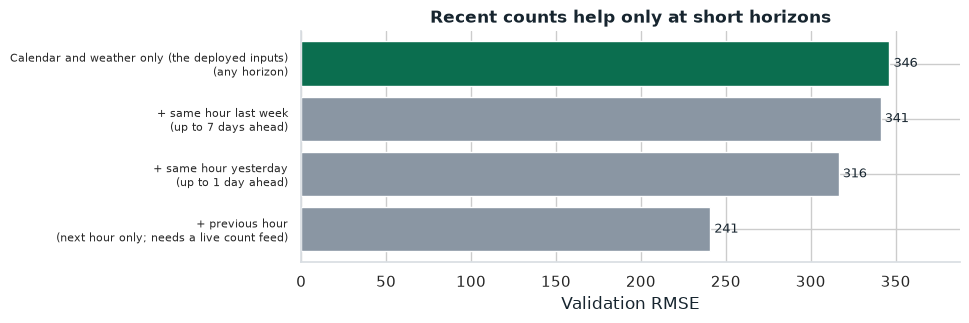

For planning **a week or more ahead** no recent count is available, and last week's count would add almost nothing anyway (RMSE 346 to 341). **A day ahead**, yesterday's count cuts the error to 316 (9% lower). For a true **next-hour** forecast the previous hour's count cuts it to **241** (30% lower). **Decision:** the deployed model is the planning model and uses none of them, because its inputs must be known days ahead and the API has no live feed of counts. A real-time service connected to the counter should add them; that is the first item under next steps.

In [44]:
lags = lag_experiment(f["X"], f["y"], lag_frame(clean, cfg.target), splits, cfg)
display(lags.drop(columns=["mse"]).round({"rmse": 1, "mae": 1, "r2": 4}))
finish_figure(plot_lag_experiment(lags), "models_lag_experiment", ctx)
lag_info = {"table": lags.to_dict("records"), "lag_available_share": lags.attrs["lag_available_share"],
            "settings": f"{LAG_MODEL}, default settings, every row"}
r = lags["rmse"].tolist()
say(f"For planning **a week or more ahead** no recent count is available, and last week's count would add "
    f"almost nothing anyway (RMSE {r[0]:.0f} to {r[1]:.0f}). **A day ahead**, yesterday's count cuts the error to "
    f"{r[2]:.0f} ({1 - r[2] / r[0]:.0%} lower). For a true **next-hour** forecast the previous hour's count cuts it "
    f"to **{r[3]:.0f}** ({1 - r[3] / r[0]:.0%} lower). **Decision:** the deployed model is the planning model and "
    "uses none of them, because its inputs must be known days ahead and the API has no live feed of counts. A "
    "real-time service connected to the counter should add them; that is the first item under next steps.")

## 6. Model evaluation and hyperparameter tuning

### 6.1 Hyperparameter tuning with grid search, random search and Bayesian optimisation

- **Grid search** on Ridge (the regularisation strength).
- **Random search** on the random forest and on HistGradientBoosting.
- **All three strategies on LightGBM with the same budget**, so they can be compared fairly: a grid over
  three settings, and random search and Bayesian optimisation (Optuna's TPE sampler) over eight.

Every search scores each configuration by time-series cross-validation inside the training years (the folds
shown in 3.5). The validation year is not used here, so it stays untouched for choosing the champion.

,search,strategy,model,configs_tried,fits,seconds,best_rmse,best_params
0,ridge_grid,grid,ridge,4,12,2.0,503.3,{'alpha': 1.0}
1,rf_random,random,rf,10,30,50.0,425.6,"{'max_depth': 12, 'max_features': 0.3, 'min_samples_leaf': 5, 'n_estimators': 141}"
2,hgb_random,random,hgb,16,48,177.0,432.9,"{'l2_regularization': 2.9154431891537547, 'learning_rate': 0.10185822566867639, 'max_i..."
3,lgbm_grid,grid,lgbm,16,48,103.0,430.0,"{'learning_rate': 0.03, 'n_estimators': 200, 'num_leaves': 31}"
4,lgbm_random,random,lgbm,16,48,105.0,434.5,"{'colsample_bytree': 0.8035171238433423, 'learning_rate': 0.02286036785892037, 'min_ch..."
5,lgbm_bayesian,bayesian,lgbm,16,48,65.0,425.7,"{'num_leaves': 31, 'learning_rate': 0.03171782305616059, 'n_estimators': 109, 'min_chi..."


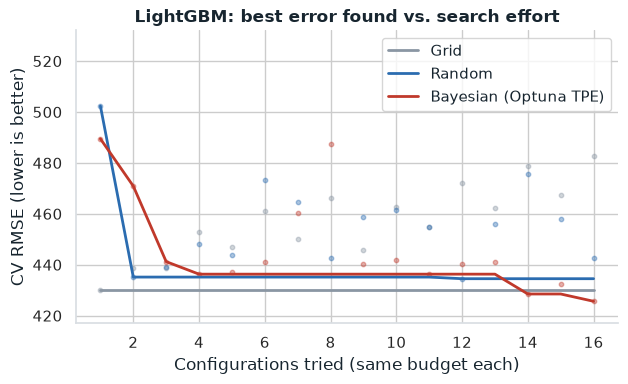

With the same budget (16 configurations each), the best cross-validated RMSE on LightGBM is: grid 430.0, random 434.5, Bayesian 425.7. The three finish within 8.9 vehicles per hour of each other, with Bayesian search ahead. Grid search can only find what is on its grid; random search covers more of the space for the same cost; Bayesian search uses earlier results to decide where to look next. On a problem this regular, with this budget, the choice of strategy matters less than the choice of features.

In [45]:
tuning = run_all_searches(f["X_train"], f["y_train"], f["cats"], f["nums"], cfg)
display(pd.DataFrame([{"search": k, **{kk: vv for kk, vv in v.items() if kk not in ("history", "best_so_far")}}
                      for k, v in tuning.items()]).round({"best_rmse": 1, "seconds": 0}))
finish_figure(plot_search_comparison(tuning), "tuning_strategies", ctx)
lg = {k: tuning[k]["best_rmse"] for k in ("lgbm_grid", "lgbm_random", "lgbm_bayesian")}
order = sorted(lg, key=lg.get)
say(f"With the same budget ({tuning['lgbm_grid']['configs_tried']} configurations each), the best cross-validated "
    f"RMSE on LightGBM is: grid {lg['lgbm_grid']:.1f}, random {lg['lgbm_random']:.1f}, Bayesian {lg['lgbm_bayesian']:.1f}. "
    f"The three finish within {max(lg.values()) - min(lg.values()):.1f} vehicles per hour of each other, with "
    f"{ {'lgbm_grid': 'grid', 'lgbm_random': 'random', 'lgbm_bayesian': 'Bayesian'}[order[0]] } search ahead. "
    f"Grid search can only find what is on its grid; random search covers "
    "more of the space for the same cost; Bayesian search uses earlier results to decide where to look next. On a "
    "problem this regular, with this budget, the choice of strategy matters less than the choice of features.")

### 6.2 Choosing the champion on the validation year

Cross-validation nominated one setting per family. The **validation year now decides** between the
finalists: every tree family with its tuned settings and with its default settings, each of those on **all
inputs** and on the **calendar inputs only** (hour, weekday, month, holiday: no weather). The rule was
written down before looking:

Selection rule: Lowest validation RMSE among the tree models (the ones the service can serve). Models within the tie tolerance count as equal, and the simplest of them wins: fewest input variables, then smallest file.


,model,variables,strategy,cv_rmse,val_mse,val_rmse,val_mae,val_r2,size_kb
4,"hgb, default settings, all inputs",9,default settings,NaN,119920.0,346.3,224.1,0.9695,357.0
3,"hgb, tuned, all inputs",9,random search,432.9,120687.0,347.4,228.1,0.9693,246.2
2,"rf, default settings, all inputs",9,default settings,NaN,121488.0,348.6,225.9,0.9691,68609.0
1,"rf, tuned, all inputs",9,random search,425.6,123727.0,351.7,228.6,0.9685,19986.6
10,"hgb, default settings, calendar only",4,default settings,NaN,124732.0,353.2,230.2,0.9683,354.0
7,"rf, tuned, calendar only",4,random search,425.6,126188.0,355.2,232.4,0.9679,19630.6
12,"lgbm, default settings, calendar only",4,default settings,NaN,126356.0,355.5,232.6,0.9678,2634.8
9,"hgb, tuned, calendar only",4,random search,432.9,126877.0,356.2,233.6,0.9677,243.1
8,"rf, default settings, calendar only",4,default settings,NaN,127319.0,356.8,234.9,0.9676,52890.9
6,"lgbm, default settings, all inputs",9,default settings,NaN,127907.0,357.6,230.2,0.9675,2623.8


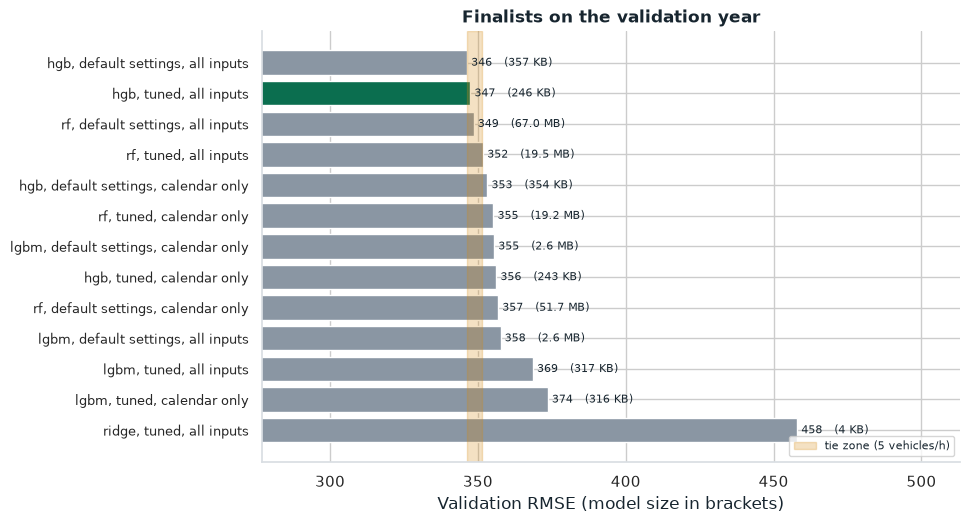

In [46]:
print("Selection rule:", choose_champion.__doc__.strip().replace("\n    ", " "))
fitted = fit_tuned(tuning, f, cfg)
champion = choose_champion(fitted, cfg)
finalist_table = pd.DataFrame(champion["comparison"]).drop(columns=["params", "kind", "tuned", "inputs"])
display(finalist_table.sort_values("val_rmse").round({"cv_rmse": 1, "val_mse": 0, "val_rmse": 1, "val_mae": 1, "val_r2": 4}))
finish_figure(plot_finalists(champion["comparison"], champion["label"], cfg.selection.tie_tolerance_rmse),
              "models_finalists", ctx)

In [47]:
cmp_ = {r["model"]: r for r in champion["comparison"]}
counterpart = cmp_[champion["counterpart_label"]]
all_inputs, calendar_only = (cmp_[champion["label"]], counterpart) if champion["inputs"] == "all" else (counterpart, cmp_[champion["label"]])
best_row = cmp_[champion["best_label"]]
tuned_vs_default = [(k, cmp_[finalist_label(k, True, 'all')]["val_rmse"], cmp_[finalist_label(k, False, 'all')]["val_rmse"])
                    for k in ("rf", "hgb", "lgbm")]
worse = [k for k, tuned_score, default_score in tuned_vs_default if tuned_score > default_score]
say(f"""
**Champion: {champion['label']}.** Validation RMSE **{champion['val_rmse']:.1f}** (MSE {champion['val_mse']:,.0f},
MAE {champion['val_mae']:.1f}, R² {champion['val_r2']:.4f}), file size {champion['size_kb']:,.0f} KB. Settings:
`{champion['params'] or 'library defaults'}`.

- The lowest validation RMSE of all is {best_row['val_rmse']:.1f} (*{champion['best_label']}*). The finalists
  within {cfg.selection.tie_tolerance_rmse:.0f} vehicles per hour of it count as equal:
  {'; '.join(champion['tied_models'])}. Among those the simplest wins: fewest input variables, then smallest file.
- **Does the weather earn its place?** For the champion's family and settings, all inputs score
  {all_inputs['val_rmse']:.1f} and the calendar inputs alone {calendar_only['val_rmse']:.1f}: the five weather
  variables change the validation error by {abs(all_inputs['val_rmse'] - calendar_only['val_rmse']):.1f} vehicles
  per hour ({abs(all_inputs['val_rmse'] - calendar_only['val_rmse']) / calendar_only['val_rmse']:.1%}), measured
  with the weather that was actually observed. Section 6b looks at the hours with rain and snow separately, and
  Section 6.3 asks what happens when the weather is not known.
- **Tuning did not always carry over to a new year.** On all inputs, tuned against default settings on the
  validation year: {'; '.join(f'{k} {a:.1f} vs {b:.1f}' for k, a, b in tuned_vs_default)}.
  {'For ' + ', '.join(worse) + ' the tuned settings are worse on the validation year than the defaults.' if worse else 'The tuned settings are at least as good as the defaults for every family.'}
  The searches optimise the average of folds that are scored on the thin early years (3.5), which is not the
  same thing as predicting 2017 from everything before it. This is why the champion is chosen on the
  validation year and why the default settings were kept in the comparison.
""")
champion_model = fitted[champion["label"]]["model"]
study_model = fitted[champion["all_inputs_label"]]["model"]  # sees every variable; used for importance in 6b


**Champion: hgb, tuned, all inputs.** Validation RMSE **347.4** (MSE 120,687,
MAE 228.1, R² 0.9693), file size 246 KB. Settings:
`{'l2_regularization': 2.9154431891537547, 'learning_rate': 0.10185822566867639, 'max_iter': 201, 'max_leaf_nodes': 10, 'min_samples_leaf': 31}`.

- The lowest validation RMSE of all is 346.3 (*hgb, default settings, all inputs*). The finalists
  within 5 vehicles per hour of it count as equal:
  hgb, default settings, all inputs; hgb, tuned, all inputs; rf, default settings, all inputs. Among those the simplest wins: fewest input variables, then smallest file.
- **Does the weather earn its place?** For the champion's family and settings, all inputs score
  347.4 and the calendar inputs alone 356.2: the five weather
  variables change the validation error by 8.8 vehicles
  per hour (2.5%), measured
  with the weather that was actually observed. Section 6b looks at the hours with rain and snow separately, and
  Section 6.3 asks what happens when the weather is not known.
- **Tuning did not always carry over to a new year.** On all inputs, tuned against default settings on the
  validation year: rf 351.7 vs 348.6; hgb 347.4 vs 346.3; lgbm 368.6 vs 357.6.
  For rf, hgb, lgbm the tuned settings are worse on the validation year than the defaults.
  The searches optimise the average of folds that are scored on the thin early years (3.5), which is not the
  same thing as predicting 2017 from everything before it. This is why the champion is chosen on the
  validation year and why the default settings were kept in the comparison.


### 6.3 Underfitting or overfitting?

Three pieces of evidence, all from training and validation data: the champion's error on the data it was
fitted on against its error on the validation year; a **learning curve** (does more history help?); and a
**complexity curve** (what happens as the model is given more or less capacity?).

,MSE,RMSE,MAE,R2
training years,137339.0,370.6,238.3,0.9651
validation year,120687.0,347.4,228.1,0.9693


,hours,training RMSE,training MAE,training R²
year,,,,
2012,2103,406.3,244.9,0.9589
2013,7294,364.1,236.9,0.9678
2014,4491,370.2,224.7,0.9654
2015,3590,358.9,225.9,0.9668
2016,7794,372.0,251.5,0.9630


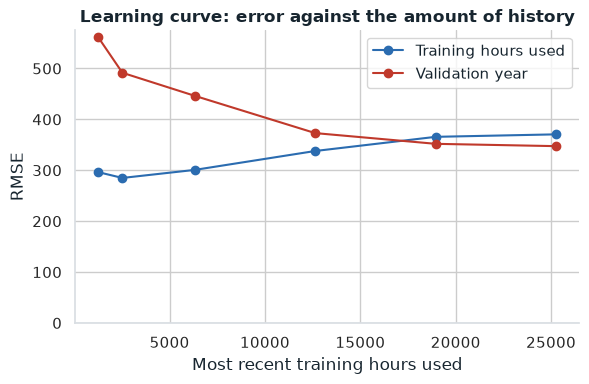

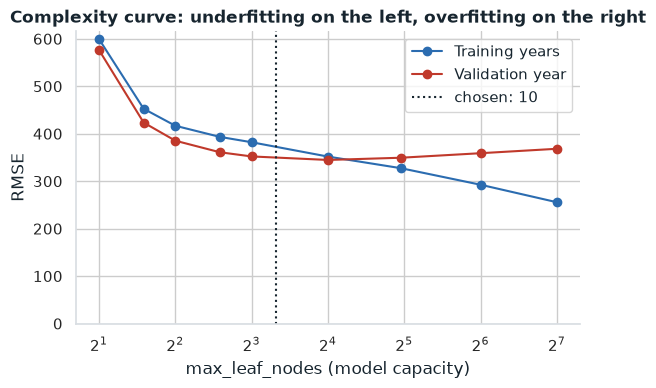

In [48]:
diag = diagnose(champion_model, champion, f, cfg)
display(pd.DataFrame({"training years": diag["train"], "validation year": diag["validation"]}).T
        .rename(columns=str.upper).round({"MSE": 0, "RMSE": 1, "MAE": 1, "R2": 4}))
display(pd.DataFrame(diag["train_by_year"]).set_index("year")[["hours", "rmse", "mae", "r2"]]
        .rename(columns={"rmse": "training RMSE", "mae": "training MAE", "r2": "training R²"}).round(
            {"training RMSE": 1, "training MAE": 1, "training R²": 4}))
finish_figure(plot_learning_curve(diag["learning_curve"]), "diag_learning_curve", ctx)
if diag["complexity_curve"]:
    finish_figure(plot_complexity_curve(diag["complexity_curve"]), "diag_complexity_curve", ctx)

In [49]:
lc, cc = diag["learning_curve"], diag["complexity_curve"]
say(f"""
**Verdict (generated from the numbers above):** training RMSE {diag['train']['rmse']:.0f}, validation RMSE
{diag['validation']['rmse']:.0f}. {diag['verdict']['text']}

- **Learning curve.** With only the most recent {lc['train_sizes'][0]:,} hours the validation error is
  {lc['val_rmse'][0]:.0f}; with all {lc['train_sizes'][-1]:,} it is {lc['val_rmse'][-1]:.0f}. The last step, from
  {lc['train_sizes'][-2]:,} to {lc['train_sizes'][-1]:,} hours, {'lowers' if lc['val_rmse'][-2] >= lc['val_rmse'][-1] else 'raises'} it by only {abs(lc['val_rmse'][-2] - lc['val_rmse'][-1]):.0f}:
  {'the curve has flattened, so more years of the same data would add little.' if abs(lc['val_rmse'][-2] - lc['val_rmse'][-1]) < 0.03 * lc['val_rmse'][-1] else 'the curve is still moving, so more history would probably still help.'}
""" + (f"""- **Complexity curve.** At the smallest capacity ({cc['param']} = {cc['values'][0]}) both errors are high and
  close together (training {cc['train_rmse'][0]:.0f}, validation {cc['val_rmse'][0]:.0f}): **underfitting**, the
  model is too simple for the pattern. As capacity grows the training error keeps falling (to
  {cc['train_rmse'][-1]:.0f}) while the validation error bottoms out at {min(cc['val_rmse']):.0f} and then
  {'rises again to ' + format(cc['val_rmse'][-1], '.0f') + ': the right-hand side is **overfitting**' if cc['val_rmse'][-1] > 1.01 * min(cc['val_rmse']) else 'stays flat: extra capacity is not used'}.
""" if cc else "") + """- The clearest example of underfitting in this notebook is in 6b: a straight line in the raw hour.
""")


**Verdict (generated from the numbers above):** training RMSE 371, validation RMSE
347. Validation error is 6% below training error: no overfitting. If anything the training years are the harder ones to fit; the table of training error by year shows which. On the complexity curve the validation error is lowest at max_leaf_nodes = 16 (345) and the chosen setting (10) is within 2% of it: more capacity would not help, so the model is not underfitting either.

- **Learning curve.** With only the most recent 1,264 hours the validation error is
  561; with all 25,272 it is 347. The last step, from
  18,954 to 25,272 hours, lowers it by only 5:
  the curve has flattened, so more years of the same data would add little.
- **Complexity curve.** At the smallest capacity (max_leaf_nodes = 2) both errors are high and
  close together (training 599, validation 576): **underfitting**, the
  model is too simple for the pattern. As capacity grows the training error keeps falling (to
  256) while the validation error bottoms out at 345 and then
  rises again to 368: the right-hand side is **overfitting**.
- The clearest example of underfitting in this notebook is in 6b: a straight line in the raw hour.


**What if the weather is not known?** The scores so far feed the model the weather that was observed in
each hour. A planner working weeks ahead has no weather information at all. The cell below scores the
champion on the validation year with each month's *typical* weather (median temperature and cloud cover, the
most common weather type, no rain or snow, all taken from the training years) in place of the real weather.

In [50]:
tw = diag["validation_typical_weather"]
say(f"""
| Validation year | RMSE | R² |
|---|---|---|
| Champion's settings, weather known exactly (observed) | {all_inputs['val_rmse']:.1f} | {all_inputs['val_r2']:.4f} |
| The all-inputs model given typical weather for the month | {tw['rmse']:.1f} | {tw['r2']:.4f} |
| The calendar-only model (never sees weather) | {calendar_only['val_rmse']:.1f} | {calendar_only['val_r2']:.4f} |

A weather forecast for a day or two ahead is somewhere between the first two rows. Beyond the reach of a
forecast, {'the calendar-only model is the better choice: a model trained to use the weather does slightly worse when handed typical weather than a model that never relied on it' if calendar_only['val_rmse'] <= tw['rmse'] else 'handing the weather model typical weather is the better choice'}.
**Consequence for deployment:** both models are exported (8.2), and the service answers with the
calendar-only model whenever a request carries no weather.
""")


| Validation year | RMSE | R² |
|---|---|---|
| Champion's settings, weather known exactly (observed) | 347.4 | 0.9693 |
| The all-inputs model given typical weather for the month | 356.8 | 0.9676 |
| The calendar-only model (never sees weather) | 356.2 | 0.9677 |

A weather forecast for a day or two ahead is somewhere between the first two rows. Beyond the reach of a
forecast, the calendar-only model is the better choice: a model trained to use the weather does slightly worse when handed typical weather than a model that never relied on it.
**Consequence for deployment:** both models are exported (8.2), and the service answers with the
calendar-only model whenever a request carries no weather.


### 6.4 Where the errors are (validation year)

One overall number hides where a model helps and where it fails. The champion and the hour-of-week baseline
are compared in each kind of hour, month by month and by weather.

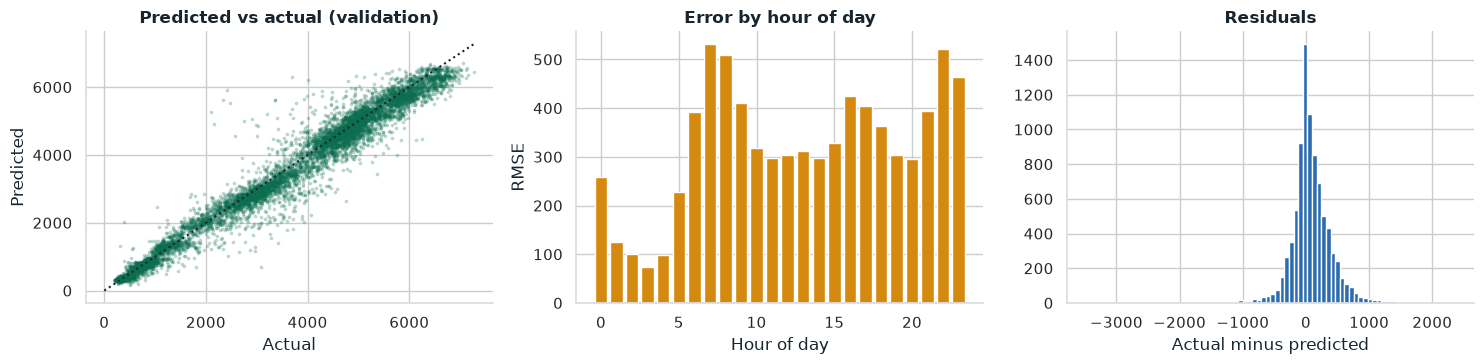

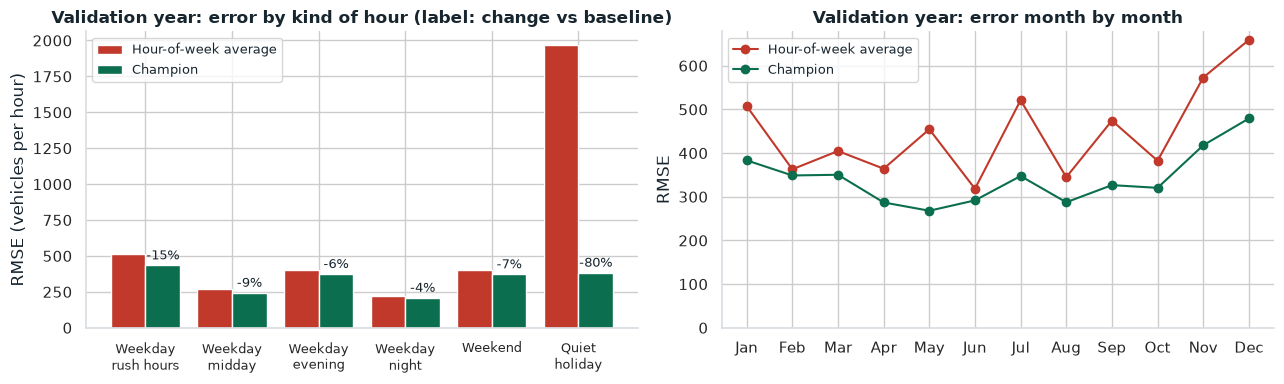

,hours,mean_volume,baseline_rmse,baseline_holiday_rmse,champion_rmse,reduction,share_of_hours,share_of_sq_error
group,,,,,,,,
Weekday rush hours,2014,5654.0,515.0,487.0,436.0,0.154,0.231,0.364
Weekday midday,1265,4858.0,269.0,262.0,245.0,0.089,0.145,0.072
Weekday evening,1012,2875.0,400.0,397.0,376.0,0.062,0.116,0.136
Weekday night,1765,987.0,219.0,213.0,210.0,0.038,0.203,0.074
Weekend,2513,2758.0,402.0,402.0,374.0,0.071,0.288,0.334
Quiet holiday,144,2125.0,1965.0,373.0,385.0,0.804,0.017,0.020


,hours,baseline_rmse,champion_rmse,reduction
group,,,,
Clear or cloudy,6043,466.033,342.461,0.265
Low visibility,803,415.463,317.486,0.236
Rain or storm,1288,362.300,318.887,0.120
Snow,579,610.183,475.490,0.221


,holiday,hours,mean,rmse
0,Christmas Day,24,150.0,311.0
1,Columbus Day,24,39.0,162.0
2,Independence Day,24,82.0,316.0
3,Labor Day,24,244.0,447.0
4,Martin Luther King Jr Day,24,-364.0,614.0
5,Memorial Day,24,44.0,293.0
6,New Years Day,24,295.0,566.0
7,State Fair,24,154.0,265.0
8,Thanksgiving Day,24,4.0,293.0
9,Veterans Day,24,228.0,335.0


,day,hours,rmse,mean_residual,holiday
0,2017-11-24,24,1365.0,-848.0,None
1,2017-12-05,21,1126.0,-652.0,None
2,2017-07-03,24,1033.0,-634.0,None
3,2017-12-26,24,826.0,-562.0,None
4,2017-01-10,24,811.0,-637.0,None
5,2017-03-01,24,777.0,-257.0,None
6,2017-12-28,24,777.0,-547.0,None
7,2017-12-02,24,721.0,569.0,None
8,2017-09-30,24,664.0,508.0,None
9,2017-01-11,24,634.0,-427.0,None


In [51]:
finish_figure(plot_residuals(diag["residuals"]), "diag_residuals", ctx)
finish_figure(plot_slices(diag["slices"], "Validation year"), "diag_slices_validation", ctx)
seg_val = pd.DataFrame(diag["slices"]["by_segment"]).set_index("group")
display(seg_val[["hours", "mean_volume", "baseline_rmse", "baseline_holiday_rmse", "champion_rmse", "reduction",
                 "share_of_hours", "share_of_sq_error"]].round({"mean_volume": 0, "baseline_rmse": 0, "baseline_holiday_rmse": 0,
                                                                "champion_rmse": 0, "reduction": 3, "share_of_hours": 3,
                                                                "share_of_sq_error": 3}))
display(pd.DataFrame(diag["slices"]["by_weather"]).set_index("group")[["hours", "baseline_rmse", "champion_rmse", "reduction"]].round(3))
display(pd.DataFrame(diag["residuals"]["by_named_day"]).round(0))
display(pd.DataFrame(diag["residuals"]["worst_days"]).round(0))

In [52]:
hol, rush = seg_val.loc["Quiet holiday"], seg_val.loc["Weekday rush hours"]
ordinary = seg_val.drop(index="Quiet holiday")
ordinary_cut = 1 - np.sqrt((ordinary["champion_rmse"] ** 2 * ordinary["hours"]).sum() / ordinary["hours"].sum()) / \
    np.sqrt((ordinary["baseline_rmse"] ** 2 * ordinary["hours"]).sum() / ordinary["hours"].sum())
worst_day = diag["residuals"]["worst_days"][0]
period_val = {r["group"]: r for r in diag["slices"]["by_period"]}
say(f"""
- **Quiet holidays are where the model earns most of its advantage.** They are {hol['share_of_hours']:.1%} of the
  hours; there the baseline's RMSE is {hol['baseline_rmse']:,.0f} and the champion's {hol['champion_rmse']:,.0f}
  ({hol['reduction']:.0%} lower). On all other hours together the champion's RMSE is {ordinary_cut:.0%} below the
  baseline's.
- **Rush hours are the hardest ordinary hours:** RMSE {rush['champion_rmse']:,.0f} on a mean volume of
  {rush['mean_volume']:,.0f}, against {seg_val.loc['Weekday night', 'champion_rmse']:,.0f} at night. Rush-hour
  traffic is the most sensitive to incidents and to days when many people stay at home.
- **The worst day** is {worst_day['day']} (RMSE {worst_day['rmse']:,.0f}, mean error {worst_day['mean_residual']:+,.0f}).
  The days in that table are mostly days when far fewer vehicles came than the calendar suggests: the day after
  Thanksgiving, days between Christmas and New Year, and days with incidents or heavy snow. A model that knows
  only the calendar and the weather cannot see them coming.
- **The last quarter is harder than the rest of the year:** RMSE {period_val['October to December']['champion_rmse']:,.0f}
  in October to December against {period_val['January to September']['champion_rmse']:,.0f} in January to
  September. This matters in Section 8, because the test year has no last quarter.
""")


- **Quiet holidays are where the model earns most of its advantage.** They are 1.7% of the
  hours; there the baseline's RMSE is 1,965 and the champion's 385
  (80% lower). On all other hours together the champion's RMSE is 10% below the
  baseline's.
- **Rush hours are the hardest ordinary hours:** RMSE 436 on a mean volume of
  5,654, against 210 at night. Rush-hour
  traffic is the most sensitive to incidents and to days when many people stay at home.
- **The worst day** is 2017-11-24 (RMSE 1,365, mean error -848).
  The days in that table are mostly days when far fewer vehicles came than the calendar suggests: the day after
  Thanksgiving, days between Christmas and New Year, and days with incidents or heavy snow. A model that knows
  only the calendar and the weather cannot see them coming.
- **The last quarter is harder than the rest of the year:** RMSE 411
  in October to December against 323 in January to
  September. This matters in Section 8, because the test year has no last quarter.


### 6.5 What the champion has learned (validation year)

Permutation importance shuffles one feature at a time and measures how much the validation error rises;
SHAP values show how each feature moves individual predictions, in vehicles per hour.

In [53]:
# Copied from traffic_volume.explain
from __future__ import annotations

def permutation_frame(model, X_val: pd.DataFrame, y_val, cfg: Config) -> pd.DataFrame:
    """Increase in validation RMSE when each derived feature is shuffled."""
    r = permutation_importance(model, X_val, y_val, scoring="neg_root_mean_squared_error",
                               n_repeats=cfg.explain.permutation_repeats, random_state=cfg.seed, n_jobs=1)
    return (pd.DataFrame({"feature": X_val.columns, "rmse_increase": r.importances_mean, "std": r.importances_std})
            .sort_values("rmse_increase", ascending=False).reset_index(drop=True))


def shap_values_for(model, X_val: pd.DataFrame, cfg: Config) -> shap.Explanation:
    """SHAP values (vehicles per hour) for a sample of validation hours, for tree models."""
    sample = X_val.sample(n=min(cfg.explain.shap_rows, len(X_val)), random_state=cfg.seed)
    names = list(model.named_steps["prep"].get_feature_names_out())
    transformed = pd.DataFrame(model[:-1].transform(sample), columns=names, index=sample.index)
    return shap.TreeExplainer(model.named_steps["model"])(transformed)


def shap_frame(values: shap.Explanation) -> pd.DataFrame:
    return (pd.DataFrame({"feature": values.feature_names, "mean_abs_shap": np.abs(values.values).mean(0)})
            .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))

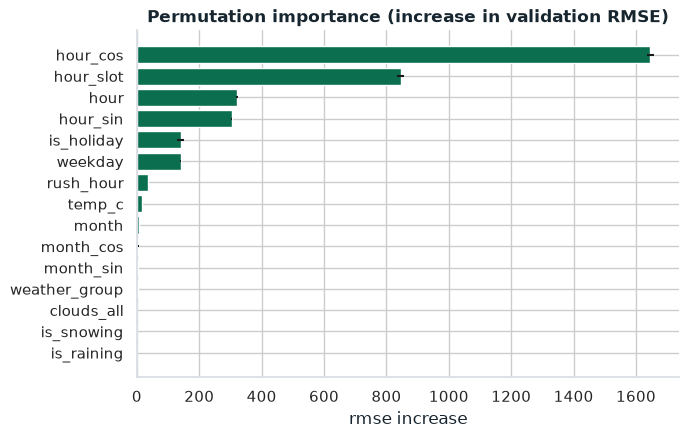

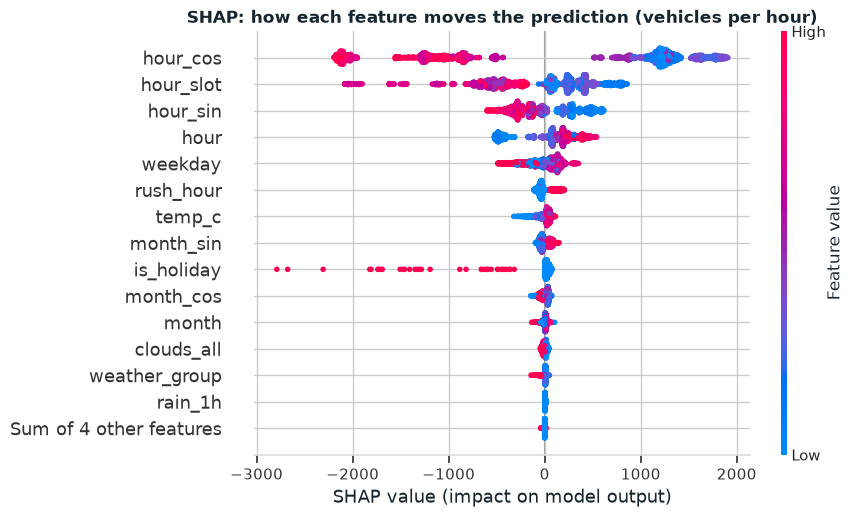

In [54]:
perm = permutation_frame(champion_model, f["X_validation"], f["y_validation"], cfg)
finish_figure(plot_importance(perm, "rmse_increase", "std", "Permutation importance (increase in validation RMSE)"),
              "explain_permutation", ctx)
values = shap_values_for(champion_model, f["X_validation"], cfg)
shap_imp = shap_frame(values)
finish_figure(plot_shap_summary(values), "explain_shap_summary", ctx)

## 6b. Feature importance and univariate, bivariate and multivariate models

This section answers three questions the instructor asked for in addition to the assignment sheet: which
variables matter, how well a model does on **one** variable (univariate), on **two** (bivariate) and on
**all** of them (multivariate).

**The unit of analysis is the raw variable**, not the engineered feature: hour, weekday, month, holiday,
temperature, rain, snow, clouds and weather type. One variable can become several features (the hour becomes
`hour`, `hour_sin` and `hour_cos`), and some features need two variables (`rush_hour` needs the hour and the
weekday). A model "on the hour" may use every feature made from the hour alone and none that also needs
another variable.

### Step 1: which variables matter? Five rankings

| Method | What it measures | Data |
|---|---|---|
| Association with the target | Correlation ratio (eta) for discrete variables, absolute Pearson correlation for continuous ones | Training years |
| Mutual information | Any dependence, including non-linear | Training years |
| Grouped permutation importance | Shuffle one raw variable, recompute every feature made from it, and measure the rise in RMSE | Validation year |
| Tree importance | How much the model's splits on the variable reduce the error (shared features are split equally between their variables) | The model itself |
| SHAP | Mean absolute contribution to a prediction, summed per variable | Validation year |

The first two look at the data alone; the last three look at a fitted model. The model used is the
champion's family and settings **on all nine variables**, so that every variable can be ranked even if the
champion itself leaves some out.

,association,mutual_information,permutation_rmse_increase,tree_gain,shap,association_rank,mutual_information_rank,permutation_rmse_increase_rank,tree_gain_rank,shap_rank,mean_rank
variable,,,,,,,,,,,
hour,0.883,1.226,2342.877,4.373979e+11,1540.254,1.0,1.0,1.0,1.0,1.0,1.0
weekday,0.227,0.138,830.194,4.405772e+10,299.045,2.0,2.0,2.0,2.0,2.0,2.0
temp,0.148,0.053,16.090,2.061008e+09,48.771,3.0,3.0,5.0,4.0,4.0,3.8
month,0.068,0.032,22.337,2.019900e+09,67.037,6.0,4.0,4.0,5.0,3.0,4.4
is_holiday,0.086,0.010,141.317,1.024106e+10,45.758,5.0,7.0,3.0,3.0,5.0,4.6
weather_main,0.118,0.012,3.493,2.495948e+08,14.026,4.0,6.0,6.0,7.0,7.0,6.0
clouds_all,0.044,0.013,0.964,2.638420e+08,14.905,7.0,5.0,7.0,6.0,6.0,6.2
rain_1h,0.014,0.001,0.000,1.325040e+08,5.223,8.0,9.0,8.0,8.0,8.0,8.2
snow_1h,0.002,0.001,0.000,4.749380e+07,0.704,9.0,8.0,8.0,9.0,9.0,8.6


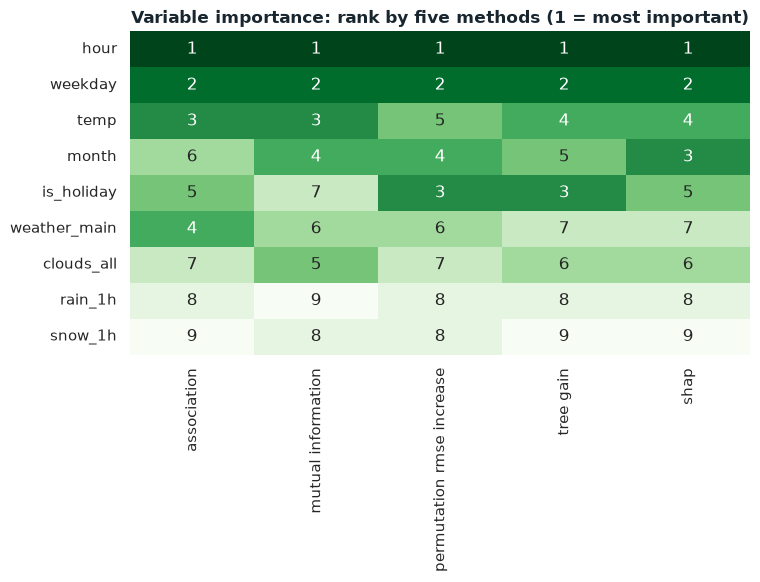

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
feature,temp_c,month_cos,is_weekend,month_sin,month,hour_sin,weekday,hour,clouds_all,rush_hour,is_raining,hour_cos,is_snowing,rain_1h,is_holiday,snow_1h
vif,4.8,4.8,2.8,2.7,2.7,2.7,2.6,2.6,1.3,1.3,1.2,1.2,1.2,1.1,1.0,1.0


**hour** is ranked first by 5 of the 5 methods and **weekday** second by 5 of 5. Below the top two the methods disagree, which is itself informative: `is_holiday` is ranked 5th by association and 7th by mutual information (holidays are rare, so over the whole year they explain little) but 3rd by permutation importance (when it matters, it matters a lot). Shuffling the hour raises the validation RMSE by 2,343 vehicles per hour; shuffling the most important weather variable raises it by 16.1. **Multicollinearity:** the highest variance inflation factor is 4.8 (`temp_c`), below the usual concern level of 10, so the linear models' coefficients are stable.

In [55]:
ranking = rank_variables(f["raw_train"], f["y_train"], f["raw_validation"], f["y_validation"], study_model, values_all := shap_values_for(study_model, f["X_validation"], cfg), cfg)
display(ranking.round(3))
finish_figure(plot_variable_ranks(ranking), "study_variable_ranks", ctx)
vif = vif_table(f["X_train"])
display(vif.round(1).T)
rank_cols = [c for c in ranking.columns if c.endswith("_rank") and c != "mean_rank"]
agree_first = int((ranking[rank_cols].iloc[0] == 1).sum())
agree_second = int((ranking[rank_cols].iloc[1] == 2).sum())
hol_rank = ranking.loc["is_holiday"]


def nth(n) -> str:
    n = int(n)
    return f"{n}{'th' if 10 <= n % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(n % 10, 'th')}"


say(f"**{ranking.index[0]}** is ranked first by {agree_first} of the 5 methods and **{ranking.index[1]}** second by "
    f"{agree_second} of 5. Below the top two the methods disagree, which is itself informative: `is_holiday` is "
    f"ranked {nth(hol_rank['association_rank'])} by association and {nth(hol_rank['mutual_information_rank'])} by "
    f"mutual information (holidays are rare, so over the whole year they explain little) but "
    f"{nth(hol_rank['permutation_rmse_increase_rank'])} by permutation importance (when it matters, it matters a "
    f"lot). Shuffling the hour raises the validation RMSE by "
    f"{ranking.loc['hour', 'permutation_rmse_increase']:,.0f} vehicles per hour; shuffling the most important weather "
    f"variable raises it by {ranking.loc[['temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main'], 'permutation_rmse_increase'].max():.1f}. "
    f"**Multicollinearity:** the highest variance inflation factor is {vif.iloc[0]['vif']:.1f} (`{vif.iloc[0]['feature']}`), "
    f"{'below' if vif.iloc[0]['vif'] < 10 else 'above'} the usual concern level of 10, so the linear models' coefficients are stable.")

### Step 2: models on one variable, two variables and all variables

The top one and top two variables are taken from the ranking above. Four model families, from rigid to
flexible, show how much of the result is the variable and how much is the model:

- **linear, raw:** least squares on the untransformed variable only (for the hour: the number 0 to 23);
- **linear:** least squares on all of the variable's engineered features (for the hour: also its sine and cosine);
- **spline:** a smooth flexible curve (periodic for the hour, so that midnight joins up);
- **tree:** the champion's family with its settings.

A cyclical encoding turns one variable into several columns, but the model is still **univariate**: it uses
one variable. For contrast, the same four models are fitted on the main weather variable, temperature.

,model,variables,family,features_used,mse,rmse,mae,r2
0,univariate,hour,linear_raw,1,3408046.0,1846.1,1640.5,0.1329
1,univariate,hour,linear,3,1269381.0,1126.7,837.4,0.6770
2,univariate,hour,spline,3,833034.0,912.7,638.3,0.7880
3,univariate,hour,tree,3,813828.0,902.1,624.6,0.7929
4,bivariate,"hour, weekday",linear,7,252576.0,502.6,320.3,0.9357
5,bivariate,"hour, weekday",tree,7,210726.0,459.0,277.0,0.9464
6,multivariate,"hour, weekday, month, is_holiday, temp, rain_1h, snow_1h, clouds_all, weather_main",linear,18,209698.0,457.9,307.7,0.9466
7,multivariate,"hour, weekday, month, is_holiday, temp, rain_1h, snow_1h, clouds_all, weather_main",tree,18,120687.0,347.4,228.1,0.9693
8,univariate (raw weather),temp,linear_raw,1,3868168.0,1966.8,1716.0,0.0158
9,univariate (raw weather),temp,linear,1,3868168.0,1966.8,1716.0,0.0158


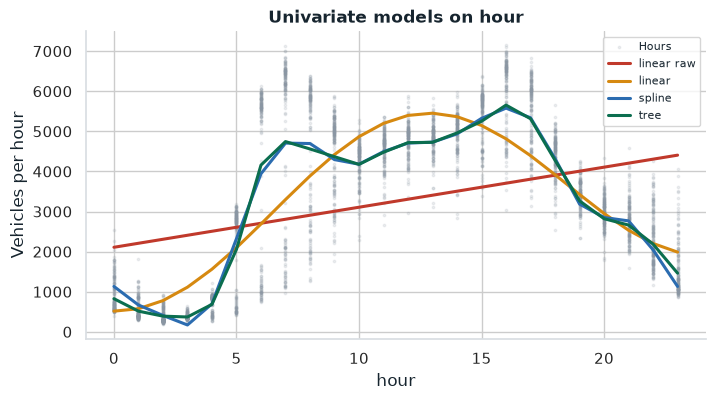

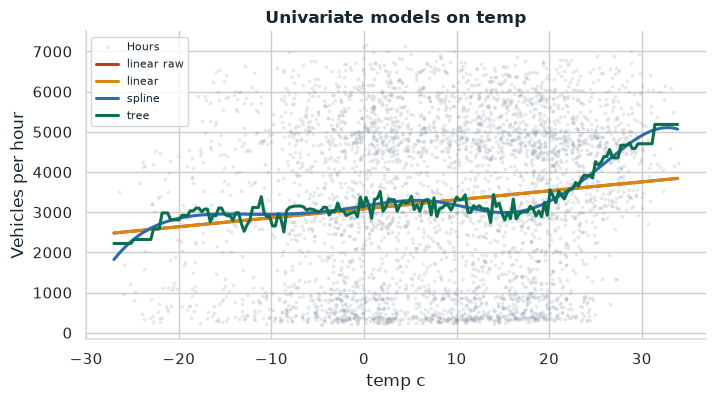

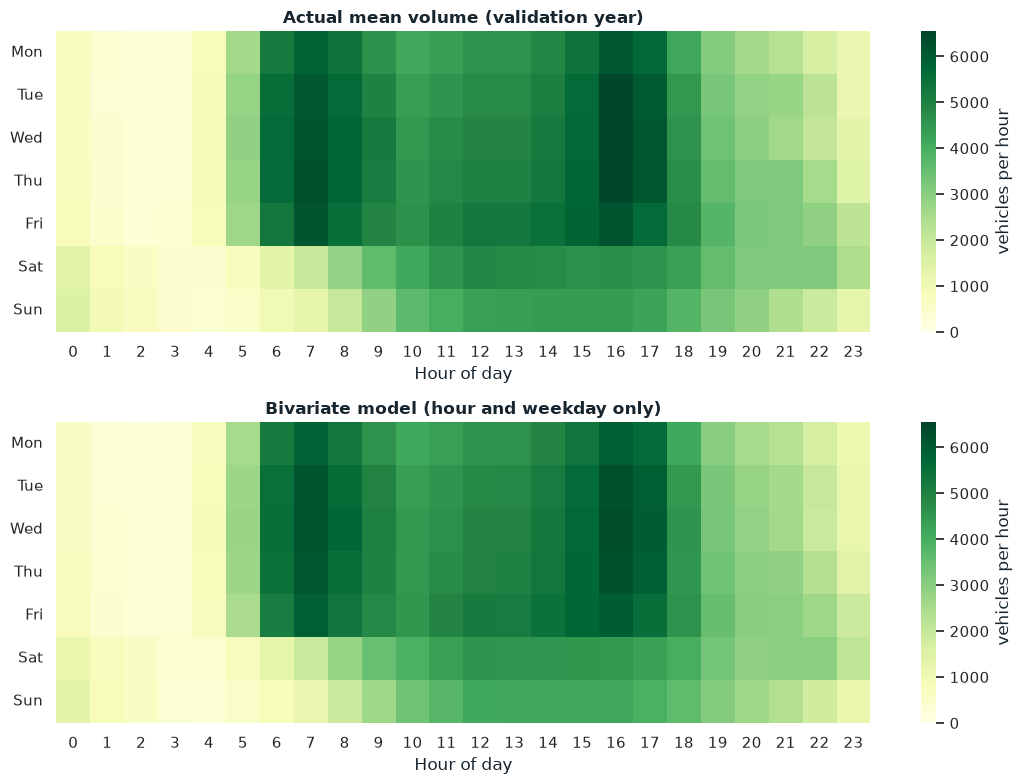

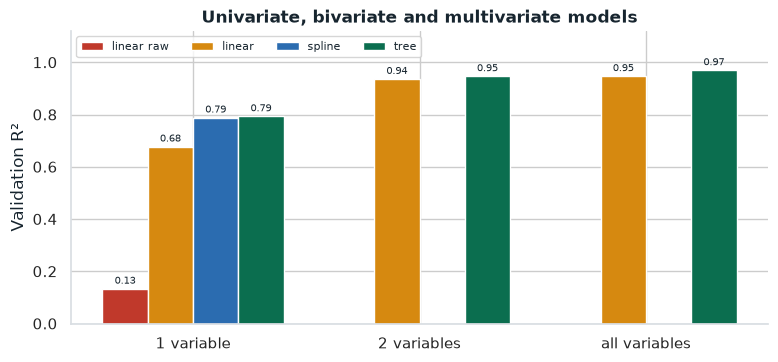

In [56]:
study = variable_models(f["X"], f["y"], splits, ranking, champion["params"], cfg, champion["name"])
display(study["table"].round({"mse": 0, "rmse": 1, "mae": 1, "r2": 4}))
finish_figure(plot_univariate_fits(study["curves"], f["X_validation"], f["y_validation"], study["top1"][0],
                                   "univariate"), "study_univariate", ctx)
finish_figure(plot_univariate_fits(study["curves"], f["X_validation"], f["y_validation"],
                                   cfg.feature_study.contrast_variable, "univariate (raw weather)"),
              "study_univariate_weather", ctx)
actual_tab, predicted_tab = bivariate_surface(f["X"], f["y"], splits, study["top2"], champion["params"], cfg,
                                              champion["name"])
finish_figure(plot_bivariate_surface(actual_tab, predicted_tab), "study_bivariate_surface", ctx)
finish_figure(plot_variable_models(study["table"]), "study_variable_models", ctx)

In [57]:
t = study["table"].set_index(["model", "family"])
uni, bi, multi = "univariate", "bivariate", "multivariate"
say(f"""
- **Univariate ({study['top1'][0]}).** A straight line in the raw hour reaches R² **{t.loc[(uni, 'linear_raw'), 'r2']:.2f}**
  (RMSE {t.loc[(uni, 'linear_raw'), 'rmse']:,.0f}): it badly **underfits**, because traffic rises and falls twice a
  day and a line can only go one way. The *same variable* with a cyclical encoding lifts linear regression to
  {t.loc[(uni, 'linear'), 'r2']:.2f}, a periodic spline to {t.loc[(uni, 'spline'), 'r2']:.2f} and a tree to
  **{t.loc[(uni, 'tree'), 'r2']:.2f}** (RMSE {t.loc[(uni, 'tree'), 'rmse']:,.0f}). The hour alone, read flexibly,
  explains about four fifths of the variance. How a variable is encoded matters as much as which variable it is.
- **Bivariate ({' and '.join(study['top2'])}).** The tree reaches R² **{t.loc[(bi, 'tree'), 'r2']:.3f}** (RMSE
  {t.loc[(bi, 'tree'), 'rmse']:,.0f}), essentially the hour-of-week baseline ({c.loc['baseline', 'val_rmse']:.0f}),
  which is a lookup table of the same two variables. The linear model on the same two variables reaches
  {t.loc[(bi, 'linear'), 'r2']:.3f}: the gap is the *interaction* between hour and weekday (weekends have a
  different daily shape), which a tree finds and a sum of separate effects cannot. The two heatmaps above show
  that the bivariate model reproduces the weekly pattern.
- **Multivariate (all nine variables).** The tree reaches R² **{t.loc[(multi, 'tree'), 'r2']:.3f}** (RMSE
  {t.loc[(multi, 'tree'), 'rmse']:,.0f}); the linear model stays at {t.loc[(multi, 'linear'), 'r2']:.3f}. Going
  from two variables to nine cuts the tree's RMSE by {1 - t.loc[(multi, 'tree'), 'rmse'] / t.loc[(bi, 'tree'), 'rmse']:.0%}
  and adds {t.loc[(multi, 'tree'), 'r2'] - t.loc[(bi, 'tree'), 'r2']:.3f} to R².
- **Contrast: temperature alone** reaches R² {t.loc[('univariate (raw weather)', 'tree'), 'r2']:.3f} with the most
  flexible model. A raw weather variable explains almost nothing on its own.
""")


- **Univariate (hour).** A straight line in the raw hour reaches R² **0.13**
  (RMSE 1,846): it badly **underfits**, because traffic rises and falls twice a
  day and a line can only go one way. The *same variable* with a cyclical encoding lifts linear regression to
  0.68, a periodic spline to 0.79 and a tree to
  **0.79** (RMSE 902). The hour alone, read flexibly,
  explains about four fifths of the variance. How a variable is encoded matters as much as which variable it is.
- **Bivariate (hour and weekday).** The tree reaches R² **0.946** (RMSE
  459), essentially the hour-of-week baseline (459),
  which is a lookup table of the same two variables. The linear model on the same two variables reaches
  0.936: the gap is the *interaction* between hour and weekday (weekends have a
  different daily shape), which a tree finds and a sum of separate effects cannot. The two heatmaps above show
  that the bivariate model reproduces the weekly pattern.
- **Multivariate (all nine variables).** The tree reaches R² **0.969** (RMSE
  347); the linear model stays at 0.947. Going
  from two variables to nine cuts the tree's RMSE by 24%
  and adds 0.023 to R².
- **Contrast: temperature alone** reaches R² 0.020 with the most
  flexible model. A raw weather variable explains almost nothing on its own.


### Step 3: which of the remaining variables carry the multivariate gain?

Two views of the same question. First the variables are added **one at a time**, in the order of the
ranking. Then they are added **in groups** (the calendar, the holiday flag, the weather), with the error
reported separately for the hours with rain, storm or snow, where the weather ought to matter most.

,variables,added,mse,rmse,mae,r2
0,1,hour,813828.0,902.1,624.6,0.7929
1,2,weekday,210726.0,459.0,277.0,0.9464
2,3,temp,193713.0,440.1,260.2,0.9507
3,4,month,184660.0,429.7,261.6,0.9530
4,5,is_holiday,124149.0,352.3,230.5,0.9684
5,6,weather_main,121568.0,348.7,228.5,0.9691
6,7,clouds_all,121400.0,348.4,228.8,0.9691
7,8,rain_1h,121879.0,349.1,228.5,0.9690
8,9,snow_1h,120687.0,347.4,228.1,0.9693


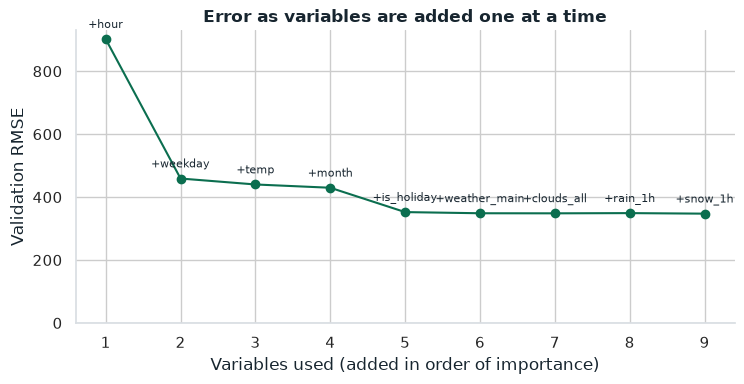

,inputs,variables,features_used,mse,rmse,mae,r2,rmse_rain_storm_snow,rmse_dry
0,Hour and weekday,2,7,210726.0,459.0,277.0,0.9464,454.0,460.4
1,+ month,3,10,187265.0,432.7,263.2,0.9524,417.4,436.8
2,+ holiday (all calendar inputs),4,11,126877.0,356.2,233.6,0.9677,380.9,349.2
3,+ weather (all inputs),9,18,120687.0,347.4,228.1,0.9693,374.5,339.6


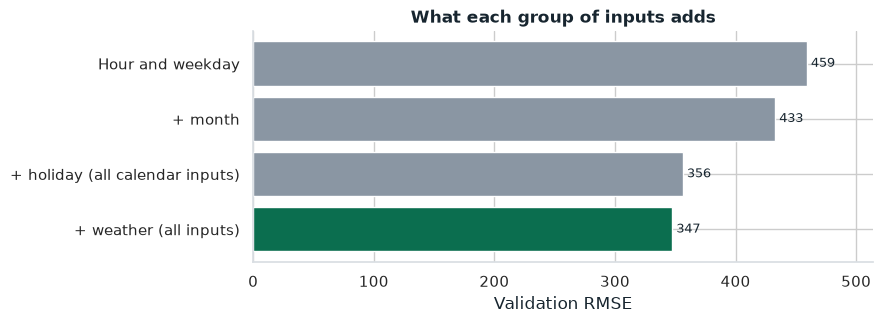

In [58]:
display(study["incremental"].round({"mse": 0, "rmse": 1, "mae": 1, "r2": 4}))
finish_figure(plot_incremental(study["incremental"]), "study_incremental", ctx)
ablation = group_ablation(f["X"], f["y"], splits, clean, champion["params"], cfg, champion["name"])
display(ablation.round({"mse": 0, "rmse": 1, "mae": 1, "r2": 4, "rmse_rain_storm_snow": 1, "rmse_dry": 1}))
finish_figure(plot_group_ablation(ablation), "study_group_ablation", ctx)

In [59]:
g = ablation.set_index("inputs")
steps = g["rmse"].tolist()
weather_change = steps[3] - steps[2]
wet_change = g["rmse_rain_storm_snow"].iloc[3] - g["rmse_rain_storm_snow"].iloc[2]
say(f"""
- **Hour and weekday:** RMSE {steps[0]:.0f}. **Adding the month** (the season): {steps[1]:.0f}
  ({1 - steps[1] / steps[0]:.0%} lower). **Adding the holiday flag:** {steps[2]:.0f}
  ({1 - steps[2] / steps[1]:.0%} lower again). These four calendar variables carry the whole gain.
- **Adding all five weather variables** changes the RMSE by {weather_change:+.1f} vehicles per hour, to {steps[3]:.0f}.
  On the {ablation.attrs['wet_hours']:,} validation hours with rain, storm or snow, where weather should matter
  most, it changes by {wet_change:+.1f} (from {g['rmse_rain_storm_snow'].iloc[2]:.0f} to {g['rmse_rain_storm_snow'].iloc[3]:.0f}).
- **Conclusion.** {'The weather inputs do not improve the forecast, even in bad weather.' if weather_change > -0.01 * steps[2] else f'The weather inputs give a small improvement: {-weather_change / steps[2]:.1%} of the error, about the same in dry hours as in wet ones.'}
  Set against the calendar this is minor: the month and the holiday flag together cut the error by
  {1 - steps[2] / steps[0]:.0%}, the weather by a further {max(-weather_change, 0) / steps[2]:.1%}. It agrees with
  the exploration in 3.3 (the weather barely moves the volume). The practical consequence is that almost
  everything the model knows is known from the calendar alone, years ahead, so the worry in Section 1 about
  using observed weather where a planner would only have a forecast concerns the last
  {max(-weather_change, 0) / steps[2]:.1%}, not the result as a whole.
""")
study_ids = {"top1": study["top1"], "top2": study["top2"]}


- **Hour and weekday:** RMSE 459. **Adding the month** (the season): 433
  (6% lower). **Adding the holiday flag:** 356
  (18% lower again). These four calendar variables carry the whole gain.
- **Adding all five weather variables** changes the RMSE by -8.8 vehicles per hour, to 347.
  On the 1,867 validation hours with rain, storm or snow, where weather should matter
  most, it changes by -6.4 (from 381 to 375).
- **Conclusion.** The weather inputs give a small improvement: 2.5% of the error, about the same in dry hours as in wet ones.
  Set against the calendar this is minor: the month and the holiday flag together cut the error by
  22%, the weather by a further 2.5%. It agrees with
  the exploration in 3.3 (the weather barely moves the volume). The practical consequence is that almost
  everything the model knows is known from the calendar alone, years ahead, so the worry in Section 1 about
  using observed weather where a planner would only have a forecast concerns the last
  2.5%, not the result as a whole.


## 8. Model testing and deployment

### 8.1 Final evaluation on the test year

**The models scored were fixed in the configuration beforehand.** Each is **refitted on the training and
validation years together** (for a time series the most recent year is the most valuable) and then scored
on 2018, with the same four metrics as on the validation year. Confidence intervals resample whole days,
because neighbouring hours are not independent evidence.

**This is the second time the test year has been scored, and this must be said plainly.** The first
evaluation (11 November 2026) scored a random forest that used all eleven named days as holidays. A review
afterwards found four defects: the holiday flag included ordinary commuting days; three holidays were not
marked at all; road-closure hours were in the training data; and HistGradientBoosting, a much smaller model
of equal accuracy, had never been among the tuned finalists. All four were fixed, **and every choice was
made on training and validation data** (Sections 3.2 and 6.2), without looking at the test year. The test
year was then scored again. Both results are shown below. A test set that has been used twice is a slightly
less clean estimate than one used once; the change was accepted because the defects were real and because
no decision was taken from test results.

Models declared for the test pass: ['baseline', 'baseline_holiday', 'ridge', 'univariate', 'bivariate', 'alternative_inputs', 'champion']


,model,what it is,features,test MSE,test RMSE,test MAE,test R²
0,baseline,Hour-of-week average,2,219008.0,468.0,264.6,0.9438
1,baseline_holiday,Average + holidays,3,156446.0,395.5,237.5,0.9599
2,ridge,Ridge (linear),18,213848.0,462.4,299.7,0.9451
3,univariate,Hour only,3,829988.0,911.0,618.8,0.7871
4,bivariate,Hour + weekday,7,219242.0,468.2,264.9,0.9438
5,alternative_inputs,"Champion's settings, calendar only (no weather)",11,142459.0,377.4,223.4,0.9635
6,champion,Champion,18,135400.0,368.0,220.7,0.9653


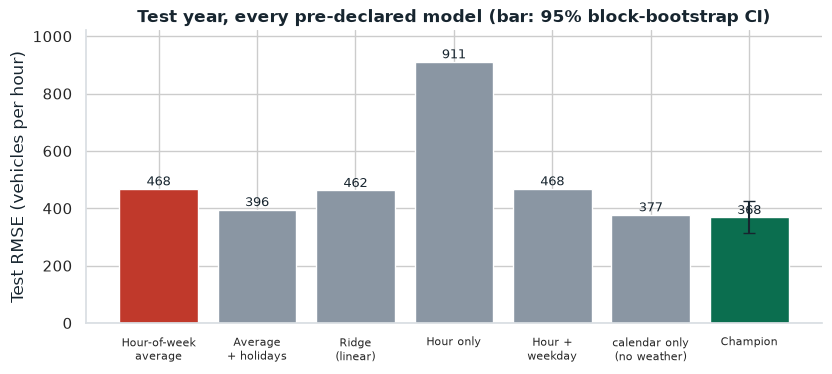

In [60]:
print("Models declared for the test pass:", cfg.test_pass_models)
test = final_test(test_pass_models(champion, tuning, study_ids, f, cfg), f, cfg)
test_table = pd.DataFrame([{"model": n, "what it is": TEST_MODEL_LABELS.get(n, n).replace("\n", " ") if n != "alternative_inputs"
                            else "Champion's settings, " + r["label"], "features": r["features"], **r["metrics"]}
                           for n, r in test["models"].items()])
display(test_table.rename(columns={"mse": "test MSE", "rmse": "test RMSE", "mae": "test MAE", "r2": "test R²"})
        .round({"test MSE": 0, "test RMSE": 1, "test MAE": 1, "test R²": 4}))
finish_figure(plot_test_results(test), "test_results", ctx)

In [61]:
cm, ci, s = test["models"]["champion"]["metrics"], test["models"]["champion"]["ci"], test["success"]
bm, hm = test["models"]["baseline"]["metrics"], test["models"]["baseline_holiday"]["metrics"]
am = test["models"]["alternative_inputs"]
pb, ph, pa = test["paired"]["baseline"]["rmse_reduction"], test["paired"]["baseline_holiday"]["rmse_reduction"], \
    test["paired"]["alternative_inputs"]["rmse_reduction"]
fe = cfg.first_evaluation
say(f"""
**Champion on the test year ({champion['label']}):**

| Metric | Test year | 95% interval | Validation year |
|---|---|---|---|
| MSE | {cm['mse']:,.0f} | {ci['mse']['low']:,.0f} to {ci['mse']['high']:,.0f} | {champion['val_mse']:,.0f} |
| RMSE (vehicles per hour) | **{cm['rmse']:.0f}** | {ci['rmse']['low']:.0f} to {ci['rmse']['high']:.0f} | {champion['val_rmse']:.0f} |
| MAE (vehicles per hour) | {cm['mae']:.0f} | {ci['mae']['low']:.0f} to {ci['mae']['high']:.0f} | {champion['val_mae']:.0f} |
| R² | **{cm['r2']:.3f}** | {ci['r2']['low']:.3f} to {ci['r2']['high']:.3f} | {champion['val_r2']:.3f} |

**Against the baseline, which is the comparison that matters:**

- Hour-of-week baseline: RMSE {bm['rmse']:.0f}, R² **{bm['r2']:.3f}**. The champion's RMSE is **{s['rmse_reduction_vs_baseline']:.0%} lower**
  (95% interval {pb['low']:.0%} to {pb['high']:.0%}, from resampling the same days for both models). In terms of
  squared error, the champion removes {s['mse_reduction_vs_baseline']:.0%} of the error the baseline leaves.
- The holiday-aware lookup table: RMSE {hm['rmse']:.0f}, R² {hm['r2']:.3f}. Against this fairer reference the
  champion's RMSE is **{s['rmse_reduction_vs_holiday_table']:.0%} lower** ({ph['low']:.0%} to {ph['high']:.0%}).
  {'The interval excludes zero: the model is better than the table, by a modest margin.' if ph['low'] > 0 else 'The interval includes zero: on this test year the model is not clearly better than the table.'}
- The same model on the other input set ({am['label']}): RMSE {am['metrics']['rmse']:.0f}. The champion is
  {abs(pa['point']):.1%} {'lower' if pa['point'] > 0 else 'higher'} ({pa['low']:.1%} to {pa['high']:.1%}).
- **When the weather is not known:** the champion given each month's typical weather scores RMSE
  {test['models']['champion']['typical_weather_metrics']['rmse']:.0f} on the test year. So the figure to quote
  for a forecast made weeks ahead is **{min(am['metrics']['rmse'], test['models']['champion']['typical_weather_metrics']['rmse']) if champion['inputs'] == 'all' else cm['rmse']:.0f}**
  ({'the calendar-only model' if champion['inputs'] == 'all' else 'the champion, which uses the calendar only'}), and
  **{cm['rmse']:.0f}** is what is reached when the weather of the hour is known exactly.

**Verdict against the criteria of Section 1:**

- Test R² of at least {cfg.success.r2}: **{'met' if s['r2_target_met'] else 'not met'}** ({cm['r2']:.3f}). But the
  baseline {'also meets it' if s['baseline_also_meets_r2_target'] else 'does not'} ({bm['r2']:.3f}), so this
  criterion {'did not separate a good model from a lookup table: it was set too low' if s['baseline_also_meets_r2_target'] else 'separated the model from the baseline'}.
- Lower RMSE than the hour-of-week baseline: **{'met' if s['beats_baseline'] else 'not met'}**, and the interval
  for the reduction {'excludes' if s['reduction_ci_excludes_zero'] else 'includes'} zero.

**The two evaluations of the test year, side by side:**

| | First evaluation ({fe['date']}) | Second evaluation (reported) |
|---|---|---|
| Champion | {MODEL_LABELS[fe['champion']]}, tuned, all inputs; {fe['model_kb'] / 1024:.0f} MB as deployed | {MODEL_LABELS[champion['name']]}: {champion['label']} |
| Named days treated as holidays | all eleven | the six quiet ones |
| Validation RMSE | {fe['validation_rmse']:.0f} | {champion['val_rmse']:.0f} |
| Test R² | {fe['test_r2']:.3f} | {cm['r2']:.3f} |
| Test RMSE | {fe['test_rmse']:.0f} | {cm['rmse']:.0f} |
| Test MAE | {fe['test_mae']:.0f} | {cm['mae']:.0f} |
| Hour-of-week baseline, test RMSE | {fe['baseline_test_rmse']:.0f} | {bm['rmse']:.0f} |
""")


**Champion on the test year (hgb, tuned, all inputs):**

| Metric | Test year | 95% interval | Validation year |
|---|---|---|---|
| MSE | 135,400 | 97,600 to 182,341 | 120,687 |
| RMSE (vehicles per hour) | **368** | 312 to 427 | 347 |
| MAE (vehicles per hour) | 221 | 202 to 243 | 228 |
| R² | **0.965** | 0.953 to 0.975 | 0.969 |

**Against the baseline, which is the comparison that matters:**

- Hour-of-week baseline: RMSE 468, R² **0.944**. The champion's RMSE is **21% lower**
  (95% interval 9% to 33%, from resampling the same days for both models). In terms of
  squared error, the champion removes 38% of the error the baseline leaves.
- The holiday-aware lookup table: RMSE 396, R² 0.960. Against this fairer reference the
  champion's RMSE is **7% lower** (4% to 10%).
  The interval excludes zero: the model is better than the table, by a modest margin.
- The same model on the other input set (calendar only (no weather)): RMSE 377. The champion is
  2.5% lower (0.3% to 4.4%).
- **When the weather is not known:** the champion given each month's typical weather scores RMSE
  385 on the test year. So the figure to quote
  for a forecast made weeks ahead is **377**
  (the calendar-only model), and
  **368** is what is reached when the weather of the hour is known exactly.

**Verdict against the criteria of Section 1:**

- Test R² of at least 0.9: **met** (0.965). But the
  baseline also meets it (0.944), so this
  criterion did not separate a good model from a lookup table: it was set too low.
- Lower RMSE than the hour-of-week baseline: **met**, and the interval
  for the reduction excludes zero.

**The two evaluations of the test year, side by side:**

| | First evaluation (2026-11-11) | Second evaluation (reported) |
|---|---|---|
| Champion | Random forest, tuned, all inputs; 12 MB as deployed | HistGradientBoosting: hgb, tuned, all inputs |
| Named days treated as holidays | all eleven | the six quiet ones |
| Validation RMSE | 376 | 347 |
| Test R² | 0.964 | 0.965 |
| Test RMSE | 376 | 368 |
| Test MAE | 223 | 221 |
| Hour-of-week baseline, test RMSE | 468 | 468 |


**Where the model helps and where it does not (test year).** The same slices as in 6.4.

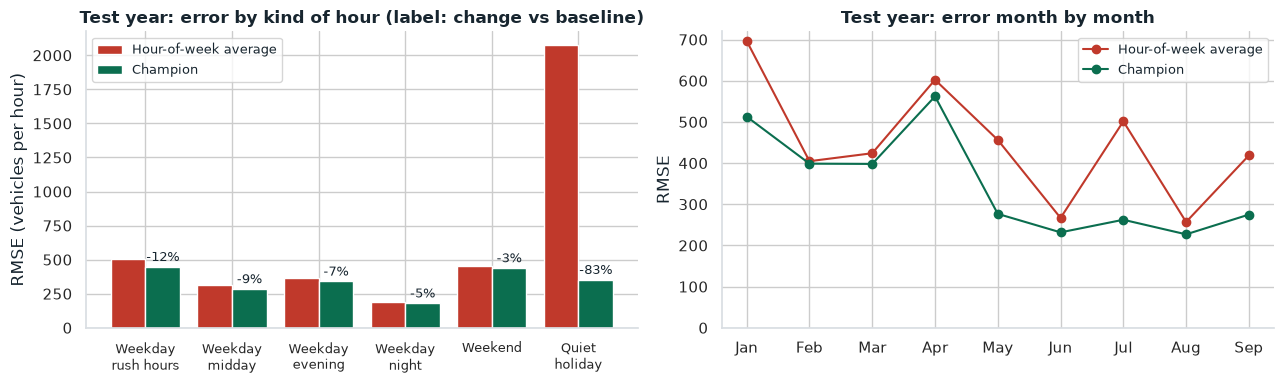

,hours,mean_volume,baseline_rmse,baseline_holiday_rmse,champion_rmse,reduction,share_of_sq_error
group,,,,,,,
Weekday rush hours,1525,5586.0,508.0,501.0,448.0,0.118,0.346
Weekday midday,955,4801.0,313.0,318.0,285.0,0.090,0.088
Weekday evening,764,2809.0,365.0,365.0,341.0,0.068,0.100
Weekday night,1331,985.0,189.0,181.0,180.0,0.052,0.049
Weekend,1862,2664.0,453.0,453.0,438.0,0.032,0.404
Quiet holiday,96,2032.0,2072.0,405.0,352.0,0.830,0.013


group,1,2,3,4,5,6,7,8,9
hours,742.000,672.000,733.000,720.000,743.000,719.000,744.000,740.000,720.000
baseline_rmse,696.000,405.000,424.000,602.000,456.000,267.000,501.000,257.000,419.000
baseline_holiday_rmse,591.000,411.000,421.000,595.000,281.000,248.000,273.000,243.000,293.000
champion_rmse,513.000,399.000,398.000,562.000,277.000,232.000,262.000,227.000,275.000
reduction,0.264,0.015,0.061,0.067,0.394,0.131,0.477,0.117,0.343


,hours,baseline_rmse,alternative_inputs_rmse,champion_rmse,reduction
group,,,,,
Clear or cloudy,4324,415.0,296.0,297.0,0.285
Low visibility,604,271.0,234.0,230.0,0.149
Rain or storm,1089,438.0,264.0,265.0,0.394
Snow,516,917.0,926.0,875.0,0.045


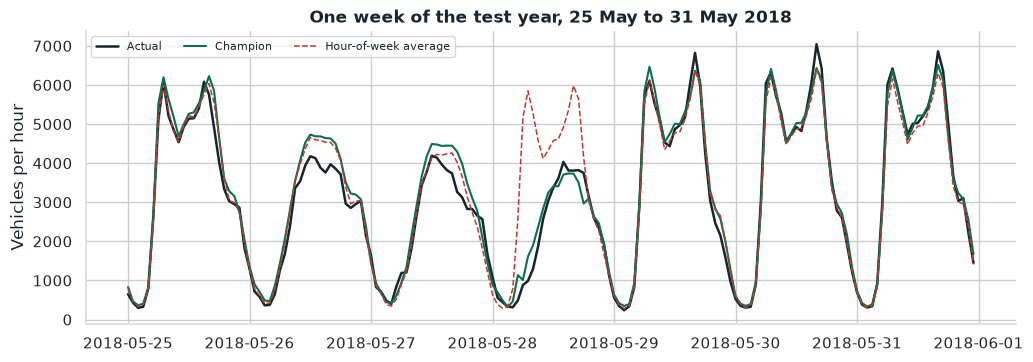

In [62]:
finish_figure(plot_slices(test["slices"], "Test year"), "test_slices", ctx)
seg_test = pd.DataFrame(test["slices"]["by_segment"]).set_index("group")
display(seg_test[["hours", "mean_volume", "baseline_rmse", "baseline_holiday_rmse", "champion_rmse", "reduction",
                  "share_of_sq_error"]].round({"mean_volume": 0, "baseline_rmse": 0, "baseline_holiday_rmse": 0,
                                               "champion_rmse": 0, "reduction": 3, "share_of_sq_error": 3}))
month_test = pd.DataFrame(test["slices"]["by_month"]).set_index("group")
display(month_test[["hours", "baseline_rmse", "baseline_holiday_rmse", "champion_rmse", "reduction"]].round(
    {"baseline_rmse": 0, "baseline_holiday_rmse": 0, "champion_rmse": 0, "reduction": 3}).T)
weather_test = pd.DataFrame(test["slices"]["by_weather"]).set_index("group")
display(weather_test[["hours", "baseline_rmse", "alternative_inputs_rmse", "champion_rmse", "reduction"]].round(
    {"baseline_rmse": 0, "alternative_inputs_rmse": 0, "champion_rmse": 0, "reduction": 3}))
week = test_week_frame(test["frame"], f["clean_test"])
finish_figure(plot_test_week(week), "test_week", ctx)

In [63]:
hol_t = seg_test.loc["Quiet holiday"] if "Quiet holiday" in seg_test.index else None
worst_month, best_month = month_test["reduction"].idxmin(), month_test["reduction"].idxmax()
hardest_month = month_test["champion_rmse"].idxmax()
weakest_segment = seg_test.drop(index="Quiet holiday", errors="ignore")["reduction"].idxmin()
same_months = period_val["January to September"]
say(f"""
- **Holidays.** {'On the ' + format(int(hol_t['hours'])) + ' quiet-holiday hours the baseline RMSE is ' + format(hol_t['baseline_rmse'], ',.0f') + ' and the champion RMSE ' + format(hol_t['champion_rmse'], ',.0f') + ' (' + format(hol_t['reduction'], '.0%') + ' lower); the holiday-aware table scores ' + format(hol_t['baseline_holiday_rmse'], ',.0f') + '.' if hol_t is not None else 'No quiet holiday in the test hours.'}
- **Ordinary hours.** The smallest gain is in the *{weakest_segment.lower()}* hours ({seg_test.loc[weakest_segment, 'reduction']:.0%});
  rush hours remain the largest source of error ({seg_test.loc['Weekday rush hours', 'share_of_sq_error']:.0%} of the
  champion's squared error from {seg_test.loc['Weekday rush hours', 'share_of_hours']:.0%} of the hours).
- **Month by month.** The champion beats the baseline in {int((month_test['reduction'] > 0).sum())} of
  {len(month_test)} months. The gain is largest in {MONTHS[int(best_month) - 1]} ({month_test.loc[best_month, 'reduction']:.0%})
  and smallest in {MONTHS[int(worst_month) - 1]} ({month_test.loc[worst_month, 'reduction']:.0%}). The hardest month
  for the champion is {MONTHS[int(hardest_month) - 1]} (RMSE {month_test.loc[hardest_month, 'champion_rmse']:,.0f}).
- **Bad weather.** In rain or storm the champion's RMSE is {weather_test.loc['Rain or storm', 'champion_rmse']:,.0f},
  {'no higher than' if weather_test.loc['Rain or storm', 'champion_rmse'] <= weather_test.loc['Clear or cloudy', 'champion_rmse'] else 'higher than'} in clear or cloudy hours ({weather_test.loc['Clear or cloudy', 'champion_rmse']:,.0f}). **Snow is
  different: RMSE {weather_test.loc['Snow', 'champion_rmse']:,.0f}.** The {int(weather_test.loc['Snow', 'hours']):,} snow
  hours are {weather_test.loc['Snow', 'hours'] / weather_test['hours'].sum():.0%} of the test hours and produce
  **{pd.DataFrame(test['slices']['by_weather']).set_index('group').loc['Snow', 'share_of_sq_error']:.0%} of the champion's squared error**;
  even the baseline does no better there ({weather_test.loc['Snow', 'baseline_rmse']:,.0f}). Heavy snow keeps
  people off the road, and the model cannot tell a flurry from a blizzard: the data's snow amount is empty
  for most years (3.1), so all it sees is the label "Snow". This is the model's largest weakness.

**Is the test year representative? Not entirely, and the estimate should be read with that in mind.**

- The data ends in September 2018, so the test year has **no October to December**, the quarter with
  Thanksgiving, Christmas and the hardest hours. On the validation year the champion's RMSE was
  {period_val['October to December']['champion_rmse']:,.0f} in that quarter against {same_months['champion_rmse']:,.0f}
  in January to September. A full year would therefore probably score **worse** than the {cm['rmse']:.0f} reported here.
- **Comparing like with like:** validation year, January to September only: RMSE {same_months['champion_rmse']:,.0f}.
  Test year, the same months: **{cm['rmse']:.0f}**, which is {cm['rmse'] / same_months['champion_rmse'] - 1:+.0%}.
  That is the honest size of the gap between the year the model was chosen on and a new year, even though the
  test model had one more year of training data.
- The test year itself is almost complete ({split_info['test']['rows']:,} of 6,552 hours), so gaps are not the
  issue; it is one year, on one road, and it contains only {int(round(hol_t['hours'] / 24)) if hol_t is not None else 0}
  of the six quiet holidays.
  The confidence intervals above say how much the score could move with a different set of days.
""")


- **Holidays.** On the 96 quiet-holiday hours the baseline RMSE is 2,072 and the champion RMSE 352 (83% lower); the holiday-aware table scores 405.
- **Ordinary hours.** The smallest gain is in the *weekend* hours (3%);
  rush hours remain the largest source of error (35% of the
  champion's squared error from 23% of the hours).
- **Month by month.** The champion beats the baseline in 9 of
  9 months. The gain is largest in Jul (48%)
  and smallest in Feb (1%). The hardest month
  for the champion is Apr (RMSE 562).
- **Bad weather.** In rain or storm the champion's RMSE is 265,
  no higher than in clear or cloudy hours (297). **Snow is
  different: RMSE 875.** The 516 snow
  hours are 8% of the test hours and produce
  **45% of the champion's squared error**;
  even the baseline does no better there (917). Heavy snow keeps
  people off the road, and the model cannot tell a flurry from a blizzard: the data's snow amount is empty
  for most years (3.1), so all it sees is the label "Snow". This is the model's largest weakness.

**Is the test year representative? Not entirely, and the estimate should be read with that in mind.**

- The data ends in September 2018, so the test year has **no October to December**, the quarter with
  Thanksgiving, Christmas and the hardest hours. On the validation year the champion's RMSE was
  411 in that quarter against 323
  in January to September. A full year would therefore probably score **worse** than the 368 reported here.
- **Comparing like with like:** validation year, January to September only: RMSE 323.
  Test year, the same months: **368**, which is +14%.
  That is the honest size of the gap between the year the model was chosen on and a new year, even though the
  test model had one more year of training data.
- The test year itself is almost complete (6,533 of 6,552 hours), so gaps are not the
  issue; it is one year, on one road, and it contains only 4
  of the six quiet holidays.
  The confidence intervals above say how much the score could move with a different set of days.


### 8.2 Export for deployment

The champion, fitted on the training and validation years, is converted to **ONNX**, so the API needs only
the small `onnxruntime` library and not scikit-learn. When the champion uses the weather, the calendar-only
model from the test pass is exported beside it, for requests that carry no weather (6.3). A metadata file
carries the feature order, the category codes, the list of quiet holidays and each model's test results.
**Parity check:** for 200 hours of the validation year, each exported model (shared feature code, then
category codes, then ONNX) must reproduce its scikit-learn pipeline to within 0.01 vehicles per hour.

In [64]:
# Copied from traffic_volume.export
from __future__ import annotations

WEATHER_VARIABLES = ["temp", "rain_1h", "snow_1h", "clouds_all", "weather_main"]


def category_codes(model, cats: list[str]) -> dict[str, dict[str, float]]:
    """The code the fitted encoder gives each training category (grouped rare ones share a code)."""
    if not cats:
        return {}
    encoder = model.named_steps["prep"].named_transformers_["cat"]
    vocab = {}
    for j, col in enumerate(cats):
        known = list(encoder.categories_[j])
        probe = pd.DataFrame({c: [encoder.categories_[i][0]] * len(known) for i, c in enumerate(cats)})
        probe[col] = known
        vocab[col] = {str(k): float(v) for k, v in zip(known, encoder.transform(probe)[:, j])}
    return vocab


@contextmanager
def plain_tree_attributes():
    """Work around a mismatch between skl2onnx and the current ONNX library.

    For HistGradientBoosting, skl2onnx describes the trees with lists that contain booleans and NumPy
    integers; ONNX now refuses those where it expects plain integers ("Expected an int, got a boolean").
    While a conversion runs, every such value is turned into a plain int before it reaches ONNX. The
    values themselves are unchanged, and the parity check after every export confirms the result.
    """
    from skl2onnx.common._container import ModelComponentContainer

    original = ModelComponentContainer.add_node

    def add_node(self, *args, **attrs):
        fixed = {k: [int(v) if isinstance(v, (bool, np.bool_, np.integer)) else v for v in value]
                 if isinstance(value, list) else value for k, value in attrs.items()}
        return original(self, *args, **fixed)

    ModelComponentContainer.add_node = add_node
    try:
        yield
    finally:
        ModelComponentContainer.add_node = original


def to_onnx(model, n_features: int, path: Path) -> Path:
    """Convert the fitted regressor (after preprocessing) to ONNX with float32 input.

    The converters stamp each file with a random graph name and list the operator sets in no fixed
    order; both are fixed here so that the same model always gives the same bytes, and therefore the
    same version string in the notebook, the pipeline and the service.
    """
    est = model.named_steps["model"]
    if type(est).__name__ == "LGBMRegressor":
        from onnxmltools import convert_lightgbm
        from onnxmltools.convert.common.data_types import FloatTensorType as LgbmFloat
        onx = convert_lightgbm(est, initial_types=[("input", LgbmFloat([None, n_features]))], target_opset=15)
    else:
        from skl2onnx import convert_sklearn
        from skl2onnx.common.data_types import FloatTensorType
        with plain_tree_attributes():
            onx = convert_sklearn(est, initial_types=[("input", FloatTensorType([None, n_features]))], target_opset=15)
    onx.graph.name = "traffic_volume"
    onx.doc_string = ""
    onx.producer_name, onx.producer_version = "traffic-volume", "1"
    opsets = sorted((o.domain, o.version) for o in onx.opset_import)
    del onx.opset_import[:]
    for domain, version in opsets:
        entry = onx.opset_import.add()
        entry.domain, entry.version = domain, version
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(onx.SerializeToString(deterministic=True))
    return path


def onnx_predict(path: Path, X32: np.ndarray) -> np.ndarray:
    options = ort.SessionOptions()
    options.log_severity_level = 3
    session = ort.InferenceSession(str(path), options, providers=["CPUExecutionProvider"])
    return np.asarray(session.run(None, {session.get_inputs()[0].name: X32.astype(np.float32)})[0]).ravel()


def model_block(model, name: str, cats: list[str], nums: list[str], sources: list[str], test_metrics: dict,
                path: Path) -> dict:
    """Convert one fitted pipeline and describe it: everything the service needs to run that model.

    ``cats``, ``nums`` and ``sources`` describe the whole feature frame; the model's own inputs are read
    from the fitted pipeline, which may use fewer."""
    used = list(model.named_steps["prep"].get_feature_names_out())
    to_onnx(model, len(used), path)
    digest = hashlib.sha256(Path(path).read_bytes()).hexdigest()[:12]
    cats, nums = [c for c in cats if c in used], [c for c in nums if c in used]
    needed = {v for feature in used for v in FEATURE_INPUTS[feature]}
    variables = [v for v in RAW_VARIABLES if v in needed]
    return {
        "model_version": f"{name}-{digest}", "file": Path(path).name,
        "inputs": "calendar and weather" if set(variables) & set(WEATHER_VARIABLES) else "calendar only",
        "input_variables": variables,
        "feature_sources": [s for s in sources if set(FEATURE_SOURCES[s](dict.fromkeys(RAW_VARIABLES, 0))) & set(used)],
        "input_order": used, "categorical_features": cats, "numeric_features": nums, "unknown_category_code": -1.0,
        "category_codes": category_codes(model, cats), "test_metrics": test_metrics,
    }


def export_metadata(primary: dict, fallback: dict | None, champion: dict, cfg: Config,
                    reference: dict | None = None) -> dict:
    """The metadata file. The champion's block sits at the top level; ``fallback`` is the calendar-only
    model, present when the champion needs the weather; ``reference`` holds the test results of the two
    lookup tables, so that the service can show the model's error next to theirs."""
    return {
        **primary,
        "validation_metrics": {k: champion[f"val_{k}"] for k in ("mse", "rmse", "mae", "r2")},
        "test_reference": reference or {},
        "test_year_evaluations": 2,
        "first_evaluation": cfg.first_evaluation,
        "trained_utc": datetime.now(UTC).strftime("%Y-%m-%dT%H:%M:%SZ"),
        "task": "regression: westbound I-94 vehicles per hour at ATR station 301 (Minneapolis-St Paul)",
        "estimator": champion["name"], "params": champion["params"],
        "trained_on": f"hours up to {cfg.split.validation_year} (training and validation years)",
        "quiet_holidays": list(cfg.cleaning.quiet_holidays),
        "inputs_note": "is_holiday means a quiet holiday (see quiet_holidays). Weather values are those of the hour "
                       "being predicted: observed in the training data, a forecast when planning ahead. Without "
                       "weather, the calendar-only model answers.",
        "not_used": ["year (trees cannot extrapolate to unseen years)",
                     "recent traffic counts: not known when planning days or weeks ahead"],
        "data": {"name": cfg.data.name, "citation": cfg.data.citation, "license": cfg.data.license},
        "fallback": fallback,
    }


def served_predictions(raw_vars: pd.DataFrame, block: dict, onnx_path: Path) -> np.ndarray:
    """Reproduce the service's computation from the exported files (pipeline-side check). ``block`` is
    the metadata, or its ``fallback`` part for the calendar-only model."""
    codes, unknown = block["category_codes"], block["unknown_category_code"]
    rows = []
    for r in raw_vars.to_dict("records"):
        f = derive_features(r, block["feature_sources"])
        rows.append([codes[c].get(str(f[c]), unknown) if c in codes else float(f[c]) for c in block["input_order"]])
    return onnx_predict(onnx_path, np.asarray(rows, dtype=np.float32))


def export_for_service(fitted: dict, champion: dict, test_models: dict, f: dict, cfg: Config, out_dir: Path,
                       parity_rows: int = 200) -> tuple[dict, dict]:
    """Write the ONNX files and the metadata, and check each exported model against its pipeline.

    ``fitted`` holds the test pass's fitted pipelines. Returns the metadata and a deployment summary;
    ``parity_ok`` is False if any exported model differs from its pipeline by more than the tolerance.
    """
    out_dir = Path(out_dir)
    X, raw = f["X_validation"].head(parity_rows), f["raw_validation"].head(parity_rows)

    def one(key: str, file: str) -> tuple[dict, dict]:
        block = model_block(fitted[key], champion["name"], f["cats"], f["nums"], f["sources"],
                            test_models[key]["metrics"], out_dir / file)
        diff = float(np.max(np.abs(fitted[key].predict(X) - served_predictions(raw, block, out_dir / file))))
        return block, {"model_kb": round((out_dir / file).stat().st_size / 1024, 1),
                       "model_version": block["model_version"], "inputs": block["inputs"],
                       "parity_max_abs_diff": diff}

    primary, summary = one("champion", "model.onnx")
    fallback, fallback_summary = (one("alternative_inputs", "model_calendar.onnx")
                                  if primary["inputs"] != "calendar only" else (None, None))
    worst = max(summary["parity_max_abs_diff"], fallback_summary["parity_max_abs_diff"] if fallback_summary else 0.0)
    deployment = {"format": "onnx", **summary, "parity_rows": len(X), "parity_tolerance": 0.01,
                  "parity_ok": worst <= 0.01, "fallback": fallback_summary}
    reference = {"hour_of_week_average": test_models["baseline"]["metrics"],
                 "hour_of_week_average_with_holidays": test_models["baseline_holiday"]["metrics"]}
    return export_metadata(primary, fallback, champion, cfg, reference), deployment

In [65]:
final_model = test["fitted"]["champion"]
export_dir = ctx.artifacts_dir / "export"
meta, deployment = export_for_service(test["fitted"], champion, test["models"], f, cfg, export_dir)
save_json(meta, export_dir / "metadata.json")
onnx_path = export_dir / meta["file"]
fb = deployment["fallback"]
say(f"**Champion** ({deployment['inputs']}): ONNX file **{deployment['model_kb']:,.0f} KB**, version "
    f"`{deployment['model_version']}`. Largest difference from its pipeline over {deployment['parity_rows']} hours: "
    f"**{deployment['parity_max_abs_diff']:.1e}** vehicles per hour."
    + (f"\n\n**Calendar-only model:** {fb['model_kb']:,.0f} KB, version `{fb['model_version']}`, largest difference "
       f"{fb['parity_max_abs_diff']:.1e}." if fb else "")
    + f"\n\nParity check: **{'passes' if deployment['parity_ok'] else 'FAILS'}** (tolerance "
      f"{deployment['parity_tolerance']}). The version is a fingerprint of the file, so the same model always "
      f"carries the same version, here and in the service. For comparison, the model of the first evaluation was "
      f"{cfg.first_evaluation['model_kb'] / 1024:.0f} MB.")

**Champion** (calendar and weather): ONNX file **139 KB**, version `hgb-a5959e97b784`. Largest difference from its pipeline over 200 hours: **1.1e-03** vehicles per hour.

**Calendar-only model:** 139 KB, version `hgb-22eddc348a3d`, largest difference 1.1e-03.

Parity check: **passes** (tolerance 0.01). The version is a fingerprint of the file, so the same model always carries the same version, here and in the service. For comparison, the model of the first evaluation was 12 MB.

### 8.3 The deployed API

The model is served by a **FastAPI** application (the `service/` folder of the project), packaged for
Vercel's free tier. It loads the ONNX file and the metadata once, computes the features with the same code
as this notebook, and returns the forecast.

| Endpoint | Purpose |
|---|---|
| `GET /` | Demo page: pick a date, see the 24-hour forecast |
| `GET /docs` | Interactive API documentation |
| `GET /health` | Liveness and model version |
| `GET /api/v1/model` | Model card: what it uses, test results, limits |
| `POST /api/v1/predict` | One hour in, vehicles per hour out. Only the time is required: the public holiday is worked out from the date, and the weather is optional |
| `POST /api/v1/predict/day` | A date in, 24 hourly forecasts out |
| `POST /api/v1/predict/batch` | Up to a week of hours in one call |
| `POST /api/v1/feedback`, `GET /api/v1/feedback/summary` | Report the count that was really observed; see the running error |
| `GET /api/v1/metrics` | Request counts and latency of this instance |

**Integration into an existing system:** any system that can send an HTTP request can use it. The demo page
calls the API from the browser exactly as a traffic-management dashboard would, and the cells below call it
from Python as a planning script would.

The address is read from the configuration (`service.url`) or from the `SERVICE_URL` environment variable.

In [66]:
# Copied from traffic_volume.monitoring.latency
from __future__ import annotations

def to_api_payload(row: dict, weather: bool = True) -> dict:
    """One cleaned data row as the JSON body ``/api/v1/predict`` expects (temperature in Celsius).

    With ``weather=False`` the body carries the time alone, and the service answers with its
    calendar-only model. The holiday is never sent: the service works it out from the date."""
    body = {"datetime": pd.Timestamp(row["date_time"]).strftime("%Y-%m-%dT%H:00")}
    if weather:
        body["weather"] = {"temp_c": round(float(row["temp"]) - 273.15, 6), "rain_1h": float(row["rain_1h"]),
                           "snow_1h": float(row["snow_1h"]), "clouds_all": int(row["clouds_all"]),
                           "weather_main": row["weather_main"]}
    return body


def post_json(url: str, body: dict, timeout: float = 30.0) -> tuple[dict, float, float | None]:
    req = urllib.request.Request(url, data=json.dumps(body).encode(), headers={"Content-Type": "application/json"},
                                 method="POST")
    start = time.perf_counter()
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        payload = json.loads(resp.read())
        server = resp.headers.get("X-Process-Time-ms")
    return payload, (time.perf_counter() - start) * 1000, float(server) if server else None


def replay_requests(base_url: str, rows: pd.DataFrame, expected: np.ndarray | None = None) -> dict:
    """Send each hour as one request; the first request is reported separately (cold start)."""
    url = base_url.rstrip("/") + "/api/v1/predict"
    client, server, diffs, errors = [], [], [], 0
    for i, row in enumerate(rows.to_dict("records")):
        try:
            payload, ms, srv = post_json(url, to_api_payload(row))
        except Exception:  # noqa: BLE001 - count failures, keep measuring
            errors += 1
            continue
        client.append(ms)
        if srv is not None:
            server.append(srv)
        if expected is not None:
            diffs.append(abs(payload["raw_prediction"] - float(expected[i])))
    if not client:
        raise RuntimeError(f"no successful requests to {url}")
    warm = np.array(client[1:]) if len(client) > 1 else np.array(client)
    return {"url": url, "requests": len(rows), "errors": errors, "error_rate": errors / len(rows),
            "first_request_ms": float(client[0]), "warm_p50_ms": float(np.percentile(warm, 50)),
            "warm_p95_ms": float(np.percentile(warm, 95)), "warm_p99_ms": float(np.percentile(warm, 99)),
            "server_p50_ms": float(np.percentile(server, 50)) if server else None,
            "max_abs_diff_vs_offline": float(max(diffs)) if diffs else None,
            "client_latencies_ms": [float(v) for v in client]}

In [67]:
SERVICE_URL = (os.environ.get("SERVICE_URL") or cfg.service.url).rstrip("/")


def call_api(path: str, body: dict | None = None, timeout: float = 30.0) -> tuple[int, dict | str]:
    """Status code and parsed reply. An error status is returned, not raised, so bad requests can be shown."""
    data = None if body is None else json.dumps(body).encode()
    req = urllib.request.Request(SERVICE_URL + path, data=data, headers={"Content-Type": "application/json"},
                                 method="GET" if data is None else "POST")
    try:
        with urllib.request.urlopen(req, timeout=timeout) as resp:
            status, payload = resp.status, resp.read()
    except urllib.error.HTTPError as err:
        status, payload = err.code, err.read()
    try:
        return status, json.loads(payload)
    except ValueError:
        return status, payload.decode("utf-8", "replace")[:200]


def service_reachable() -> bool:
    if not SERVICE_URL:
        return False
    try:
        return call_api("/health", timeout=20)[0] == 200
    except Exception:  # noqa: BLE001 - any failure means "not reachable"
        return False


LIVE = service_reachable()
where = "this computer (a local copy of the service; it is not deployed to the cloud yet)" \
    if any(h in SERVICE_URL for h in ("127.0.0.1", "localhost")) else SERVICE_URL
print(f"Service reachable at {where}." if LIVE else
      "No service is reachable (SERVICE_URL is not set, or nothing answers there): the cells that call the API "
      "are skipped. Start the service (see the project README) and set SERVICE_URL to run them.")

Service reachable at this computer (a local copy of the service; it is not deployed to the cloud yet).


In [68]:
if LIVE:
    status, health = call_api("/health")
    print("GET /health ->", status, health)
    same = health.get("model_version") == deployment["model_version"]
    print(f"The service is serving the model exported above: {'yes' if same else 'NO'} "
          f"(service {health.get('model_version')}, this notebook {deployment['model_version']})")
    ordinary = {"datetime": "2026-11-19T08:00"}
    status, reply = call_api("/api/v1/predict", ordinary)
    print(f"\nAn ordinary Thursday at 08:00, time only: POST /api/v1/predict {json.dumps(ordinary)} -> {status}")
    print(json.dumps(reply, indent=2))
    examples = [("Thanksgiving Day at 08:00, time only", {"datetime": "2026-11-26T08:00"}),
                ("Veterans Day at 08:00 (a named day, but an ordinary commuting day)", {"datetime": "2026-11-11T08:00"}),
                ("The ordinary Thursday with a weather forecast",
                 {**ordinary, "weather": {"temp_c": 4.0, "weather_main": "Clouds", "clouds_all": 75}}),
                ("The same hour in snow", {**ordinary, "weather": {"temp_c": -6.0, "weather_main": "Snow", "clouds_all": 90}})]
    print()
    for label, body in examples:
        status, reply = call_api("/api/v1/predict", body)
        print(f"{label}: {reply['vehicles_per_hour']:,} vehicles | model: {reply['model_used']} "
              f"(typical error {reply['typical_error']}) | holiday: {reply['holiday']['name']}, "
              f"counted as a holiday: {reply['holiday']['counts_as_holiday']}")
    status, day = call_api("/api/v1/predict/day", {"date": "2026-11-19"})
    print(f"\nPOST /api/v1/predict/day -> {status}: peak {day['peak_vehicles']:,} vehicles at {day['peak_hour']:02d}:00, "
          f"{day['total_vehicles']:,} vehicles over the day")
    print("\nBad requests are refused with an explanation, not a crash:")
    for label, body in (("an impossible date", {"datetime": "2026-02-30T08:00"}),
                        ("a field the API does not know", {"datetime": "2026-11-19T08:00", "speed": 90}),
                        ("no time at all", {}),
                        ("an impossible temperature", {**ordinary, "weather": {"temp_c": 80, "weather_main": "Clear", "clouds_all": 0}})):
        status, reply = call_api("/api/v1/predict", body)
        print(f"  {label}: {status} {reply.get('message', reply) if isinstance(reply, dict) else reply}")

GET /health -> 200 {'status': 'ok', 'model_version': 'hgb-a5959e97b784', 'calendar_model_version': 'hgb-22eddc348a3d', 'uptime_s': 759.0}
The service is serving the model exported above: yes (service hgb-a5959e97b784, this notebook hgb-a5959e97b784)

An ordinary Thursday at 08:00, time only: POST /api/v1/predict {"datetime": "2026-11-19T08:00"} -> 200
{
  "prediction_id": "37d7e7acea284413b9381f0fc506a126",
  "datetime": "2026-11-19T08:00:00",
  "vehicles_per_hour": 5731,
  "raw_prediction": 5730.5015,
  "model_used": "calendar only",
  "model_version": "hgb-22eddc348a3d",
  "typical_error": 377,
  "holiday": {
    "name": null,
    "counts_as_holiday": false,
    "decided_by": "calendar"
  },
  "latency_ms": 0.743
}

Thanksgiving Day at 08:00, time only: 1,438 vehicles | model: calendar only (typical error 377) | holiday: Thanksgiving Day, counted as a holiday: True
Veterans Day at 08:00 (a named day, but an ordinary commuting day): 5,717 vehicles | model: calendar only (typical error

In [69]:
if LIVE:
    # The service must give the same numbers as the model in this notebook, on real hours.
    rows = f["clean_validation"].head(100)
    offline = served_predictions(f["raw_validation"].head(100), meta, onnx_path)
    status, batch = call_api("/api/v1/predict/batch", {"hours": [to_api_payload(r) for r in rows.to_dict("records")]})
    online = np.array([p["raw_prediction"] for p in batch["predictions"]])
    text = (f"**Agreement with this notebook's models.** 100 real hours of the validation year sent to the service "
            f"with their weather: the largest difference between its answers and the champion exported here is "
            f"**{np.max(np.abs(online - offline)):.1e}** vehicles per hour.")
    if meta["fallback"]:
        offline_cal = served_predictions(f["raw_validation"].head(100), meta["fallback"], export_dir / meta["fallback"]["file"])
        status, batch = call_api("/api/v1/predict/batch",
                                 {"hours": [to_api_payload(r, weather=False) for r in rows.to_dict("records")]})
        online_cal = np.array([p["raw_prediction"] for p in batch["predictions"]])
        text += (f" The same hours sent without weather, against the calendar-only model: "
                 f"**{np.max(np.abs(online_cal - offline_cal)):.1e}**. (The service works the holiday out from the "
                 "date; the notebook took it from the cleaned data. They agree.)")
    say(text)

**Agreement with this notebook's models.** 100 real hours of the validation year sent to the service with their weather: the largest difference between its answers and the champion exported here is **1.5e-03** vehicles per hour. The same hours sent without weather, against the calendar-only model: **1.4e-03**. (The service works the holiday out from the date; the notebook took it from the cleaned data. They agree.)

## 10. Monitoring and maintenance

Once a model is live, three questions have to be answered regularly: is the **service** healthy (latency,
errors)? Is the **incoming data** still like the training data (drift)? Is the model still **accurate**
(error on hours whose real count has arrived)? The answers feed a retraining policy. To have something real
to monitor, this section treats **2018 as the months after deployment**: the deployed model was trained on
data up to 2017, and the 2018 hours and their true counts play the part of live traffic arriving week by
week. In operation, this section is the report that would be re-run on a schedule.

### 10.1 Service health: response latency

In [70]:
# Copied from traffic_volume.monitoring.drift
from __future__ import annotations

def population_stability_index(reference, current, bins: int = 10, categorical: bool = False) -> float:
    """PSI: below 0.1 is stable, 0.1 to 0.25 is a moderate shift, above 0.25 is a large shift."""
    eps = 1e-6
    if categorical:
        ref = pd.Series(reference).astype(str).value_counts(normalize=True)
        cur = pd.Series(current).astype(str).value_counts(normalize=True)
        keys = ref.index.union(cur.index)
        r, c = ref.reindex(keys, fill_value=0).to_numpy(), cur.reindex(keys, fill_value=0).to_numpy()
    else:
        edges = np.unique(np.quantile(np.asarray(reference, float), np.linspace(0, 1, bins + 1)))
        if len(edges) < 3:
            return 0.0
        edges[0], edges[-1] = -np.inf, np.inf
        r = np.histogram(reference, edges)[0] / len(reference)
        c = np.histogram(current, edges)[0] / len(current)
    r, c = np.clip(r, eps, None), np.clip(c, eps, None)
    return float(np.sum((c - r) * np.log(c / r)))


def drift_report(reference: pd.DataFrame, current: pd.DataFrame, categorical: list[str]) -> pd.DataFrame:
    """PSI for every feature, plus the two-sample KS test for numeric ones."""
    rows = []
    for col in reference.columns:
        is_cat = col in categorical
        row = {"feature": col, "type": "categorical" if is_cat else "numeric",
               "psi": population_stability_index(reference[col], current[col], categorical=is_cat)}
        if not is_cat:
            ks = ks_2samp(reference[col], current[col])
            row.update({"ks_statistic": float(ks.statistic), "ks_pvalue": float(ks.pvalue)})
        row["level"] = "large" if row["psi"] > 0.25 else "moderate" if row["psi"] > 0.1 else "stable"
        rows.append(row)
    return pd.DataFrame(rows).sort_values("psi", ascending=False).reset_index(drop=True)

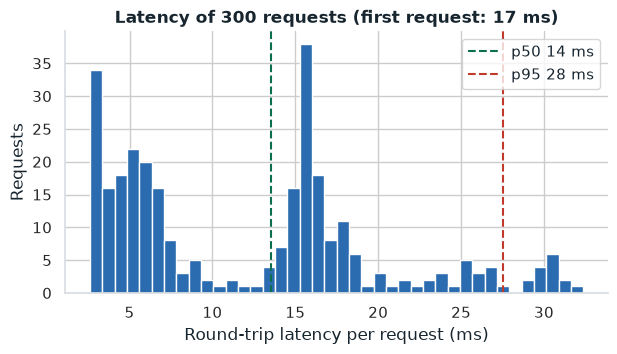

**300 real hours** sent one at a time to this computer (a local copy of the service; it is not deployed to the cloud yet): first request **17 ms**, then a median of **14 ms** (95th percentile 28 ms, 99th 31 ms) measured from the caller's side; the service's own processing time has a median of 2.4 ms. Errors: 0 (0.0%). Every answer matched the model in this notebook to within 2.2e-03 vehicles per hour. These figures are from a copy of the service running on the same computer, so they contain no network delay; over the internet, expect tens to hundreds of milliseconds more, and a first request of a second or more when the platform has to start a fresh instance (a cold start).

GET /api/v1/metrics -> {"scope": "this instance only (serverless instances are stateless)", "uptime_s": 763.8, "requests": 314, "errors": 0, "rejected_requests": 4, "predictions": 529, "api_latency_ms": {"p50": 2.39, "p95": 3.79, "p99": 6.88}}


In [71]:
latency = None
if LIVE:
    latency = replay_requests(SERVICE_URL, f["clean_validation"].head(60 if FAST else 300),
                              served_predictions(f["raw_validation"].head(60 if FAST else 300), meta, onnx_path))
    finish_figure(plot_latency(latency), "monitor_latency", ctx)
    status, metrics_now = call_api("/api/v1/metrics")
    say(f"**{latency['requests']} real hours** sent one at a time to {where}: first request "
        f"**{latency['first_request_ms']:.0f} ms**, then a median of **{latency['warm_p50_ms']:.0f} ms** "
        f"(95th percentile {latency['warm_p95_ms']:.0f} ms, 99th {latency['warm_p99_ms']:.0f} ms) measured from the "
        f"caller's side; the service's own processing time has a median of {latency['server_p50_ms']:.1f} ms. "
        f"Errors: {latency['errors']} ({latency['error_rate']:.1%}). Every answer matched the model in this notebook "
        f"to within {latency['max_abs_diff_vs_offline']:.1e} vehicles per hour. "
        + ("These figures are from a copy of the service running on the same computer, so they contain no network "
           "delay; over the internet, expect tens to hundreds of milliseconds more, and a first request of a second "
           "or more when the platform has to start a fresh instance (a cold start)."
           if "this computer" in where else "The first request includes the platform starting an instance (a cold start)."))
    print("GET /api/v1/metrics ->", json.dumps(metrics_now))
else:
    print("No service reachable: latency not measured in this run.")

### 10.2 Data drift

The population stability index (PSI) compares the distribution of each feature in a later period with the
training years: below 0.1 is stable, above 0.25 is a large shift. It needs no traffic counts, so it can be
computed the day the inputs arrive. Two comparisons: the validation year against the training years, and
the inputs of the test year against the years the final model was trained on. The test year covers January
to September only, so it is compared with the same months of the earlier years; otherwise the missing
autumn would look like a shift in the month.

,feature,type,psi,ks_statistic,ks_pvalue,level
0,clouds_all,numeric,0.2178,0.0640,0.0000,moderate
1,temp_c,numeric,0.0320,0.0453,0.0000,stable
2,month_sin,numeric,0.0203,0.0333,0.0000,stable
3,weather_group,categorical,0.0192,NaN,NaN,stable
4,month,numeric,0.0187,0.0489,0.0000,stable
5,month_cos,numeric,0.0135,0.0271,0.0001,stable


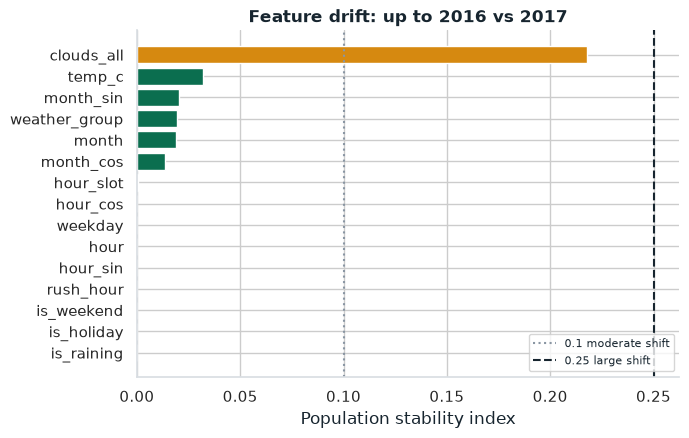

**Validation year against the training years:** of 18 features, 0 shift strongly, 1 moderately and 17 are stable; the largest shift is `clouds_all` (PSI 0.218). **Test year against the same months before:** 1 strongly, 0 moderately; the largest is `clouds_all` (PSI 0.266, large). The calendar features are stable, as they must be when the same months are compared: every year has the same hours and weekdays. The shifts that do appear are in weather columns, partly real (one year is cloudier or wetter than another) and partly an artefact of how they are recorded (the rain amount is missing for whole years, 3.1). The champion reads `clouds_all`, so this is a shift to keep watching; the small importance of the weather (6b) limits the damage, and the calendar-only model is not affected at all.

In [72]:
drift = drift_report(f["X_train"], f["X_validation"], f["cats"])
same_months_before = f["X_trval"][f["clean_trval"]["date_time"].dt.month.isin(test["test_months"]).to_numpy()]
drift_test = drift_report(same_months_before, f["X_test"], f["cats"])
display(drift.head(6).round(4))
finish_figure(plot_drift(drift, f"Feature drift: up to {cfg.split.train_until_year} vs {cfg.split.validation_year}"),
              "monitor_drift", ctx)
used = set(final_model.named_steps["prep"].get_feature_names_out())
levels = drift["level"].value_counts()
top, top_test = drift.iloc[0], drift_test.iloc[0]
levels_test = drift_test["level"].value_counts()
calendar_features = set(features_using_only(CALENDAR_VARIABLES))
say(f"**Validation year against the training years:** of {len(drift)} features, {levels.get('large', 0)} shift "
    f"strongly, {levels.get('moderate', 0)} moderately and {levels.get('stable', 0)} are stable; the largest shift is "
    f"`{top['feature']}` (PSI {top['psi']:.3f}). **Test year against the same months before:** "
    f"{levels_test.get('large', 0)} strongly, {levels_test.get('moderate', 0)} moderately; the largest is "
    f"`{top_test['feature']}` (PSI {top_test['psi']:.3f}, {top_test['level']}). "
    + ("The calendar features are stable, as they must be when the same months are compared: every year has the "
       "same hours and weekdays. " if top["feature"] not in calendar_features and top_test["feature"] not in calendar_features
       else "")
    + "The shifts that do appear are in weather columns, partly real (one year is cloudier or wetter than another) "
      "and partly an artefact of how they are recorded (the rain amount is missing for whole years, 3.1). "
    + (f"A calendar feature (`{top_test['feature']}`) at the top means the two periods do not cover the same hours "
       "(gaps in the series), not that the world has changed."
       if top_test["feature"] in calendar_features else
       f"The champion reads `{top_test['feature']}`, so this is a shift to keep watching; the small importance of "
       "the weather (6b) limits the damage, and the calendar-only model is not affected at all."
       if top_test["feature"] in used else
       f"The deployed model does not read `{top_test['feature']}`, so this shift cannot affect its forecasts."))

### 10.3 Model performance on real data, and the feedback loop

Drift in the inputs is only a warning; what matters is the error once the real counts arrive. The counting
station reports them a little later, so the API has a **feedback endpoint**: the caller posts the count that
was observed, with the id of the prediction it belongs to. The service keeps a running summary of its own
error, and the logged pairs are the labelled data for the next retraining.

The cell below plays this loop with real data: every week of the test year is sent to the service's batch
endpoint with that week's weather, exactly as a client would send it, and the true counts of the most recent
two weeks are then posted back. Without a reachable service, the forecasts of the final model in this
notebook are used, which are the same numbers (8.3).

In [73]:
live_rows = f["clean_test"].reset_index(drop=True)
actual_live = test["frame"]["actual"].to_numpy()
feedback_summary = None
if LIVE:
    served, ids = [], []
    for start in range(0, len(live_rows), 168):
        chunk = live_rows.iloc[start:start + 168]
        status, reply = call_api("/api/v1/predict/batch", {"hours": [to_api_payload(r) for r in chunk.to_dict("records")]},
                                 timeout=60)
        assert status == 200, reply
        served += [p["raw_prediction"] for p in reply["predictions"]]
        ids += [p["prediction_id"] for p in reply["predictions"]]
    pred_live = np.array(served)
    scored_by = "the service"
    recent = min(len(ids), 24 if FAST else 336)
    posted = 0
    for prediction_id, count in zip(ids[-recent:], actual_live[-recent:]):
        status, ack = call_api("/api/v1/feedback", {"prediction_id": prediction_id, "actual_vehicles": int(count)})
        posted += status == 200
    status, feedback_summary = call_api("/api/v1/feedback/summary")
    print(f"{len(pred_live):,} hours of {cfg.split.test_year} predicted through the API, one week per request.")
    print(f"{posted} observed counts posted back, for the hours from {live_rows['date_time'].iloc[-recent]:%d %B %Y}.")
    print("GET /api/v1/feedback/summary (everything this running instance has received so far) ->")
    print(json.dumps(feedback_summary, indent=2))
else:
    pred_live = test["frame"]["champion"].to_numpy()
    scored_by = "the final model in this notebook (no service reachable)"
    print("No service reachable: the feedback loop is not exercised in this run, and the weekly figures below "
          "use the final model in this notebook.")

6,533 hours of 2018 predicted through the API, one week per request.
336 observed counts posted back, for the hours from 17 September 2018.
GET /api/v1/feedback/summary (everything this running instance has received so far) ->
{
  "storage": "memory of this instance only; the request log is the durable record",
  "reports_matched": 336,
  "mae": 189.5,
  "rmse": 275.0,
  "mean_error": 10.2,
  "note": "mean_error is observed minus predicted: positive means the model forecasts too few."
}


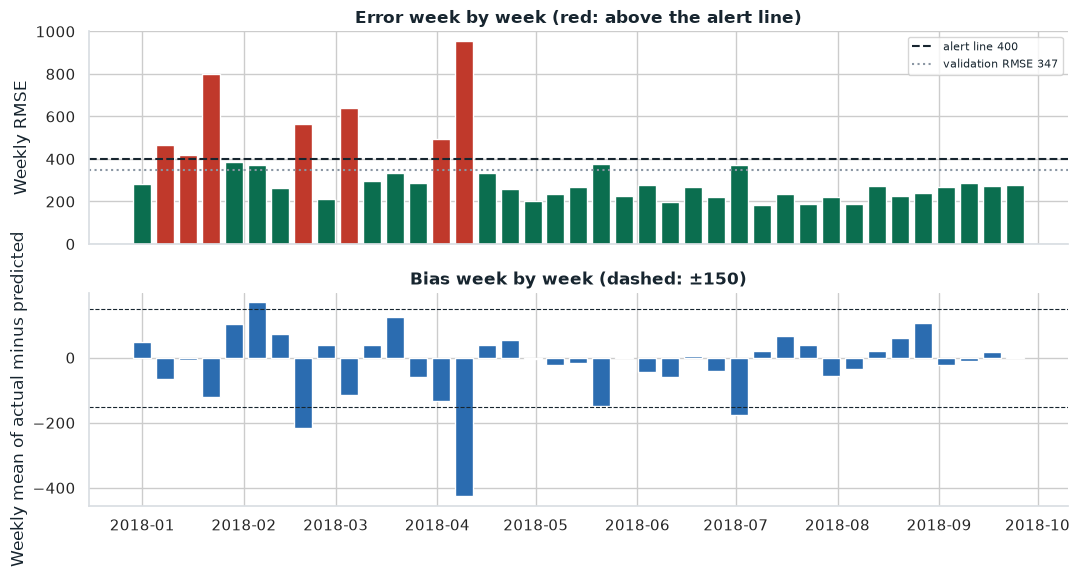

,week,hours,rmse,bias,snow_hours
1,08 January 2018,168,464.0,-67.0,30
2,15 January 2018,167,418.0,-6.0,34
3,22 January 2018,168,801.0,-120.0,46
7,19 February 2018,168,562.0,-215.0,68
9,05 March 2018,166,640.0,-114.0,45
13,02 April 2018,168,493.0,-133.0,70
14,09 April 2018,168,953.0,-425.0,65


**Error week by week**, scored by the service: RMSE 368 over the whole period. The alert line is the validation RMSE plus 15% (400 vehicles per hour). **7 of 39 weeks** are above it; the longest run is **3 week(s) in a row** (the weeks starting 08 January, 15 January, 22 January). The worst weeks start on 09 April (RMSE 953), 22 January (RMSE 801), 05 March (RMSE 640). The weekly bias is beyond ±150 vehicles per hour in 4 week(s). **Snow explains most of it:** the weeks above the line had on average 51 hours of snow each, the weeks below it 5.

In [74]:
alert = 1.15 * champion["val_rmse"]
monitor = pd.DataFrame({"t": live_rows["date_time"], "actual": actual_live, "pred": pred_live})
monitor["error"] = monitor["actual"] - monitor["pred"]
monitor["week"] = monitor["t"].dt.to_period("W-SUN").dt.start_time
monitor["snow"] = (live_rows["weather_main"] == "Snow").to_numpy()
weekly = monitor.groupby("week").agg(hours=("error", "size"), rmse=("error", lambda e: float(np.sqrt(np.mean(e ** 2)))),
                                     bias=("error", "mean"), snow_hours=("snow", "sum")).reset_index()
weekly = weekly[weekly["hours"] >= 24 * 4].reset_index(drop=True)   # a week with under four days of data is not judged
weekly["breach"] = weekly["rmse"] > alert
run = longest = 0
run_end = None
for i, breach in enumerate(weekly["breach"]):
    run = run + 1 if breach else 0
    if run > longest:
        longest, run_end = run, i
run_weeks = weekly.iloc[run_end - longest + 1:run_end + 1] if longest else weekly.iloc[:0]
fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
axes[0].bar(weekly["week"], weekly["rmse"], width=5.5,
            color=[PALETTE["red"] if b else PALETTE["green"] for b in weekly["breach"]])
axes[0].axhline(alert, color=PALETTE["ink"], ls="--", label=f"alert line {alert:.0f}")
axes[0].axhline(champion["val_rmse"], color=PALETTE["grey"], ls=":", label=f"validation RMSE {champion['val_rmse']:.0f}")
axes[0].set(ylabel="Weekly RMSE", title="Error week by week (red: above the alert line)")
axes[0].legend(fontsize=8)
axes[1].bar(weekly["week"], weekly["bias"], width=5.5, color=PALETTE["blue"])
for level in (150, -150):
    axes[1].axhline(level, color=PALETTE["ink"], ls="--", lw=0.8)
axes[1].set(ylabel="Weekly mean of actual minus predicted", title="Bias week by week (dashed: ±150)")
fig.tight_layout()
finish_figure(fig, "monitor_weekly_error", ctx)
overall_live = regression_metrics(actual_live, pred_live)
bias_weeks = int((weekly["bias"].abs() > 150).sum())
above, below = weekly[weekly["breach"]], weekly[~weekly["breach"]]
worst = weekly.sort_values("rmse", ascending=False).head(3)
display(above.assign(week=above["week"].dt.strftime("%d %B %Y"))[["week", "hours", "rmse", "bias", "snow_hours"]].round(0))
say(f"**Error week by week**, scored by {scored_by}: RMSE {overall_live['rmse']:.0f} over the whole period. The alert "
    f"line is the validation RMSE plus 15% ({alert:.0f} vehicles per hour). **{len(above)} of {len(weekly)} weeks** "
    f"are above it; the longest run is **{longest} week(s) in a row**"
    + (f" (the weeks starting {', '.join(f'{w:%d %B}' for w in run_weeks['week'])})" if longest else "")
    + f". The worst weeks start on {', '.join(f'{w:%d %B} (RMSE {r:.0f})' for w, r in zip(worst['week'], worst['rmse']))}. "
    f"The weekly bias is beyond ±150 vehicles per hour in {bias_weeks} week(s)."
    + (f" **Snow explains most of it:** the weeks above the line had on average {above['snow_hours'].mean():.0f} "
       f"hours of snow each, the weeks below it {below['snow_hours'].mean():.0f}." if len(above) and len(below) else ""))

In [75]:
by_month_val = pd.DataFrame(diag["slices"]["by_month"]).set_index("group")["champion_rmse"]
by_month_test = month_test["champion_rmse"]
display(pd.DataFrame({"validation year RMSE": by_month_val, "test year RMSE": by_month_test}).round(0)
        .rename(index=lambda m: MONTHS[int(m) - 1]).T.astype(object).where(lambda d: d.notna(), "no data"))
breaches = [MONTHS[int(m) - 1] for m, v in by_month_test.items() if v > alert]
say(f"**Error month by month** gives the same picture more coarsely. Months of the test year above the alert "
    f"line of {alert:.0f}: **{', '.join(breaches) if breaches else 'none'}**.")

group,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
validation year RMSE,383.0,349.0,350.0,287.0,268.0,292.0,347.0,287.0,327.0,320.0,418.0,479.0
test year RMSE,513.0,399.0,398.0,562.0,277.0,232.0,262.0,227.0,275.0,no data,no data,no data


**Error month by month** gives the same picture more coarsely. Months of the test year above the alert line of 400: **Jan, Apr**.

### 10.4 Retraining policy, and the decision for this period

In [76]:
retrain = longest >= 3
strong_used = [name for name in drift_test[drift_test["level"] == "large"]["feature"]
               if any(u == name or u.endswith("__" + name) for u in used)]
health = (f"{latency['warm_p95_ms']:.0f} ms, {latency['error_rate']:.1%} failures" if latency else "not measured")
health_alert = (("yes" if latency["warm_p95_ms"] > 1000 or latency["error_rate"] > 0.01 else "no") if latency else "n/a")
say(f"""
| Signal | How it is measured | Rule | This period | Triggered? |
|---|---|---|---|---|
| **Error drift** | Weekly RMSE on hours whose real count has arrived through `/api/v1/feedback` | Retrain if it stays above {alert:.0f} (validation RMSE {champion['val_rmse']:.0f} plus 15%) for three weeks in a row | longest run above the line: {longest} week(s) | **{'yes: retrain' if retrain else 'no'}** |
| **Bias** | Weekly mean of actual minus predicted | Investigate if it stays beyond 150 vehicles per hour in one direction: that is a lasting change to the road (new lane, long closure), not noise | {bias_weeks} week(s) beyond the limit | {'investigate' if bias_weeks >= 3 else 'no'} |
| **Input drift** | PSI of every feature the model reads, against the same months of the training data | Investigate any PSI above 0.25 | {', '.join(strong_used) if strong_used else 'none above 0.25'} | {'investigate' if strong_used else 'no'} |
| **Service health** | 95th-percentile latency and error rate, from the request logs | Alert if the 95th percentile exceeds 1 second or errors exceed 1% | {health} | {health_alert} |
| **Calendar** | Every January | Retrain on all years to date, so the latest year is always in the model; add any new public holiday to the list | data now runs to {live_rows['date_time'].max():%B %Y} | due next January |

**Reading the result.** {'The rule fired: the error stayed above the alert line for ' + str(longest) + ' weeks in a row, starting ' + format(run_weeks['week'].iloc[0], '%d %B') + '. Those weeks had ' + format(run_weeks['snow_hours'].sum(), '.0f') + ' hours of snow between them.' if retrain else 'The rule did not fire. Single weeks above the alert line are investigated, not acted on: one bad week is usually a storm, a holiday week or an incident.'}
An alert is a reason to look before acting. Here the cause is the weather, not a change in how people use the
road: the error falls back below the line once the snow has gone, and the weekly bias does not stay on one
side. Retraining would add this winter to the model's history, which helps a little, but it would not teach
the model how much snow fell, because the data does not record it (3.1 and 8.1). The lasting fix is a better
snow input, which is listed under next steps.

**Handling drift when it comes.** Retraining is one command (`traffic-volume all`) and produces a new model
file with a new version; the service picks it up on the next deployment, and the parity check in 8.2 guards
the hand-over. Before replacing the live model, the new one is scored on the most recent months with known
counts and must not be worse than the old one.

**What is not built.** The free serverless platform keeps nothing between restarts, so the feedback summary
lives only as long as one instance and the durable record is the request log. A small hosted database for the
feedback is the next step for a real deployment.
""")


| Signal | How it is measured | Rule | This period | Triggered? |
|---|---|---|---|---|
| **Error drift** | Weekly RMSE on hours whose real count has arrived through `/api/v1/feedback` | Retrain if it stays above 400 (validation RMSE 347 plus 15%) for three weeks in a row | longest run above the line: 3 week(s) | **yes: retrain** |
| **Bias** | Weekly mean of actual minus predicted | Investigate if it stays beyond 150 vehicles per hour in one direction: that is a lasting change to the road (new lane, long closure), not noise | 4 week(s) beyond the limit | investigate |
| **Input drift** | PSI of every feature the model reads, against the same months of the training data | Investigate any PSI above 0.25 | clouds_all | investigate |
| **Service health** | 95th-percentile latency and error rate, from the request logs | Alert if the 95th percentile exceeds 1 second or errors exceed 1% | 28 ms, 0.0% failures | no |
| **Calendar** | Every January | Retrain on all years to date, so the latest year is always in the model; add any new public holiday to the list | data now runs to September 2018 | due next January |

**Reading the result.** The rule fired: the error stayed above the alert line for 3 weeks in a row, starting 08 January. Those weeks had 110 hours of snow between them.
An alert is a reason to look before acting. Here the cause is the weather, not a change in how people use the
road: the error falls back below the line once the snow has gone, and the weekly bias does not stay on one
side. Retraining would add this winter to the model's history, which helps a little, but it would not teach
the model how much snow fell, because the data does not record it (3.1 and 8.1). The lasting fix is a better
snow input, which is listed under next steps.

**Handling drift when it comes.** Retraining is one command (`traffic-volume all`) and produces a new model
file with a new version; the service picks it up on the next deployment, and the parity check in 8.2 guards
the hand-over. Before replacing the live model, the new one is scored on the most recent months with known
counts and must not be worse than the old one.

**What is not built.** The free serverless platform keeps nothing between restarts, so the feedback summary
lives only as long as one instance and the durable record is the request log. A small hosted database for the
feedback is the next step for a real deployment.


## 11. Documentation and reporting

Every result above is saved to one file (`outputs/metrics.json`); the process document, the README, the
model card and the slides are generated from the pipeline's copy of that file, so the same numbers appear
everywhere.

In [77]:
parts = {"audit": audit, "cleaning_log": cleaning_log, "hours": hours_after_cleaning, "split_summary": split_info,
         "holiday_evidence": evidence.to_dict("records"),
         "cats": f["cats"], "nums": f["nums"], "candidates": candidates.to_dict("records"), "lags": lag_info,
         "tuning": tuning, "champion": champion, "diagnostics": diag, "permutation": perm, "shap": shap_imp,
         "study": {"ranking": ranking.reset_index().to_dict("records"), "vif": vif.to_dict("records"),
                   "top1": study["top1"], "top2": study["top2"], "table": study["table"].to_dict("records"),
                   "incremental": study["incremental"].to_dict("records"),
                   "group_ablation": ablation.to_dict("records"), "wet_hours": ablation.attrs["wet_hours"]},
         "test": test, "deployment": deployment}
report = results_report(parts, cfg)
report["monitoring"] = {"service": where if LIVE else None,
                        "latency": {k: v for k, v in latency.items() if k != "client_latencies_ms"} if latency else None,
                        "drift_validation": drift.to_dict("records"), "drift_test": drift_test.to_dict("records")}
save_json(report, ctx.metrics_dir / "metrics.json")
save_json({"service": where if LIVE else None, "scored_by": scored_by,
           "reference_rmse": champion["val_rmse"], "alert_rmse": alert, "overall": overall_live,
           "weekly": weekly.assign(week=weekly["week"].astype(str)).to_dict("records"),
           "weeks_above_alert": int(weekly["breach"].sum()), "longest_run_above_alert": int(longest),
           "feedback": feedback_summary, "retrain": bool(retrain)}, ctx.metrics_dir / "monitoring.json")
print(f"Saved {OUTPUT_DIR.name}/metrics.json and {OUTPUT_DIR.name}/monitoring.json")

Saved outputs/metrics.json and outputs/monitoring.json


In [78]:
say(f"""
### Summary of results

| | |
|---|---|
| Data | {audit['rows']:,} rows, {audit['first_hour'][:10]} to {audit['last_hour'][:10]}; {hours_after_cleaning:,} hours after cleaning |
| Train / validation / test | {split_info['train']['rows']:,} / {split_info['validation']['rows']:,} / {split_info['test']['rows']:,} hours (to 2016 / 2017 / 2018) |
| Champion | {champion['label']}; ONNX file {deployment['model_kb']:,.0f} KB |
| Validation: MSE / RMSE / MAE / R² | {champion['val_mse']:,.0f} / {champion['val_rmse']:.0f} / {champion['val_mae']:.0f} / {champion['val_r2']:.3f} |
| **Test: MSE / RMSE / MAE / R²** | **{cm['mse']:,.0f} / {cm['rmse']:.0f} / {cm['mae']:.0f} / {cm['r2']:.3f}** |
| Test RMSE, 95% interval | {ci['rmse']['low']:.0f} to {ci['rmse']['high']:.0f} |
| Hour-of-week baseline on test: RMSE / R² | {bm['rmse']:.0f} / {bm['r2']:.3f} |
| Champion against the baseline | RMSE {s['rmse_reduction_vs_baseline']:.0%} lower ({pb['low']:.0%} to {pb['high']:.0%}) |
| Champion against the holiday-aware lookup table | RMSE {s['rmse_reduction_vs_holiday_table']:.0%} lower ({ph['low']:.0%} to {ph['high']:.0%}) |
| Without weather (calendar-only model) on test: RMSE / R² | {am['metrics']['rmse']:.0f} / {am['metrics']['r2']:.3f} |
| Univariate / bivariate / champion (test R²) | {test['models']['univariate']['metrics']['r2']:.3f} / {test['models']['bivariate']['metrics']['r2']:.3f} / {cm['r2']:.3f} |
| Success criteria | R² ≥ {cfg.success.r2}: {'met' if s['r2_target_met'] else 'not met'} (so does the baseline); beats the baseline: {'yes' if s['beats_baseline'] else 'no'} |
| Test year scored | twice (first evaluation: R² {fe['test_r2']:.3f}, RMSE {fe['test_rmse']:.0f}); see 8.1 |

### What the result means

Traffic on this road is mostly a matter of the clock. The hour alone explains about four fifths of the
variance, the hour and the weekday together about 94%, and a lookup table of those two is already within
{bm['rmse']:.0f} vehicles per hour. What a model adds on top is knowledge of the quiet holidays and of the
season, and a finer reading of how the daily shape changes. That is worth {s['rmse_reduction_vs_baseline']:.0%} of
the baseline's error, most of it on holidays, and {s['rmse_reduction_vs_holiday_table']:.0%} over a table that
already knows the holidays. The weather, which the dataset was built around, accounts for
{abs(pa['point']):.1%} of the error when it is known exactly and for nothing when it is not; and the hours the
model gets most wrong are snow hours.

### Limitations

- **One counting station, one direction, six years.** Nothing here says how the model would do on another road.
- **The test year is January to September of one year**, without the hardest quarter; a full year would
  probably score somewhat worse (8.1). The test year has also been scored twice (8.1).
- **Unusual days are invisible to the model.** The day after Thanksgiving, the days between Christmas and New
  Year, incidents, closures and heavy snow cause the largest errors (6.4). Only six holidays are known to it.
- **Thin training years.** 2014 and 2015 have about half their hours; the learning curve (6.3) shows what the
  missing history costs.
- **Weather is observed, not forecast.** The headline test RMSE of {cm['rmse']:.0f} assumes the weather of the
  hour is known exactly. With no weather knowledge the figure is {am['metrics']['rmse']:.0f} (calendar-only
  model); a real forecast lies between the two.
- **Snow.** {pd.DataFrame(test['slices']['by_weather']).set_index('group').loc['Snow', 'share_of_sq_error']:.0%} of the test error comes
  from the {weather_test.loc['Snow', 'hours'] / weather_test['hours'].sum():.0%} of hours with snow, and the data
  does not record how much snow fell.
- **The model does not extrapolate.** A new lane, a new interchange or a lasting change in commuting habits
  would shift the whole pattern, and the model would be wrong until retrained (10.4).
- **Monitoring is demonstrated, not operated:** latency was measured on {'a local copy of the service' if (LIVE and 'this computer' in where) else 'the service' if LIVE else 'no running service in this run'},
  and feedback is kept in memory only.

### What I would do next

1. **A real-time version** that adds the counts of the previous hour and day: the experiment in Section 5
   shows the error falling from {r[0]:.0f} to {r[3]:.0f} for a next-hour forecast.
2. **A richer calendar:** the day after Thanksgiving, the Christmas to New Year week, school holidays and
   large local events, which account for most of the worst days.
3. **Prediction intervals** (quantile regression), so that a planner sees a range for each hour, not one number.
4. **More recent data** and a rolling re-evaluation, one year at a time, to see how fast the model ages.
5. **Durable feedback storage** and a scheduled run of the monitoring section (10).
""")


### Summary of results

| | |
|---|---|
| Data | 48,204 rows, 2012-10-02 to 2018-09-30; 40,518 hours after cleaning |
| Train / validation / test | 25,272 / 8,713 / 6,533 hours (to 2016 / 2017 / 2018) |
| Champion | hgb, tuned, all inputs; ONNX file 139 KB |
| Validation: MSE / RMSE / MAE / R² | 120,687 / 347 / 228 / 0.969 |
| **Test: MSE / RMSE / MAE / R²** | **135,400 / 368 / 221 / 0.965** |
| Test RMSE, 95% interval | 312 to 427 |
| Hour-of-week baseline on test: RMSE / R² | 468 / 0.944 |
| Champion against the baseline | RMSE 21% lower (9% to 33%) |
| Champion against the holiday-aware lookup table | RMSE 7% lower (4% to 10%) |
| Without weather (calendar-only model) on test: RMSE / R² | 377 / 0.963 |
| Univariate / bivariate / champion (test R²) | 0.787 / 0.944 / 0.965 |
| Success criteria | R² ≥ 0.9: met (so does the baseline); beats the baseline: yes |
| Test year scored | twice (first evaluation: R² 0.964, RMSE 376); see 8.1 |

### What the result means

Traffic on this road is mostly a matter of the clock. The hour alone explains about four fifths of the
variance, the hour and the weekday together about 94%, and a lookup table of those two is already within
468 vehicles per hour. What a model adds on top is knowledge of the quiet holidays and of the
season, and a finer reading of how the daily shape changes. That is worth 21% of
the baseline's error, most of it on holidays, and 7% over a table that
already knows the holidays. The weather, which the dataset was built around, accounts for
2.5% of the error when it is known exactly and for nothing when it is not; and the hours the
model gets most wrong are snow hours.

### Limitations

- **One counting station, one direction, six years.** Nothing here says how the model would do on another road.
- **The test year is January to September of one year**, without the hardest quarter; a full year would
  probably score somewhat worse (8.1). The test year has also been scored twice (8.1).
- **Unusual days are invisible to the model.** The day after Thanksgiving, the days between Christmas and New
  Year, incidents, closures and heavy snow cause the largest errors (6.4). Only six holidays are known to it.
- **Thin training years.** 2014 and 2015 have about half their hours; the learning curve (6.3) shows what the
  missing history costs.
- **Weather is observed, not forecast.** The headline test RMSE of 368 assumes the weather of the
  hour is known exactly. With no weather knowledge the figure is 377 (calendar-only
  model); a real forecast lies between the two.
- **Snow.** 45% of the test error comes
  from the 8% of hours with snow, and the data
  does not record how much snow fell.
- **The model does not extrapolate.** A new lane, a new interchange or a lasting change in commuting habits
  would shift the whole pattern, and the model would be wrong until retrained (10.4).
- **Monitoring is demonstrated, not operated:** latency was measured on a local copy of the service,
  and feedback is kept in memory only.

### What I would do next

1. **A real-time version** that adds the counts of the previous hour and day: the experiment in Section 5
   shows the error falling from 346 to 241 for a next-hour forecast.
2. **A richer calendar:** the day after Thanksgiving, the Christmas to New Year week, school holidays and
   large local events, which account for most of the worst days.
3. **Prediction intervals** (quantile regression), so that a planner sees a range for each hour, not one number.
4. **More recent data** and a rolling re-evaluation, one year at a time, to see how fast the model ages.
5. **Durable feedback storage** and a scheduled run of the monitoring section (10).
